In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import pearsonr, spearmanr

In [2]:
file_path = Path(r"D:\Project_Github\gold assisstant\dataset\datset a gold price\gold_data_cleaned.csv")


In [3]:
df = pd.read_csv(file_path)

In [4]:
df.shape

(24519, 22)

In [5]:
df.columns.tolist()

['date',
 'time',
 'session',
 'ornament_buy',
 'ornament_sell',
 'bar_buy',
 'bar_sell',
 'gold_spot',
 'thb_usd',
 'change',
 'timestamp',
 'price_changed',
 'valid_price_pair',
 'prev_bar_buy',
 'bar_buy_change',
 'prev_bar_buy_all',
 'bar_buy_change_all',
 'is_first_session',
 'gold_spot_clean',
 'thb_usd_clean',
 'data_quality_flag',
 'cleaning_note']

In [6]:
df.head()

,date,time,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change,...,valid_price_pair,prev_bar_buy,bar_buy_change,prev_bar_buy_all,bar_buy_change_all,is_first_session,gold_spot_clean,thb_usd_clean,data_quality_flag,cleaning_note
0,2006-05-01,09:30:00,1,11279.04,11950.0,11450.0,11550.0,648.64,37.33,NaN,...,False,NaN,NaN,NaN,NaN,True,648.64,37.33,original,NaN
1,2006-05-02,09:30:00,1,11339.68,12000.0,11500.0,11600.0,656.25,37.61,50.0,...,False,NaN,NaN,11450.0,50.0,True,656.25,37.61,original,NaN
2,2006-05-02,11:50:00,2,11385.16,12050.0,11550.0,11650.0,657.05,NaN,50.0,...,True,11500.0,50.0,11500.0,50.0,False,657.05,NaN,original,NaN
3,2006-05-03,09:30:00,1,11582.24,12250.0,11750.0,11850.0,668.90,37.58,200.0,...,False,NaN,NaN,11550.0,200.0,True,668.90,37.58,original,NaN
4,2006-05-03,10:45:00,2,11733.84,12400.0,11900.0,12000.0,675.90,37.61,150.0,...,True,11750.0,150.0,11750.0,150.0,False,675.90,37.61,original,NaN


In [7]:
df.tail()

,date,time,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change,...,valid_price_pair,prev_bar_buy,bar_buy_change,prev_bar_buy_all,bar_buy_change_all,is_first_session,gold_spot_clean,thb_usd_clean,data_quality_flag,cleaning_note
24514,2026-10-13,10:13:00,4,64930.28,67250.0,66250.0,66450.0,4179.0,33.59,50.0,...,True,66200.0,50.0,66200.0,50.0,False,4179.0,33.59,original,NaN
24515,2026-10-13,10:27:00,5,64975.76,67300.0,66300.0,66500.0,4182.0,33.59,50.0,...,True,66250.0,50.0,66250.0,50.0,False,4182.0,33.59,original,NaN
24516,2026-10-13,11:03:00,6,65021.24,67350.0,66350.0,66550.0,4188.0,33.58,50.0,...,True,66300.0,50.0,66300.0,50.0,False,4188.0,33.58,original,NaN
24517,2026-10-13,11:25:00,7,65066.72,67400.0,66400.0,66600.0,4191.0,33.58,50.0,...,True,66350.0,50.0,66350.0,50.0,False,4191.0,33.58,original,NaN
24518,2026-10-13,12:09:00,8,65172.84,67500.0,66500.0,66700.0,4197.0,33.58,100.0,...,True,66400.0,100.0,66400.0,100.0,False,4197.0,33.58,original,NaN


In [8]:
df.dtypes.astype(str)

date                      str
time                      str
session                 int64
ornament_buy          float64
ornament_sell         float64
bar_buy               float64
bar_sell              float64
gold_spot             float64
thb_usd               float64
change                float64
timestamp                 str
price_changed            bool
valid_price_pair         bool
prev_bar_buy          float64
bar_buy_change        float64
prev_bar_buy_all      float64
bar_buy_change_all    float64
is_first_session         bool
gold_spot_clean       float64
thb_usd_clean         float64
data_quality_flag         str
cleaning_note             str
dtype: str

In [9]:
df.notna().sum()

date                  24519
time                  24519
session               24519
ornament_buy          24519
ornament_sell         24519
bar_buy               24519
bar_sell              24519
gold_spot             23971
thb_usd               23723
change                24518
timestamp             24519
price_changed         24519
valid_price_pair      24519
prev_bar_buy          18258
bar_buy_change        18258
prev_bar_buy_all      24518
bar_buy_change_all    24518
is_first_session      24519
gold_spot_clean       23965
thb_usd_clean         23718
data_quality_flag     24519
cleaning_note             9
dtype: int64

In [10]:
df.isna().sum()

date                      0
time                      0
session                   0
ornament_buy              0
ornament_sell             0
bar_buy                   0
bar_sell                  0
gold_spot               548
thb_usd                 796
change                    1
timestamp                 0
price_changed             0
valid_price_pair          0
prev_bar_buy           6261
bar_buy_change         6261
prev_bar_buy_all          1
bar_buy_change_all        1
is_first_session          0
gold_spot_clean         554
thb_usd_clean           801
data_quality_flag         0
cleaning_note         24510
dtype: int64

In [11]:
(df.isna().mean()*100).round(3)

date                   0.000
time                   0.000
session                0.000
ornament_buy           0.000
ornament_sell          0.000
bar_buy                0.000
bar_sell               0.000
gold_spot              2.235
thb_usd                3.246
change                 0.004
timestamp              0.000
price_changed          0.000
valid_price_pair       0.000
prev_bar_buy          25.535
bar_buy_change        25.535
prev_bar_buy_all       0.004
bar_buy_change_all     0.004
is_first_session       0.000
gold_spot_clean        2.259
thb_usd_clean          3.267
data_quality_flag      0.000
cleaning_note         99.963
dtype: float64

In [12]:
df.nunique(dropna=True)

date                   6261
time                    730
session                 106
ornament_buy           1501
ornament_sell          1325
bar_buy                1320
bar_sell               1321
gold_spot              6763
thb_usd                 948
change                   71
timestamp             24511
price_changed             2
valid_price_pair          2
prev_bar_buy           1303
bar_buy_change           31
prev_bar_buy_all       1320
bar_buy_change_all       72
is_first_session          2
gold_spot_clean        6761
thb_usd_clean           947
data_quality_flag         2
cleaning_note             9
dtype: int64

ยังมีค่า NaN อยู่

In [13]:
# แปลงวันที่และเวลา จาก str เป็น date time
df["date_parsed"] = pd.to_datetime(
    df["date"], errors="coerce"
).dt.normalize()

df["time_parsed"] = pd.to_timedelta(
    df["time"].astype(str), errors="coerce"
)

df["timestamp_parsed"] = (
    df["date_parsed"] + df["time_parsed"]
)

In [14]:
df["timestamp_parsed"]

0       2006-05-01 09:30:00
1       2006-05-02 09:30:00
2       2006-05-02 11:50:00
3       2006-05-03 09:30:00
4       2006-05-03 10:45:00
                ...        
24514   2026-10-13 10:13:00
24515   2026-10-13 10:27:00
24516   2026-10-13 11:03:00
24517   2026-10-13 11:25:00
24518   2026-10-13 12:09:00
Name: timestamp_parsed, Length: 24519, dtype: datetime64[us]

In [15]:
print("Invalid dates:", df["date_parsed"].isna().sum())
print("Invalid times:", df["time_parsed"].isna().sum())

Invalid dates: 0
Invalid times: 0


In [16]:
print("Start:", df["timestamp_parsed"].min())
print("End:  ", df["timestamp_parsed"].max())

Start: 2006-05-01 09:30:00
End:   2026-10-13 12:09:00


In [17]:
#ค้นหา timestamp ที่ซ้ำกัน
duplicate_mask = df["timestamp_parsed"].duplicated(keep=False)

duplicate_rows = df.loc[duplicate_mask].sort_values(
    ["timestamp_parsed", "session"]
)

In [18]:
print("Rows belonging to duplicate timestamp groups:", len(duplicate_rows))

print(
    "Number of duplicate timestamp groups:",
    duplicate_rows["timestamp_parsed"].nunique()
)

print(
    "Extra rows beyond one per timestamp:",
    df["timestamp_parsed"].duplicated().sum()
)

Rows belonging to duplicate timestamp groups: 16
Number of duplicate timestamp groups: 8
Extra rows beyond one per timestamp: 8


In [19]:
df["timestamp_parsed"].duplicated().sum()

np.int64(8)

In [20]:
cols_to_review = [
    "date", "time", "session",
    "bar_buy", "bar_sell",
    "gold_spot", "thb_usd", "change",
    "timestamp_parsed"
]

display(duplicate_rows[cols_to_review])

,date,time,session,bar_buy,bar_sell,gold_spot,thb_usd,change,timestamp_parsed
126,2006-07-18,14:40:00,1,11750.0,11850.0,652.2,38.18,-400.0,2006-07-18 14:40:00
127,2006-07-18,14:40:00,2,11700.0,11800.0,647.8,38.17,-50.0,2006-07-18 14:40:00
805,2008-03-06,15:28:00,2,14700.0,14800.0,991.0,31.58,50.0,2008-03-06 15:28:00
806,2008-03-06,15:28:00,3,14600.0,14700.0,985.0,31.58,-100.0,2008-03-06 15:28:00
957,2008-05-28,15:35:00,4,13700.0,13800.0,897.5,32.27,-50.0,2008-05-28 15:35:00
958,2008-05-28,15:35:00,5,13800.0,13900.0,908.1,32.27,100.0,2008-05-28 15:35:00
1148,2008-08-30,09:30:00,1,13450.0,13550.0,832.0,34.25,-50.0,2008-08-30 09:30:00
1147,2008-08-30,09:30:00,2,14500.0,14600.0,926.2,33.52,1050.0,2008-08-30 09:30:00
2034,2009-12-17,10:16:00,2,17700.0,17800.0,1126.0,33.25,-150.0,2009-12-17 10:16:00
2035,2009-12-17,10:16:00,3,17800.0,17900.0,1134.0,33.25,100.0,2009-12-17 10:16:00


In [21]:
time_diff = df["timestamp_parsed"].diff()

print("Backward timestamp transitions:", (time_diff < pd.Timedelta(0)).sum())
print("Equal consecutive timestamps:", (time_diff == pd.Timedelta(0)).sum())

Backward timestamp transitions: 0
Equal consecutive timestamps: 8


In [22]:
if not duplicate_rows.empty:
    duplicate_summary = (
        duplicate_rows.groupby("timestamp_parsed")
        .agg(
            row_count=("timestamp_parsed", "size"),
            session_count=("session", "nunique"),
            bar_buy_count=("bar_buy", "nunique"),
            bar_sell_count=("bar_sell", "nunique"),
            gold_spot_count=("gold_spot", "nunique"),
            thb_usd_count=("thb_usd", "nunique")
        )
        .reset_index()
    )

    display(duplicate_summary)

,timestamp_parsed,row_count,session_count,bar_buy_count,bar_sell_count,gold_spot_count,thb_usd_count
0,2006-07-18 14:40:00,2,2,2,2,2,2
1,2008-03-06 15:28:00,2,2,2,2,2,1
2,2008-05-28 15:35:00,2,2,2,2,2,1
3,2008-08-30 09:30:00,2,2,2,2,2,2
4,2009-12-17 10:16:00,2,2,2,2,2,1
5,2009-12-30 09:36:00,2,2,1,1,1,1
6,2009-12-30 15:42:00,2,2,1,1,1,1
7,2011-12-05 00:00:00,2,2,2,2,2,0


In [23]:
# ดูแถวจริงของ timestamp ซ้ำทั้ง 8 กลุ่ม

duplicate_rows = df.loc[
    df["timestamp_parsed"].duplicated(keep=False)
].copy()

cols_to_review = [
    "date",
    "time",
    "session",
    "ornament_buy",
    "ornament_sell",
    "bar_buy",
    "bar_sell",
    "gold_spot",
    "thb_usd",
    "change",
    "timestamp_parsed"
]

display(
    duplicate_rows[cols_to_review]
    .sort_values(["timestamp_parsed", "session"])
    .reset_index(drop=True)
)

,date,time,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change,timestamp_parsed
0,2006-07-18,14:40:00,1,11582.24,12250.0,11750.0,11850.0,652.2,38.18,-400.0,2006-07-18 14:40:00
1,2006-07-18,14:40:00,2,11536.76,12200.0,11700.0,11800.0,647.8,38.17,-50.0,2006-07-18 14:40:00
2,2008-03-06,15:28:00,2,14492.96,15200.0,14700.0,14800.0,991.0,31.58,50.0,2008-03-06 15:28:00
3,2008-03-06,15:28:00,3,14386.84,15100.0,14600.0,14700.0,985.0,31.58,-100.0,2008-03-06 15:28:00
4,2008-05-28,15:35:00,4,13507.56,14200.0,13700.0,13800.0,897.5,32.27,-50.0,2008-05-28 15:35:00
5,2008-05-28,15:35:00,5,13598.52,14300.0,13800.0,13900.0,908.1,32.27,100.0,2008-05-28 15:35:00
6,2008-08-30,09:30:00,1,13249.84,13950.0,13450.0,13550.0,832.0,34.25,-50.0,2008-08-30 09:30:00
7,2008-08-30,09:30:00,2,14295.88,15000.0,14500.0,14600.0,926.2,33.52,1050.0,2008-08-30 09:30:00
8,2009-12-17,10:16:00,2,17449.16,18200.0,17700.0,17800.0,1126.0,33.25,-150.0,2009-12-17 10:16:00
9,2009-12-17,10:16:00,3,17540.12,18300.0,17800.0,17900.0,1134.0,33.25,100.0,2009-12-17 10:16:00


In [24]:
# ารสร้าง timestamp สอดคล้องกับคอลัมน์ต้นฉบับทุกแถวหรือไม่

expected_timestamp = (
    pd.to_datetime(df["date"], errors="coerce")
    + pd.to_timedelta(df["time"].astype(str), errors="coerce")
)

timestamp_check = pd.DataFrame({
    "date": df["date"],
    "time": df["time"],
    "timestamp_original": df["timestamp"],
    "timestamp_parsed": df["timestamp_parsed"],
    "timestamp_reconstructed": expected_timestamp
})

timestamp_check["matches_original"] = (
    pd.to_datetime(timestamp_check["timestamp_original"], errors="coerce")
    == timestamp_check["timestamp_reconstructed"]
)

print("Rows checked:", len(timestamp_check))
print(
    "Rows where reconstructed timestamp differs from original:",
    (~timestamp_check["matches_original"]).sum()
)

display(
    timestamp_check.loc[
        ~timestamp_check["matches_original"]
    ].head(20)
)

Rows checked: 24519
Rows where reconstructed timestamp differs from original: 0


,date,time,timestamp_original,timestamp_parsed,timestamp_reconstructed,matches_original


In [25]:
# ตรวจแถวซ้ำที่ราคาตรงกันทุกฟิลด์

suspected_pairs = [
    ("2009-12-30", "09:36:00"),
    ("2009-12-30", "15:42:00"),
]

compare_cols = [
    "date", "time", "session",
    "ornament_buy", "ornament_sell",
    "bar_buy", "bar_sell",
    "gold_spot", "thb_usd", "change",
    "price_changed", "valid_price_pair",
    "prev_bar_buy", "bar_buy_change",
    "prev_bar_buy_all", "bar_buy_change_all",
    "is_first_session"
]

for date_value, time_value in suspected_pairs:
    pair = df.loc[
        (df["date"] == date_value) &
        (df["time"] == time_value)
    ].sort_values("session")

    print(f"\n{'=' * 60}")
    print(f"Date: {date_value} | Time: {time_value}")
    print(f"Rows found: {len(pair)}")

    display(pair[compare_cols])

    if len(pair) == 2:
        # เปรียบเทียบเฉพาะฟิลด์ราคา โดยไม่รวม session
        price_cols = [
            "ornament_buy", "ornament_sell",
            "bar_buy", "bar_sell",
            "gold_spot", "thb_usd"
        ]

        same_prices = pair[price_cols].iloc[0].equals(
            pair[price_cols].iloc[1]
        )

        print("All displayed price fields identical:", same_prices)


Date: 2009-12-30 | Time: 09:36:00
Rows found: 2


,date,time,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change,price_changed,valid_price_pair,prev_bar_buy,bar_buy_change,prev_bar_buy_all,bar_buy_change_all,is_first_session
2055,2009-12-30,09:36:00,1,17055.0,17800.0,17300.0,17400.0,1094.5,33.4,-150.0,False,False,NaN,NaN,17450.0,-150.0,True
2056,2009-12-30,09:36:00,2,17055.0,17800.0,17300.0,17400.0,1094.5,33.4,0.0,False,True,17300.0,0.0,17300.0,0.0,False


All displayed price fields identical: True

Date: 2009-12-30 | Time: 15:42:00
Rows found: 2


,date,time,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change,price_changed,valid_price_pair,prev_bar_buy,bar_buy_change,prev_bar_buy_all,bar_buy_change_all,is_first_session
2058,2009-12-30,15:42:00,3,16994.36,17750.0,17250.0,17350.0,1091.5,33.4,-50.0,True,True,17250.0,0.0,17250.0,0.0,False
2057,2009-12-30,15:42:00,4,16994.36,17750.0,17250.0,17350.0,1091.5,33.4,0.0,False,True,17300.0,-50.0,17300.0,-50.0,False


All displayed price fields identical: True


In [26]:
# Cell 7: Inspect midnight records and weekend records

df["weekday"] = df["timestamp_parsed"].dt.day_name()
df["hour"] = df["timestamp_parsed"].dt.hour
df["minute"] = df["timestamp_parsed"].dt.minute

midnight_rows = df.loc[
    (df["hour"] == 0) &
    (df["minute"] == 0)
].copy()

print("Records at exactly midnight:", len(midnight_rows))

display(
    midnight_rows[
        [
            "date", "time", "session",
            "bar_buy", "bar_sell",
            "gold_spot", "thb_usd", "change",
            "timestamp_parsed"
        ]
    ].sort_values(["date", "session"])
)

print("\nRecords by weekday:")
display(
    df["weekday"]
      .value_counts()
      .reindex([
          "Monday", "Tuesday", "Wednesday",
          "Thursday", "Friday", "Saturday", "Sunday"
      ])
      .rename("rows")
      .to_frame()
)

Records at exactly midnight: 2


,date,time,session,bar_buy,bar_sell,gold_spot,thb_usd,change,timestamp_parsed
3642,2011-12-05,00:00:00,1,25450.0,25550.0,1748.5,NaN,50.0,2011-12-05
3643,2011-12-05,00:00:00,2,25400.0,25500.0,1744.5,NaN,-50.0,2011-12-05



Records by weekday:


,rows
weekday,
Monday,4566
Tuesday,4703
Wednesday,4653
Thursday,4895
Friday,4628
Saturday,1052
Sunday,22


In [27]:
#ตรวจว่ามีแถวซ้ำทุกคอลัมน์หรือไม่
exact_duplicate_mask = df.duplicated(keep=False)

#ตรวจแถวที่ซ้ำกันในระดับ timestamp + ราคาหลัก
price_columns = [
    "ornament_buy",
    "ornament_sell",
    "bar_buy",
    "bar_sell",
    "gold_spot",
    "thb_usd",
]

price_duplicate_columns = [
    "timestamp_parsed",
    *price_columns,
]

price_duplicate_mask = df.duplicated(
    subset=price_duplicate_columns,
    keep=False,
)

#สรุปผล
print("จำนวนแถวทั้งหมด:", len(df))
print("จำนวนแถวที่เป็น exact duplicate:", int(exact_duplicate_mask.sum()))
print("จำนวนแถวที่ timestamp ซ้ำ:", int(
    df["timestamp_parsed"].duplicated(keep=False).sum()
))
print("จำนวนแถวที่ timestamp และราคาหลักซ้ำ:", int(
    price_duplicate_mask.sum()
))

#แสดงแถวที่ซ้ำกันทุกคอลัมน์
display(
    df.loc[exact_duplicate_mask]
    .sort_values(["timestamp_parsed", "session"])
)

#แสดงแถวที่ timestamp และราคาหลักซ้ำ
display(
    df.loc[price_duplicate_mask, [
        "date", "time", "session",
        *price_columns,
        "change", "price_changed",
        "valid_price_pair", "is_first_session",
        "timestamp_parsed",
    ]].sort_values(["timestamp_parsed", "session"])
)

จำนวนแถวทั้งหมด: 24519
จำนวนแถวที่เป็น exact duplicate: 0
จำนวนแถวที่ timestamp ซ้ำ: 16
จำนวนแถวที่ timestamp และราคาหลักซ้ำ: 4


,date,time,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change,...,gold_spot_clean,thb_usd_clean,data_quality_flag,cleaning_note,date_parsed,time_parsed,timestamp_parsed,weekday,hour,minute


,date,time,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change,price_changed,valid_price_pair,is_first_session,timestamp_parsed
2055,2009-12-30,09:36:00,1,17055.00,17800.0,17300.0,17400.0,1094.5,33.4,-150.0,False,False,True,2009-12-30 09:36:00
2056,2009-12-30,09:36:00,2,17055.00,17800.0,17300.0,17400.0,1094.5,33.4,0.0,False,True,False,2009-12-30 09:36:00
2058,2009-12-30,15:42:00,3,16994.36,17750.0,17250.0,17350.0,1091.5,33.4,-50.0,True,True,False,2009-12-30 15:42:00
2057,2009-12-30,15:42:00,4,16994.36,17750.0,17250.0,17350.0,1091.5,33.4,0.0,False,True,False,2009-12-30 15:42:00


In [28]:
# เก็บข้อมูลต้นฉบับไว้ใน df โดยไม่แก้ไข
# เรียงตามเวลาและ session เพื่อให้ session สูงสุดอยู่ท้ายกลุ่ม

df_eda = (
    df.sort_values(["timestamp_parsed", "session"])
      .drop_duplicates(subset=["timestamp_parsed"], keep="last")
      .copy()
      .sort_values("timestamp_parsed")
      .reset_index(drop=True)
)

# ตรวจผลลัพธ์
print("Original rows:", len(df))
print("Rows after deduplication:", len(df_eda))
print("Rows removed from EDA view:", len(df) - len(df_eda))
print(
    "Remaining duplicate timestamps:",
    df_eda["timestamp_parsed"].duplicated().sum()
)

# ตรวจว่ากฎเก็บ Session ล่าสุดทำงานถูกต้องหรือไม่
display(
    df_eda.loc[
        df_eda["date"].astype(str).isin(
            ["2009-12-30", "2011-12-05"]
        ),
        [
            "date", "time", "session",
            "bar_buy", "bar_sell", "change",
            "timestamp_parsed"
        ]
    ]
)

Original rows: 24519
Rows after deduplication: 24511
Rows removed from EDA view: 8
Remaining duplicate timestamps: 0


,date,time,session,bar_buy,bar_sell,change,timestamp_parsed
2050,2009-12-30,09:36:00,2,17300.0,17400.0,0.0,2009-12-30 09:36:00
2051,2009-12-30,15:42:00,4,17250.0,17350.0,0.0,2009-12-30 15:42:00
3635,2011-12-05,00:00:00,2,25400.0,25500.0,-50.0,2011-12-05 00:00:00


In [29]:
# ตรวจคุณภาพข้อมูลในชุดที่ใช้ทำ EDA
quality_summary = pd.DataFrame({
    "dtype": df_eda.dtypes.astype(str),
    "missing_count": df_eda.isna().sum(),
    "missing_pct": (df_eda.isna().mean() * 100).round(2),
    "unique_count": df_eda.nunique(dropna=True),
})

display(quality_summary)

print("Rows:", len(df_eda))
print("Columns:", len(df_eda.columns))
print("Duplicate timestamps:", df_eda["timestamp_parsed"].duplicated().sum())
print("Date range:", df_eda["timestamp_parsed"].min(), "to", df_eda["timestamp_parsed"].max())


,dtype,missing_count,missing_pct,unique_count
date,str,0,0.00,6261
time,str,0,0.00,730
session,int64,0,0.00,106
ornament_buy,float64,0,0.00,1501
ornament_sell,float64,0,0.00,1325
bar_buy,float64,0,0.00,1320
bar_sell,float64,0,0.00,1321
gold_spot,float64,548,2.24,6762
thb_usd,float64,795,3.24,947
change,float64,1,0.00,71


Rows: 24511
Columns: 28
Duplicate timestamps: 0
Date range: 2006-05-01 09:30:00 to 2026-10-13 12:09:00


In [30]:
# 1) เปรียบเทียบ Missing ของข้อมูลดิบและข้อมูล Clean
missing_comparison = pd.DataFrame({
    "raw_missing": df_eda[
        ["gold_spot", "thb_usd"]
    ].isna().sum(),
    "clean_missing": df_eda[
        ["gold_spot_clean", "thb_usd_clean"]
    ].isna().sum().values,
})

print("=== 1. Raw vs Clean ===")
display(missing_comparison)

# 2) ตรวจว่า prev_bar_buy หายเพราะเป็น session แรกหรือไม่
print("=== 2. prev_bar_buy missing by session type ===")
display(pd.crosstab(
    df_eda["is_first_session"],
    df_eda["prev_bar_buy"].isna(),
    rownames=["is_first_session"],
    colnames=["prev_bar_buy_missing"],
    margins=True,
))

# 3) ตรวจแถวที่ราคาทองหรืออัตราแลกเปลี่ยนใน Clean หาย
print("=== 3. Missing gold spot ===")
display(
    df_eda.loc[
        df_eda["gold_spot_clean"].isna(),
        [
            "date", "time", "session",
            "gold_spot", "gold_spot_clean",
            "data_quality_flag", "cleaning_note",
        ],
    ].head(15)
)

print("=== 4. Missing THB/USD ===")
display(
    df_eda.loc[
        df_eda["thb_usd_clean"].isna(),
        [
            "date", "time", "session",
            "thb_usd", "thb_usd_clean",
            "data_quality_flag", "cleaning_note",
        ],
    ].head(15)
)

# 4) ตรวจแถวที่ตัวแปรการเปลี่ยนแปลงหาย
print("=== 5. Missing change variables ===")
display(
    df_eda.loc[
        df_eda[
            ["change", "prev_bar_buy_all", "bar_buy_change_all"]
        ].isna().any(axis=1),
        [
            "date", "time", "session",
            "bar_buy", "bar_sell", "change",
            "prev_bar_buy_all", "bar_buy_change_all",
        ],
    ]
)

=== 1. Raw vs Clean ===


,raw_missing,clean_missing
gold_spot,548,554
thb_usd,795,800


=== 2. prev_bar_buy missing by session type ===


prev_bar_buy_missing,False,True,All
is_first_session,,,
False,18253,1,18254
True,0,6257,6257
All,18253,6258,24511


=== 3. Missing gold spot ===


,date,time,session,gold_spot,gold_spot_clean,data_quality_flag,cleaning_note
14,2006-05-11,09:30:00,1,NaN,NaN,original,NaN
15,2006-05-11,11:10:00,2,NaN,NaN,original,NaN
16,2006-05-11,11:50:00,3,NaN,NaN,original,NaN
17,2006-05-13,09:30:00,1,NaN,NaN,original,NaN
18,2006-05-13,10:30:00,2,NaN,NaN,original,NaN
63,2006-06-03,09:30:00,1,NaN,NaN,original,NaN
100,2006-06-24,09:15:00,1,NaN,NaN,original,NaN
108,2006-07-01,09:30:00,1,NaN,NaN,original,NaN
207,2006-09-21,09:30:00,1,NaN,NaN,original,NaN
272,2006-12-02,09:30:00,1,NaN,NaN,original,NaN


=== 4. Missing THB/USD ===


,date,time,session,thb_usd,thb_usd_clean,data_quality_flag,cleaning_note
2,2006-05-02,11:50:00,2,NaN,NaN,original,NaN
14,2006-05-11,09:30:00,1,NaN,NaN,original,NaN
15,2006-05-11,11:10:00,2,NaN,NaN,original,NaN
16,2006-05-11,11:50:00,3,NaN,NaN,original,NaN
17,2006-05-13,09:30:00,1,NaN,NaN,original,NaN
18,2006-05-13,10:30:00,2,NaN,NaN,original,NaN
24,2006-05-15,16:30:00,6,NaN,NaN,original,NaN
63,2006-06-03,09:30:00,1,NaN,NaN,original,NaN
100,2006-06-24,09:15:00,1,NaN,NaN,original,NaN
108,2006-07-01,09:30:00,1,NaN,NaN,original,NaN


=== 5. Missing change variables ===


,date,time,session,bar_buy,bar_sell,change,prev_bar_buy_all,bar_buy_change_all
0,2006-05-01,09:30:00,1,11450.0,11550.0,NaN,NaN,NaN


In [31]:
# สรุป Missing สำหรับตัวแปรสำคัญที่อาจใช้ในการวิเคราะห์
key_columns = [
    "bar_buy",
    "bar_sell",
    "gold_spot_clean",
    "thb_usd_clean",
    "change",
    "prev_bar_buy_all",
    "bar_buy_change_all",
]

missing_report = pd.DataFrame({
    "missing_count": df_eda[key_columns].isna().sum(),
    "missing_pct": (
        df_eda[key_columns].isna().mean() * 100
    ).round(2),
    "available_count": df_eda[key_columns].notna().sum(),
})

display(missing_report)

print("EDA rows:", len(df_eda))
print("Missing values will remain NaN unless validated.")

,missing_count,missing_pct,available_count
bar_buy,0,0.00,24511
bar_sell,0,0.00,24511
gold_spot_clean,554,2.26,23957
thb_usd_clean,800,3.26,23711
change,1,0.00,24510
prev_bar_buy_all,1,0.00,24510
bar_buy_change_all,1,0.00,24510


EDA rows: 24511
Missing values will remain NaN unless validated.


ไม่ใช้ mean imputation, forward fill หรือ interpolation กับราคาทองและอัตราแลกเปลี่ยนโดยอัตโนมัติ เพราะอาจสร้างราคาที่ไม่เคยเกิดขึ้นจริง

In [32]:
# ใช้ df_eda ที่จัดการ timestamp ซ้ำแล้ว
df_eda["year"] = df_eda["timestamp_parsed"].dt.year
df_eda["month"] = df_eda["timestamp_parsed"].dt.month

# สรุปข้อมูลแยกตามปีและเดือน
monthly_summary = (
    df_eda.groupby(["year", "month"])
    .agg(
        row_count=("timestamp_parsed", "size"),
        first_date=("timestamp_parsed", "min"),
        last_date=("timestamp_parsed", "max"),
        bar_buy_min=("bar_buy", "min"),
        bar_buy_max=("bar_buy", "max"),
        bar_buy_mean=("bar_buy", "mean"),
        bar_buy_missing=("bar_buy", lambda s: s.isna().sum()),
        gold_spot_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        thb_usd_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
    .reset_index()
)

# คำนวณจำนวน Missing เป็นเปอร์เซ็นต์ภายในแต่ละเดือน
monthly_summary["gold_spot_missing_pct"] = (
    monthly_summary["gold_spot_missing"]
    / monthly_summary["row_count"] * 100
).round(2)

monthly_summary["thb_usd_missing_pct"] = (
    monthly_summary["thb_usd_missing"]
    / monthly_summary["row_count"] * 100
).round(2)

print("จำนวนปี:", monthly_summary["year"].nunique())
print("จำนวน year-month ที่มีข้อมูล:", len(monthly_summary))

# แสดงเดือนล่าสุด 24 เดือน
display(monthly_summary.tail(24).round(3))

จำนวนปี: 21
จำนวน year-month ที่มีข้อมูล: 246


C:\Users\User\AppData\Local\Temp\ipykernel_15320\2898819757.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_summary.tail(24).round(3))


,year,month,row_count,first_date,last_date,bar_buy_min,bar_buy_max,bar_buy_mean,bar_buy_missing,gold_spot_missing,thb_usd_missing,gold_spot_missing_pct,thb_usd_missing_pct
222,2024,11,255,2024-11-01 09:07:00,2024-11-30 09:01:00,42150.0,44150.0,43326.863,0,0,0,0.00,0.00
223,2024,12,140,2024-12-02 09:07:00,2024-12-31 14:07:00,42050.0,43400.0,42677.857,0,0,0,0.00,0.00
224,2025,1,121,2025-01-01 09:02:00,2025-01-31 09:00:00,42450.0,44350.0,43688.843,0,0,0,0.00,0.00
225,2025,2,190,2025-02-01 09:07:00,2025-02-28 16:25:00,44500.0,47350.0,46252.105,0,0,0,0.00,0.00
226,2025,3,169,2025-03-01 09:05:00,2025-03-31 17:18:00,46250.0,50000.0,47747.633,0,0,0,0.00,0.00
227,2025,4,420,2025-04-01 09:02:00,2025-04-30 17:05:00,49000.0,54700.0,51533.214,0,1,0,0.24,0.00
228,2025,5,391,2025-05-01 09:07:00,2025-05-31 09:04:00,49400.0,52750.0,51184.143,0,0,0,0.00,0.00
229,2025,6,247,2025-06-01 09:00:00,2025-06-30 17:04:00,50400.0,52850.0,51693.725,0,0,0,0.00,0.00
230,2025,7,178,2025-07-01 09:01:00,2025-07-31 16:33:00,50750.0,52100.0,51220.225,0,0,0,0.00,0.00
231,2025,8,148,2025-08-01 09:05:00,2025-08-30 09:06:00,51000.0,52500.0,51502.027,0,0,0,0.00,0.00


In [33]:
# ใช้ df_eda ที่จัดการ timestamp ซ้ำแล้ว
df_eda["year"] = df_eda["timestamp_parsed"].dt.year
df_eda["month"] = df_eda["timestamp_parsed"].dt.month

# สรุปข้อมูลแยกตามปีและเดือน
monthly_summary = (
    df_eda.groupby(["year", "month"])
    .agg(
        row_count=("timestamp_parsed", "size"),
        first_date=("timestamp_parsed", "min"),
        last_date=("timestamp_parsed", "max"),
        bar_buy_min=("bar_buy", "min"),
        bar_buy_max=("bar_buy", "max"),
        bar_buy_mean=("bar_buy", "mean"),
        bar_buy_missing=("bar_buy", lambda s: s.isna().sum()),
        gold_spot_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        thb_usd_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
    .reset_index()
)

# คำนวณจำนวน Missing เป็นเปอร์เซ็นต์ภายในแต่ละเดือน
monthly_summary["gold_spot_missing_pct"] = (
    monthly_summary["gold_spot_missing"]
    / monthly_summary["row_count"] * 100
).round(2)

monthly_summary["thb_usd_missing_pct"] = (
    monthly_summary["thb_usd_missing"]
    / monthly_summary["row_count"] * 100
).round(2)

print("จำนวนปี:", monthly_summary["year"].nunique())
print("จำนวน year-month ที่มีข้อมูล:", len(monthly_summary))

# แสดงเดือนล่าสุด 24 เดือน
display(monthly_summary.tail(24).round(3))

จำนวนปี: 21
จำนวน year-month ที่มีข้อมูล: 246


C:\Users\User\AppData\Local\Temp\ipykernel_15320\2898819757.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_summary.tail(24).round(3))


,year,month,row_count,first_date,last_date,bar_buy_min,bar_buy_max,bar_buy_mean,bar_buy_missing,gold_spot_missing,thb_usd_missing,gold_spot_missing_pct,thb_usd_missing_pct
222,2024,11,255,2024-11-01 09:07:00,2024-11-30 09:01:00,42150.0,44150.0,43326.863,0,0,0,0.00,0.00
223,2024,12,140,2024-12-02 09:07:00,2024-12-31 14:07:00,42050.0,43400.0,42677.857,0,0,0,0.00,0.00
224,2025,1,121,2025-01-01 09:02:00,2025-01-31 09:00:00,42450.0,44350.0,43688.843,0,0,0,0.00,0.00
225,2025,2,190,2025-02-01 09:07:00,2025-02-28 16:25:00,44500.0,47350.0,46252.105,0,0,0,0.00,0.00
226,2025,3,169,2025-03-01 09:05:00,2025-03-31 17:18:00,46250.0,50000.0,47747.633,0,0,0,0.00,0.00
227,2025,4,420,2025-04-01 09:02:00,2025-04-30 17:05:00,49000.0,54700.0,51533.214,0,1,0,0.24,0.00
228,2025,5,391,2025-05-01 09:07:00,2025-05-31 09:04:00,49400.0,52750.0,51184.143,0,0,0,0.00,0.00
229,2025,6,247,2025-06-01 09:00:00,2025-06-30 17:04:00,50400.0,52850.0,51693.725,0,0,0,0.00,0.00
230,2025,7,178,2025-07-01 09:01:00,2025-07-31 16:33:00,50750.0,52100.0,51220.225,0,0,0,0.00,0.00
231,2025,8,148,2025-08-01 09:05:00,2025-08-30 09:06:00,51000.0,52500.0,51502.027,0,0,0,0.00,0.00


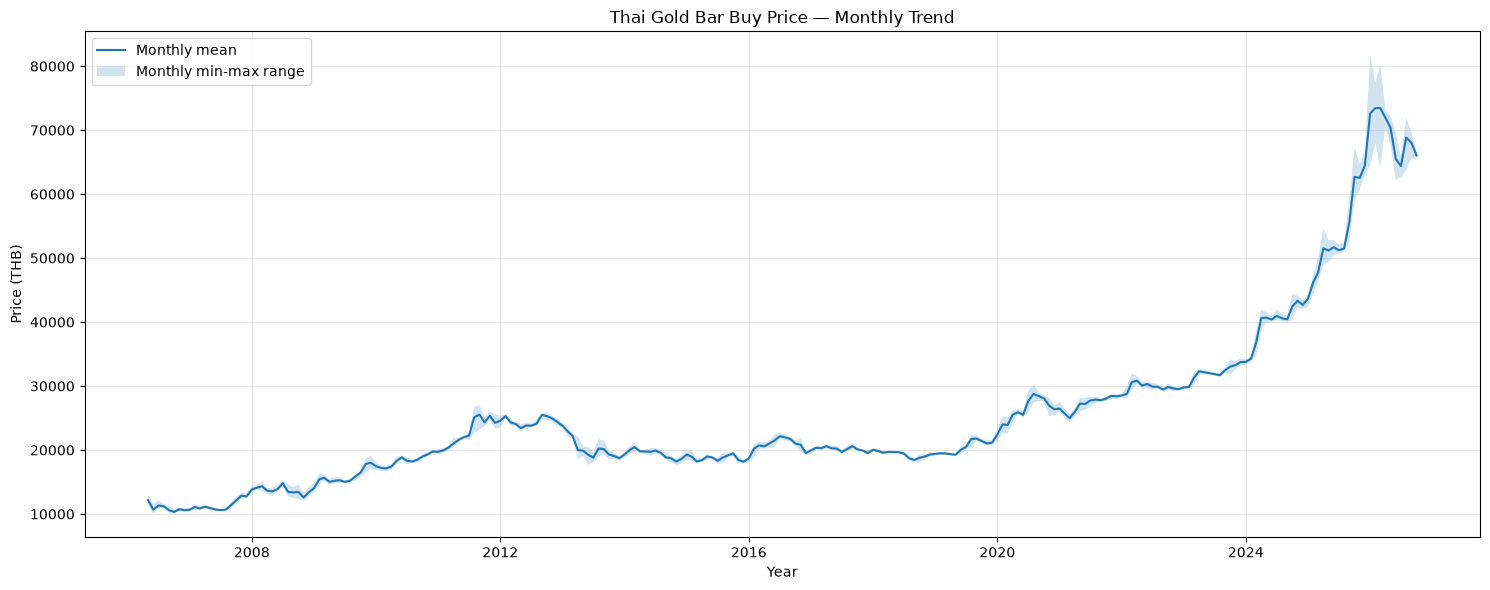

In [34]:
monthly_price = (
    df_eda.set_index("timestamp_parsed")["bar_buy"]
    .resample("MS")
    .agg(["mean", "min", "max"])
)

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(monthly_price.index, monthly_price["mean"],
        label="Monthly mean", linewidth=1.5)
ax.fill_between(
    monthly_price.index,
    monthly_price["min"],
    monthly_price["max"],
    alpha=0.2,
    label="Monthly min-max range"
)

ax.set_title("Thai Gold Bar Buy Price — Monthly Trend")
ax.set_xlabel("Year")
ax.set_ylabel("Price (THB)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:


# สรุปข้อมูลทุกคอลัมน์
summary = pd.DataFrame(index=df.columns)

summary["dtype"] = df.dtypes.astype(str)
summary["count"] = df.count()
summary["missing"] = df.isna().sum()
summary["missing_pct"] = (df.isna().mean() * 100).round(2)
summary["unique"] = df.nunique(dropna=True)

# ค่าสถิติสำหรับคอลัมน์ตัวเลข
numeric_cols = df.select_dtypes(include=[np.number], exclude=["timedelta"]).columns


summary["mean"] = np.nan
summary["std"] = np.nan
summary["min"] = np.nan
summary["25%"] = np.nan
summary["median"] = np.nan
summary["75%"] = np.nan
summary["max"] = np.nan

summary.loc[numeric_cols, "mean"] = df[numeric_cols].mean()
summary.loc[numeric_cols, "std"] = df[numeric_cols].std()
summary.loc[numeric_cols, "min"] = df[numeric_cols].min()
summary.loc[numeric_cols, "25%"] = df[numeric_cols].quantile(0.25)
summary.loc[numeric_cols, "median"] = df[numeric_cols].median()
summary.loc[numeric_cols, "75%"] = df[numeric_cols].quantile(0.75)
summary.loc[numeric_cols, "max"] = df[numeric_cols].max()

display(summary)

,dtype,count,missing,missing_pct,unique,mean,std,min,25%,median,75%,max
date,str,24519,0,0.00,6261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,str,24519,0,0.00,730,NaN,NaN,NaN,NaN,NaN,NaN,NaN
session,int64,24519,0,0.00,106,7.049268,10.067191,1.00,1.00,3.00,8.00,106.00
ornament_buy,float64,24519,0,0.00,1501,37768.218860,20402.077174,9854.00,19889.92,28925.28,61049.32,80211.56
ornament_sell,float64,24519,0,0.00,1325,39174.344386,21038.698436,10500.00,20750.00,30050.00,63200.00,82750.00
bar_buy,float64,24519,0,0.00,1320,38481.514336,20851.638216,10000.00,20200.00,29450.00,62300.00,81850.00
bar_sell,float64,24519,0,0.00,1321,38601.368327,20879.547592,10100.00,20300.00,29550.00,62400.00,81950.00
gold_spot,float64,23971,548,2.24,6763,2515.633273,1385.302766,543.10,1331.50,1896.00,4037.25,33455.00
thb_usd,float64,23723,796,3.25,948,32.942175,1.762650,13.42,31.65,32.75,33.87,38.90
change,float64,24518,1,0.00,71,2.249368,126.783632,-2550.00,-50.00,0.00,50.00,3700.00


# เลือกคอลัมน์ที่จะใช้

| กลุ่ม                   | คอลัมน์                                                                      | เหตุผลที่เก็บไว้                                                                  |
| ----------------------- | ---------------------------------------------------------------------------- | --------------------------------------------------------------------------------- |
| เวลา                    | `timestamp_parsed`                                                           | ใช้ระบุวันและเวลาของข้อมูล โดยไม่ต้องเก็บวันเวลาแยกหลายรูปแบบ                     |
| ลำดับประกาศ             | `session`                                                                    | ทำความเข้าใจลำดับและจำนวนรอบประกาศราคา                                            |
| ราคาทองรูปพรรณ          | `ornament_buy`, `ornament_sell`                                              | สำรวจการกระจายตัวและระดับราคา                                                     |
| ราคาทองแท่ง             | `bar_buy`, `bar_sell`                                                        | ตัวแปรราคาหลักของ Dataset                                                         |
| ข้อมูลตลาดประกอบ        | `gold_spot_clean`, `thb_usd_clean`                                           | ใช้ศึกษาข้อมูล Gold Spot และอัตราแลกเปลี่ยน โดยคงค่าที่ถูกระบุให้เป็น missing ไว้ |
| ค่าเปลี่ยนแปลงจากต้นทาง | `change`                                                                     | เก็บไว้สำรวจ แต่ยังต้องตรวจสอบความหมายก่อนตีความ                                  |
| สถานะข้อมูล             | `price_changed`, `valid_price_pair`, `is_first_session`, `data_quality_flag` | ช่วยให้เข้าใจสถานะของแต่ละ record และตรวจสอบคุณภาพข้อมูล                          |

ส่วนคอลัมน์อย่าง `date`, `time`, `timestamp`, `date_parsed`, `hour` และ `minute` ยังไม่จำเป็นต้องเก็บไว้พร้อมกัน เพราะมีข้อมูลเวลาที่ใช้เป็นหลักอยู่แล้วใน `timestamp_parsed`

ไม่เลือก `prev_bar_buy`, `bar_buy_change`, `prev_bar_buy_all` และ `bar_buy_change_all` ใน DataFrame รอบนี้ เพราะเป็นคอลัมน์ที่ผ่านการคำนวณมาแล้ว เราค่อยตรวจสอบที่มาและความหมายของคอลัมน์เหล่านี้เมื่อจำเป็น

In [36]:
selected_cols = [
    "timestamp_parsed",
    "session",
    "ornament_buy",
    "ornament_sell",
    "bar_buy",
    "bar_sell",
    "gold_spot_clean",
    "thb_usd_clean",
    "change",
    "price_changed",
    "valid_price_pair",
    "is_first_session",
    "data_quality_flag",
]

# ตรวจสอบว่าคอลัมน์ที่ต้องการมีอยู่จริง
missing_cols = [col for col in selected_cols if col not in df.columns]

if missing_cols:
    raise KeyError(f"Columns not found: {missing_cols}")

# สร้าง DataFrame สำหรับ EDA
df_market_eda = (
    df[selected_cols]
    .copy()
    .sort_values(
        ["timestamp_parsed", "session"],
        kind="stable"
    )
    .reset_index(drop=True)
)

print("Shape:", df_market_eda.shape)

display(df_market_eda.head())

Shape: (24519, 13)


,timestamp_parsed,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean,change,price_changed,valid_price_pair,is_first_session,data_quality_flag
0,2006-05-01 09:30:00,1,11279.04,11950.0,11450.0,11550.0,648.64,37.33,NaN,False,False,True,original
1,2006-05-02 09:30:00,1,11339.68,12000.0,11500.0,11600.0,656.25,37.61,50.0,False,False,True,original
2,2006-05-02 11:50:00,2,11385.16,12050.0,11550.0,11650.0,657.05,NaN,50.0,True,True,False,original
3,2006-05-03 09:30:00,1,11582.24,12250.0,11750.0,11850.0,668.90,37.58,200.0,False,False,True,original
4,2006-05-03 10:45:00,2,11733.84,12400.0,11900.0,12000.0,675.90,37.61,150.0,True,True,False,original


In [37]:
overview = pd.DataFrame({
    "dtype": df_market_eda.dtypes.astype(str),
    "non_missing": df_market_eda.notna().sum(),
    "missing": df_market_eda.isna().sum(),
    "missing_pct": (
        df_market_eda.isna().mean() * 100
    ).round(2),
    "unique": df_market_eda.nunique(dropna=True),
})

display(overview)

,dtype,non_missing,missing,missing_pct,unique
timestamp_parsed,datetime64[us],24519,0,0.00,24511
session,int64,24519,0,0.00,106
ornament_buy,float64,24519,0,0.00,1501
ornament_sell,float64,24519,0,0.00,1325
bar_buy,float64,24519,0,0.00,1320
bar_sell,float64,24519,0,0.00,1321
gold_spot_clean,float64,23965,554,2.26,6761
thb_usd_clean,float64,23718,801,3.27,947
change,float64,24518,1,0.00,71
price_changed,bool,24519,0,0.00,2


In [38]:
numeric_cols = [
    "session",
    "ornament_buy",
    "ornament_sell",
    "bar_buy",
    "bar_sell",
    "gold_spot_clean",
    "thb_usd_clean",
    "change",
]

stats = (
    df_market_eda[numeric_cols]
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
    .T
    .round(2)
)

display(stats)

,count,mean,std,min,5%,25%,50%,75%,95%,max
session,24519.0,7.05,10.07,1.00,1.00,1.00,3.00,8.00,26.0,106.00
ornament_buy,24519.0,37768.22,20402.08,9854.00,13795.60,19889.92,28925.28,61049.32,71252.0,80211.56
ornament_sell,24519.0,39174.34,21038.70,10500.00,14500.00,20750.00,30050.00,63200.00,73700.0,82750.00
bar_buy,24519.0,38481.51,20851.64,10000.00,14000.00,20200.00,29450.00,62300.00,72700.0,81850.00
bar_sell,24519.0,38601.37,20879.55,10100.00,14100.00,20300.00,29550.00,62400.00,72900.0,81950.00
gold_spot_clean,23965.0,2514.50,1370.82,543.10,901.00,1331.50,1896.00,4037.00,4831.9,5588.00
thb_usd_clean,23718.0,32.94,1.76,28.61,30.24,31.65,32.75,33.86,36.3,38.90
change,24518.0,2.25,126.78,-2550.00,-100.00,-50.00,0.00,50.00,100.0,3700.00


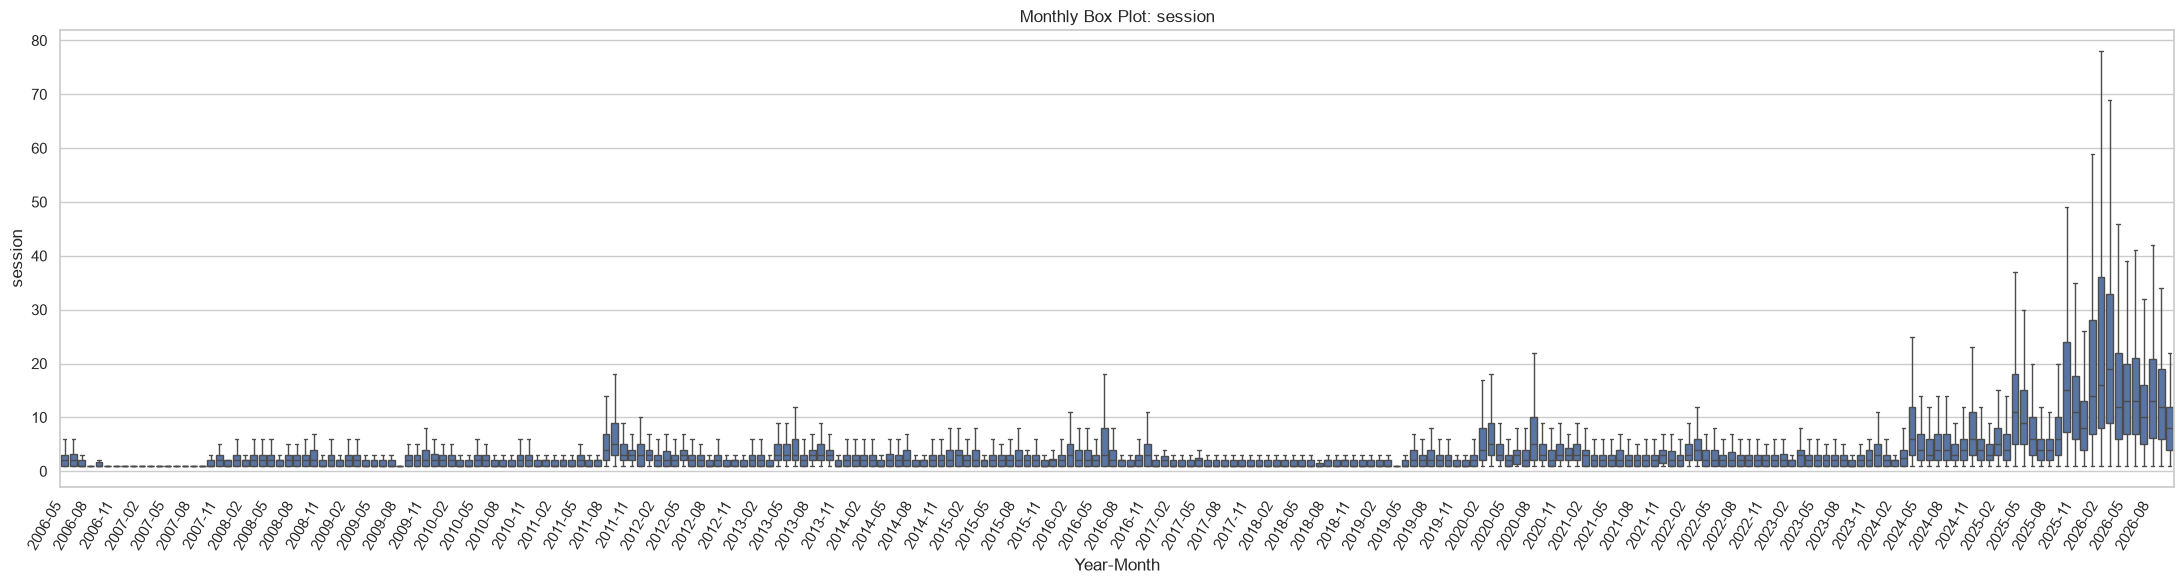

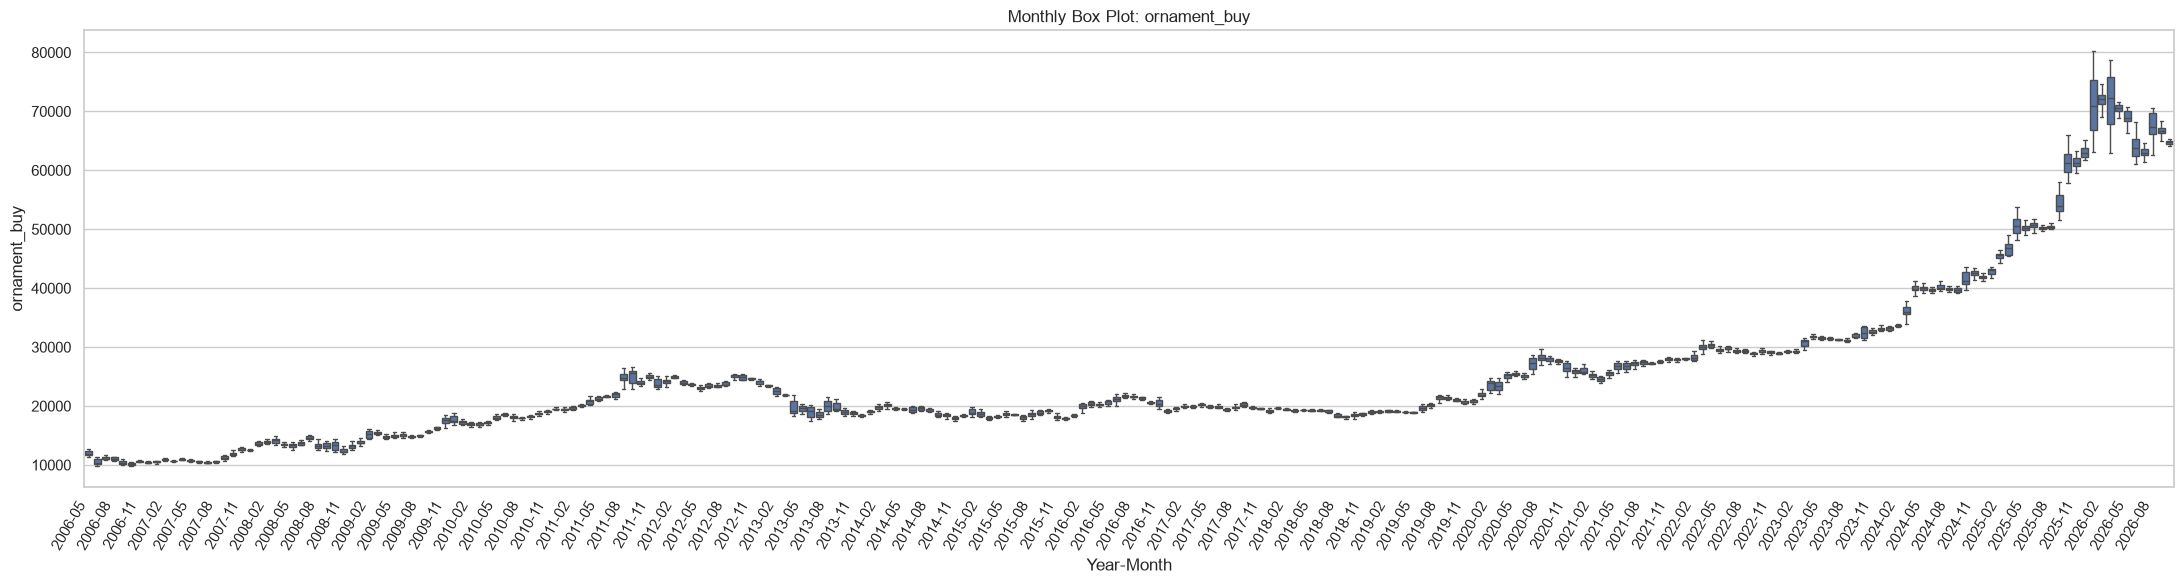

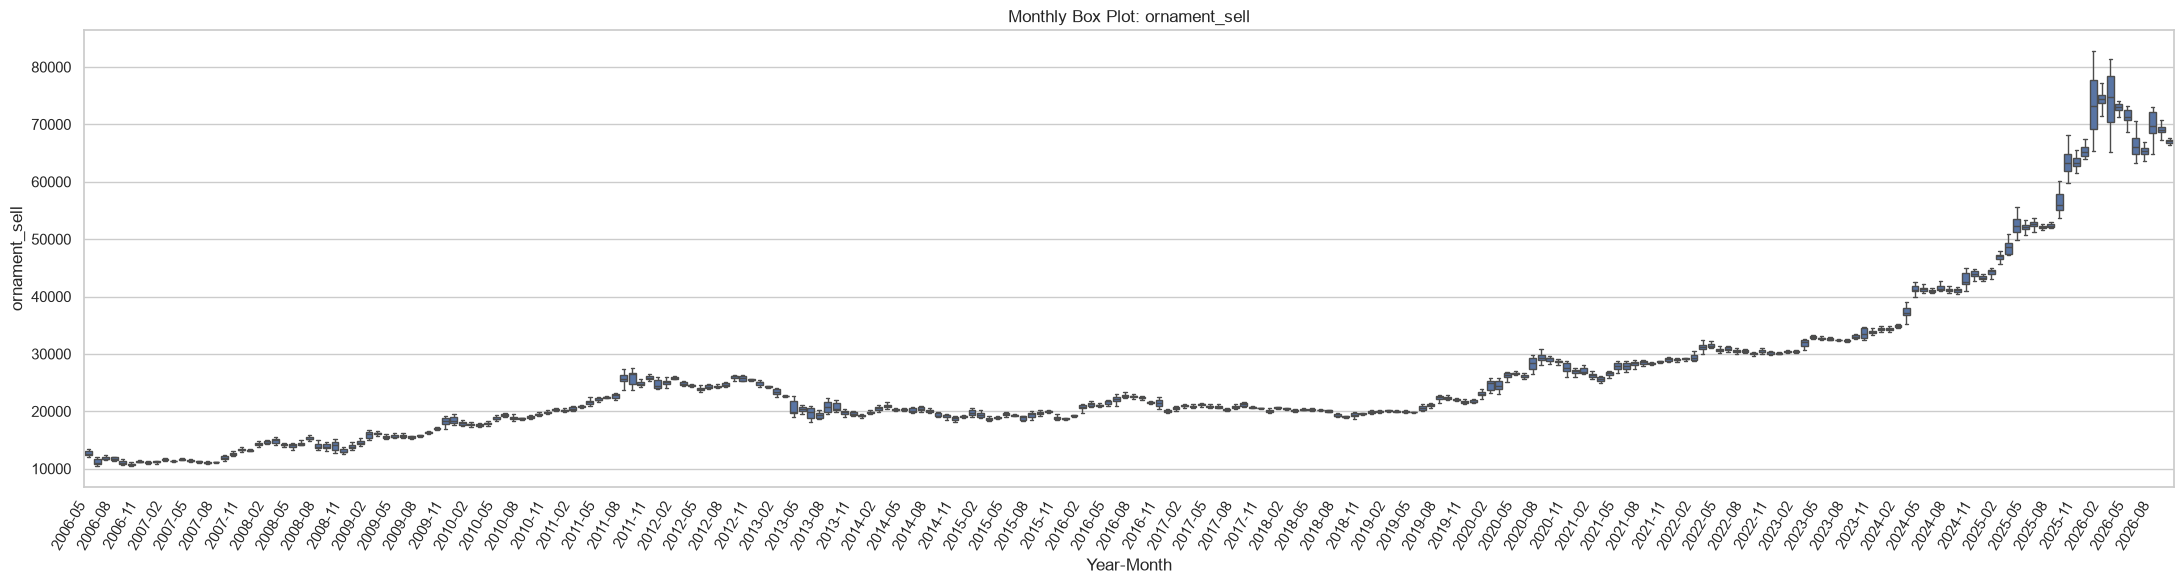

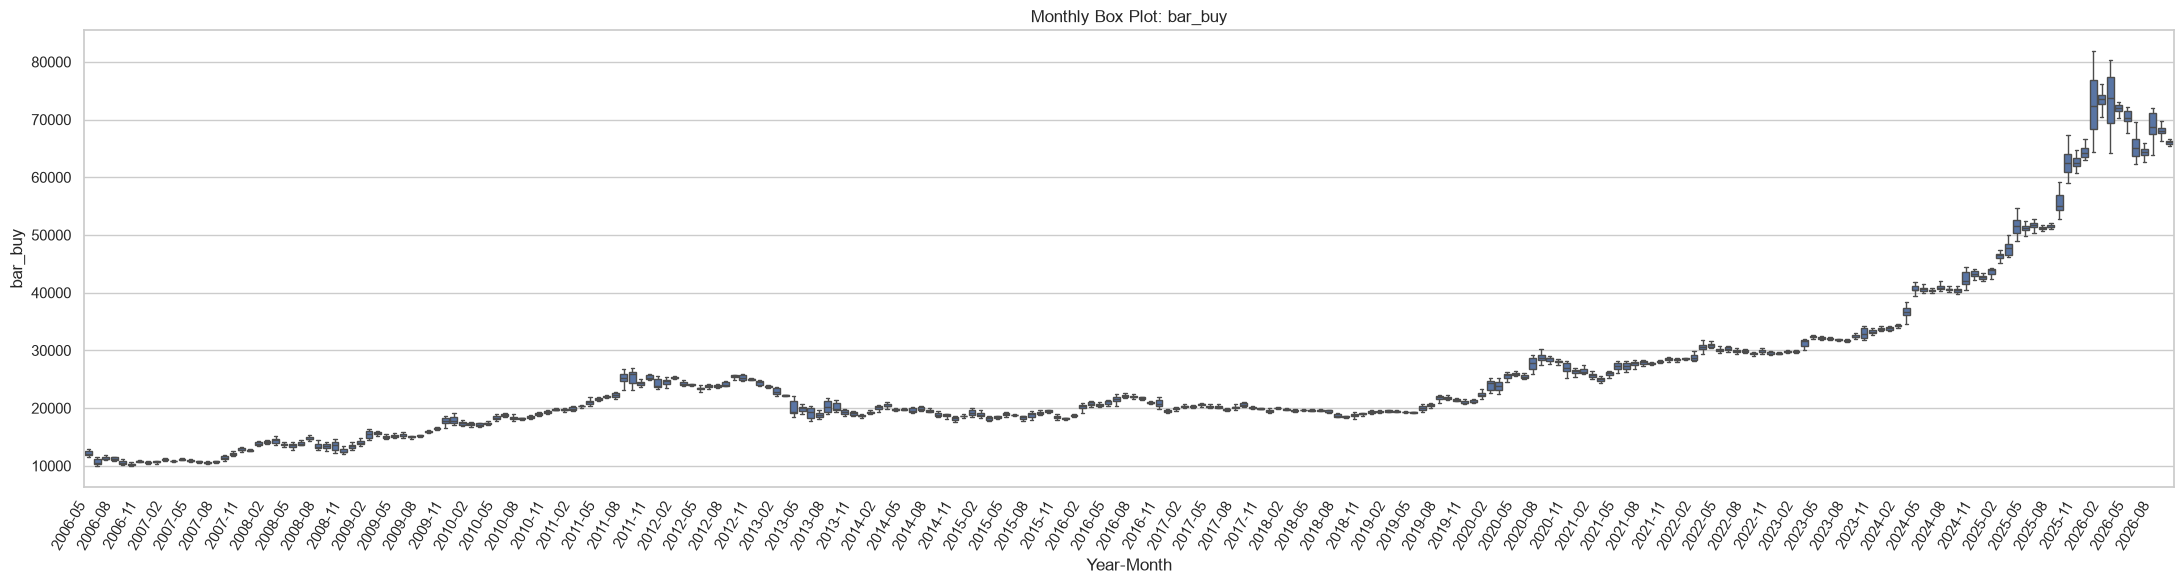

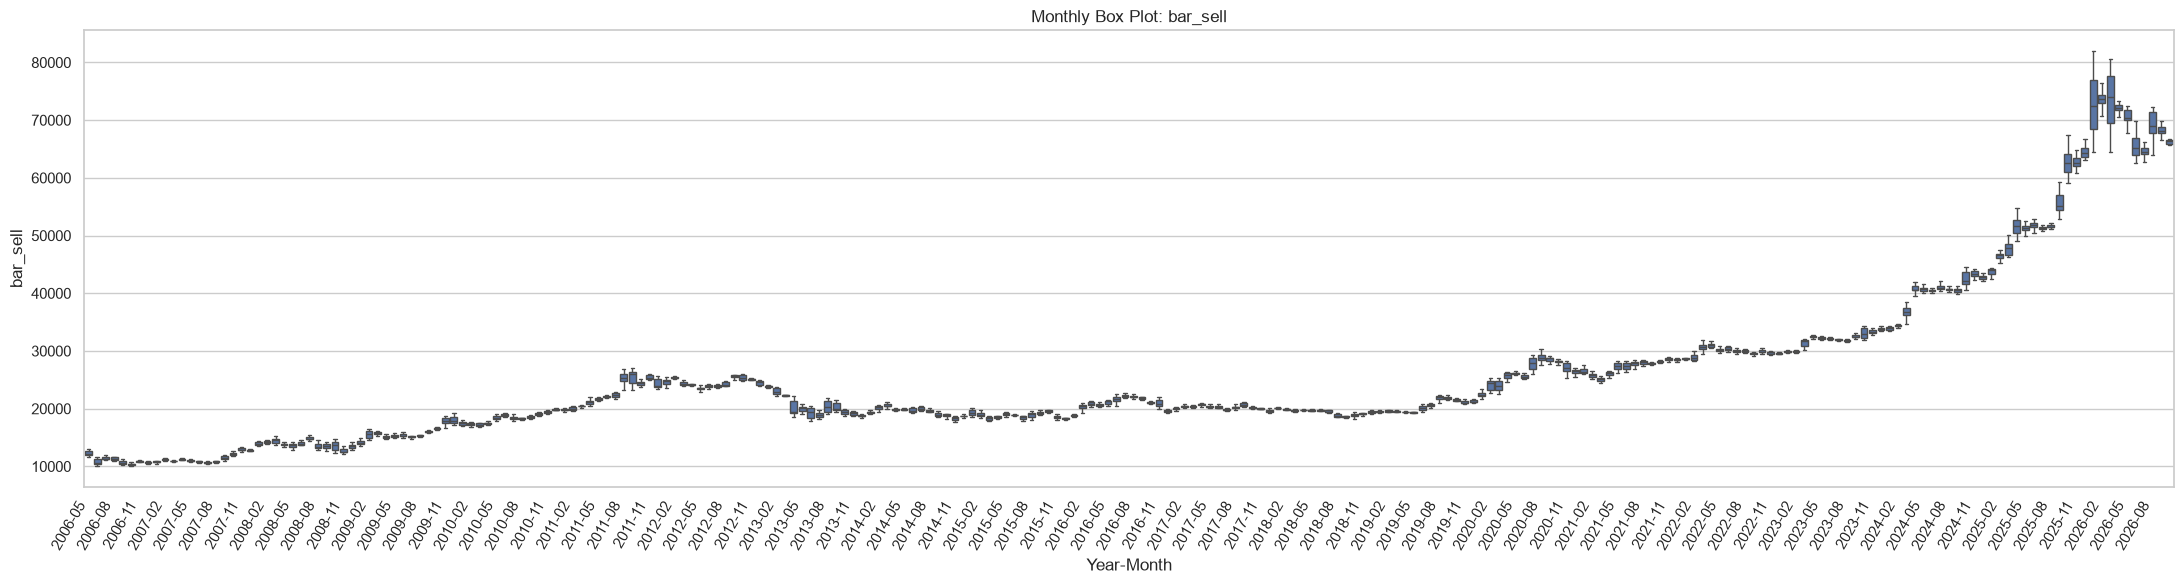

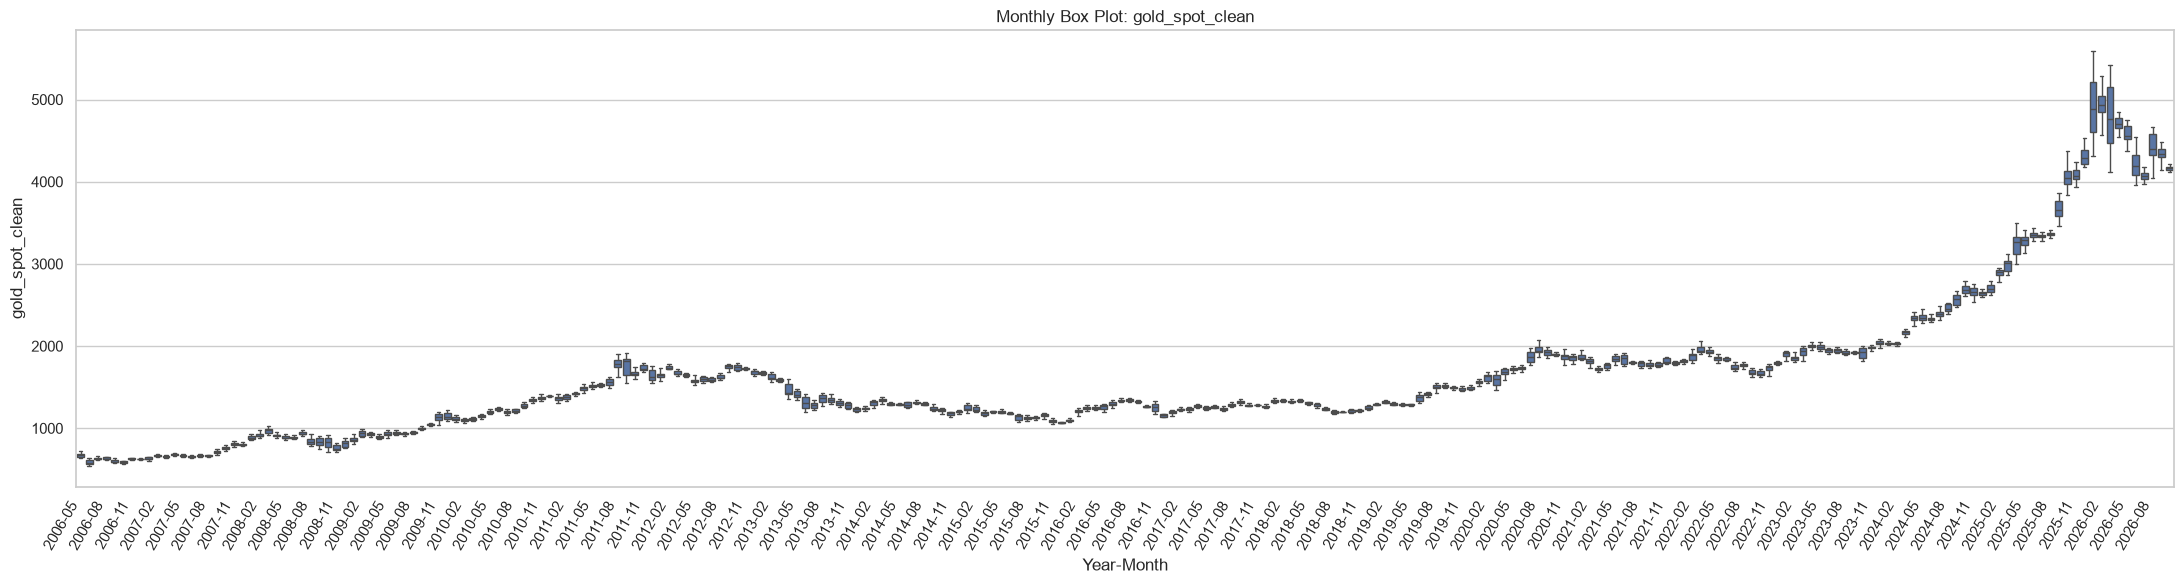

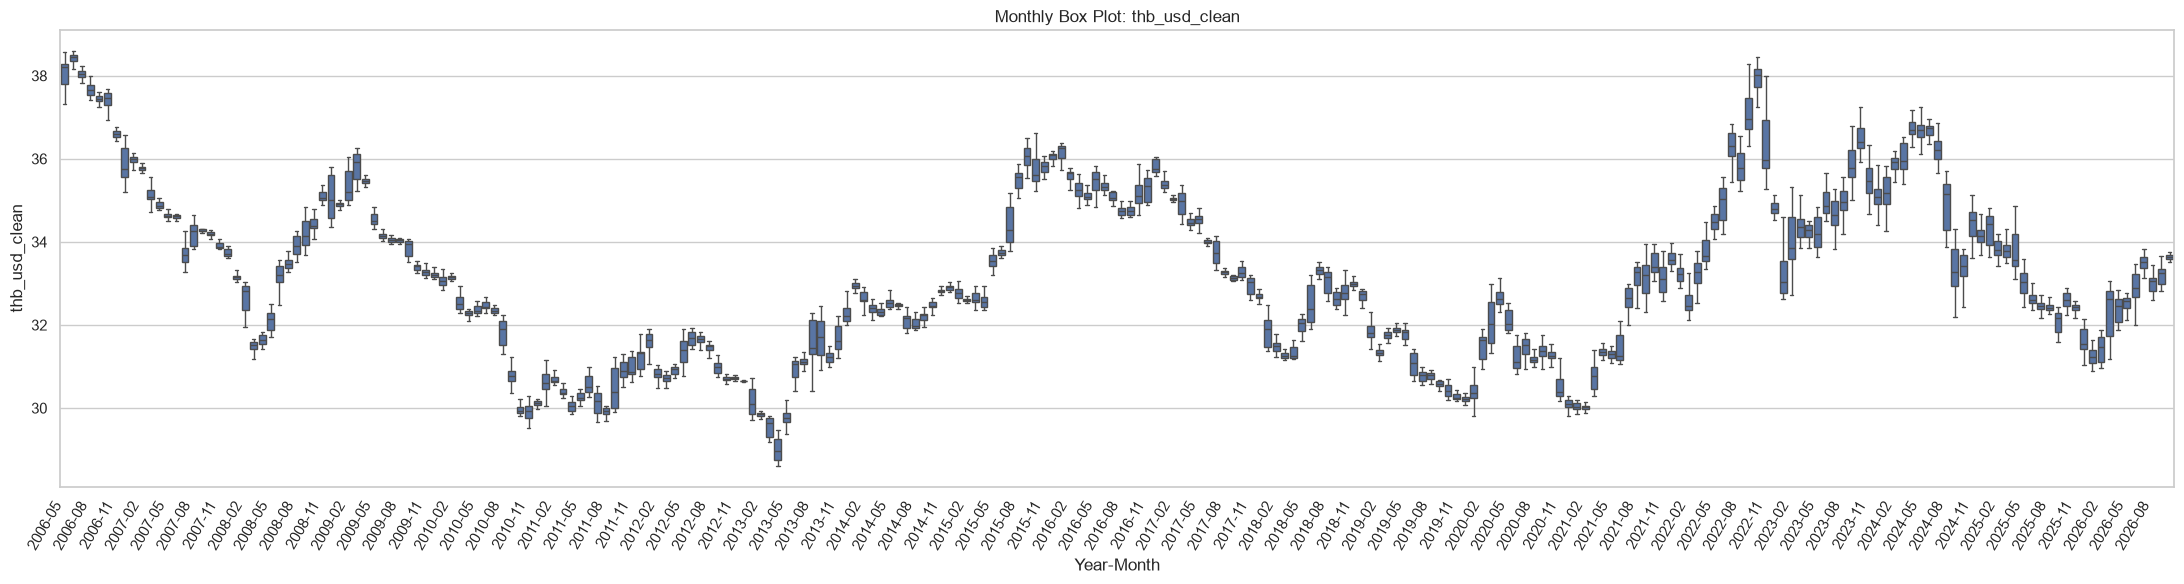

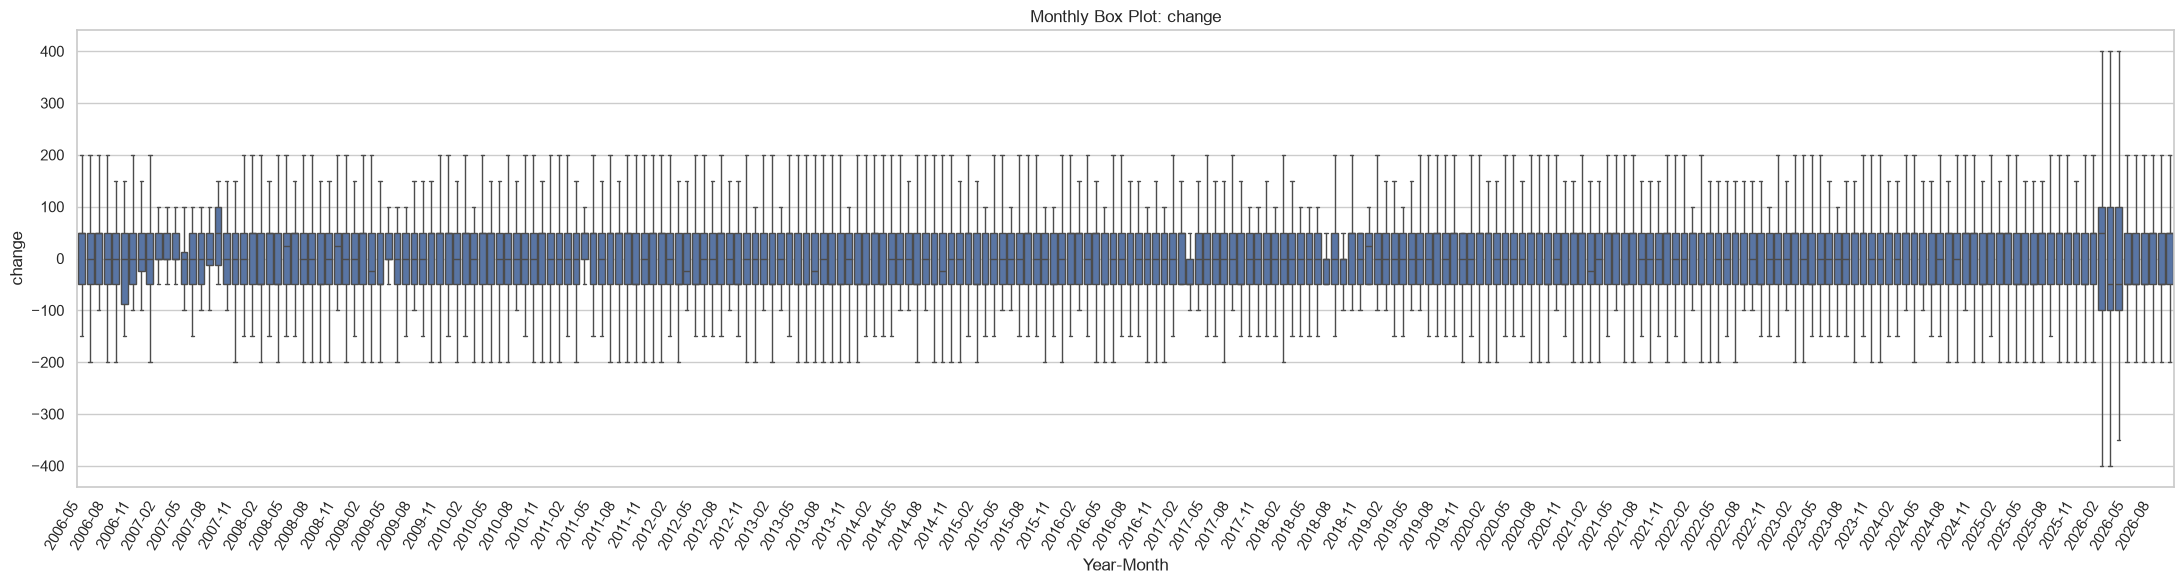

In [39]:
plot_df = df_market_eda.copy()

# สร้างป้ายเดือน-ปีสำหรับจัดกลุ่มกราฟเท่านั้น
plot_df["year_month"] = (
    plot_df["timestamp_parsed"].dt.to_period("M").astype(str)
)

month_order = sorted(plot_df["year_month"].unique())

numeric_cols = [
    "session",
    "ornament_buy",
    "ornament_sell",
    "bar_buy",
    "bar_sell",
    "gold_spot_clean",
    "thb_usd_clean",
    "change",
]

sns.set_theme(style="whitegrid")

for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(22, 6))

    sns.boxplot(
        data=plot_df,
        x="year_month",
        y=col,
        order=month_order,
        ax=ax,
        showfliers=False
    )

    # แสดงป้ายแกน X ทุก 3 เดือน เพื่อไม่ให้ข้อความทับกัน
    tick_positions = list(range(0, len(month_order), 3))
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(
        [month_order[i] for i in tick_positions],
        rotation=60,
        ha="right"
    )

    ax.set_title(f"Monthly Box Plot: {col}")
    ax.set_xlabel("Year-Month")
    ax.set_ylabel(col)

    plt.tight_layout()
    plt.show()

# Feature Engineering

เพื่อช่วยให้ llm ตอบคำถามได้ง่ายขึ้น

## การเคลื่อนที่ของราคา


| Feature                    | นิยาม                                                                   | ใช้ตอบคำถาม                       |
| -------------------------- | ----------------------------------------------------------------------- | --------------------------------- |
| `bar_buy_change_intraday`  | ราคาซื้อทองแท่งปัจจุบัน − ราคาประกาศก่อนหน้าในวันเดียวกัน               | ราคาเปลี่ยนระหว่างประกาศเท่าไร    |
| `bar_sell_change_intraday` | ราคาขายทองแท่งปัจจุบัน − ราคาประกาศก่อนหน้าในวันเดียวกัน                | ราคาขายเปลี่ยนระหว่างประกาศเท่าไร |
| `bar_buy_change_daily`     | ราคาซื้อทองแท่ง ณ ประกาศสุดท้ายของวัน − ราคาประกาศสุดท้ายของวันก่อนหน้า | ราคาปิดท้ายวันเปลี่ยนเท่าไร       |
| `bar_sell_change_daily`    | ราคาขายทองแท่ง ณ ประกาศสุดท้ายของวัน − ราคาประกาศสุดท้ายของวันก่อนหน้า  | ราคาขายปิดท้ายวันเปลี่ยนเท่าไร    |
| `bar_buy_pct_change_*`     | การเปลี่ยนแปลงราคา ÷ ราคาอ้างอิงก่อนหน้า × 100                          | ราคาเปลี่ยนเป็นกี่เปอร์เซ็นต์     |
| `ornament_*_change_*`      | การเปลี่ยนแปลงของราคาทองรูปพรรณตามหลักเดียวกัน                          | ราคาทองรูปพรรณเคลื่อนไหวอย่างไร   |

เ

### เคลื่อนไหวระหว่างวัน

In [40]:

required_cols = [
    "timestamp_parsed",
    "session",
    "ornament_buy",
    "ornament_sell",
    "bar_buy",
    "bar_sell",
    "gold_spot_clean",
    "thb_usd_clean",
]

missing_cols = [
    col for col in required_cols
    if col not in df_market_eda.columns
]

if missing_cols:
    raise KeyError(f"Missing columns: {missing_cols}")

df_intraday_features = (
    df_market_eda
    .copy()
    .sort_values(
        ["timestamp_parsed", "session"],
        kind="stable"
    )
    .reset_index(drop=True)
)

# วันปฏิทินใช้สำหรับแบ่งกลุ่มเท่านั้น
df_intraday_features["_date"] = (
    df_intraday_features["timestamp_parsed"].dt.date
)

price_cols = [
    "ornament_buy",
    "ornament_sell",
    "bar_buy",
    "bar_sell",
    "gold_spot_clean",
    "thb_usd_clean",
]

for col in price_cols:
    # ราคา record ก่อนหน้าในวันเดียวกัน
    previous = (
        df_intraday_features
        .groupby("_date", sort=False)[col]
        .shift(1)
    )

    change_col = f"{col}_change_intraday"
    pct_col = f"{col}_pct_change_intraday"

    df_intraday_features[change_col] = (
        df_intraday_features[col] - previous
    )

    # ไม่หารด้วยศูนย์ และไม่คำนวณหากค่าต้นทางหายไป
    valid_denominator = previous.notna() & previous.ne(0)

    df_intraday_features[pct_col] = (
        df_intraday_features[change_col]
        .div(previous.where(valid_denominator))
        * 100
    )

df_intraday_features = df_intraday_features.drop(
    columns="_date"
)

print("Original shape:", df_market_eda.shape)
print("Intraday shape:", df_intraday_features.shape)

display(
    df_intraday_features[
        [
            "timestamp_parsed",
            "session",
            "bar_buy",
            "bar_buy_change_intraday",
            "bar_buy_pct_change_intraday",
            "gold_spot_clean",
            "gold_spot_clean_change_intraday",
            "thb_usd_clean",
            "thb_usd_clean_change_intraday",
        ]
    ].head(20)
)

Original shape: (24519, 13)
Intraday shape: (24519, 25)


,timestamp_parsed,session,bar_buy,bar_buy_change_intraday,bar_buy_pct_change_intraday,gold_spot_clean,gold_spot_clean_change_intraday,thb_usd_clean,thb_usd_clean_change_intraday
0,2006-05-01 09:30:00,1,11450.0,NaN,NaN,648.64,NaN,37.33,NaN
1,2006-05-02 09:30:00,1,11500.0,NaN,NaN,656.25,NaN,37.61,NaN
2,2006-05-02 11:50:00,2,11550.0,50.0,0.434783,657.05,0.8,NaN,NaN
3,2006-05-03 09:30:00,1,11750.0,NaN,NaN,668.90,NaN,37.58,NaN
4,2006-05-03 10:45:00,2,11900.0,150.0,1.276596,675.90,7.0,37.61,0.03
5,2006-05-03 11:15:00,3,11800.0,-100.0,-0.840336,669.20,-6.7,37.62,0.01
6,2006-05-03 14:00:00,4,11850.0,50.0,0.423729,674.30,5.1,37.56,-0.06
7,2006-05-04 10:21:00,1,11850.0,NaN,NaN,666.30,NaN,37.78,NaN
8,2006-05-06 09:30:00,1,12150.0,NaN,NaN,683.50,NaN,37.83,NaN
9,2006-05-08 09:30:00,1,12100.0,NaN,NaN,681.75,NaN,37.62,NaN


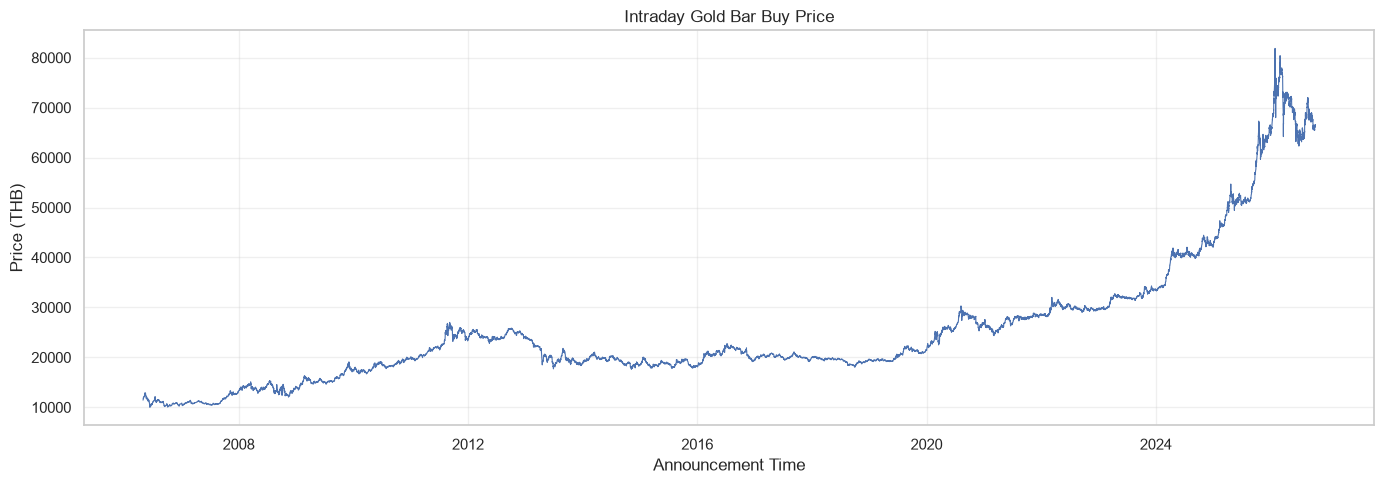

In [41]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_intraday_features["timestamp_parsed"],
    df_intraday_features["bar_buy"],
    linewidth=0.8
)

ax.set_title("Intraday Gold Bar Buy Price")
ax.set_xlabel("Announcement Time")
ax.set_ylabel("Price (THB)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

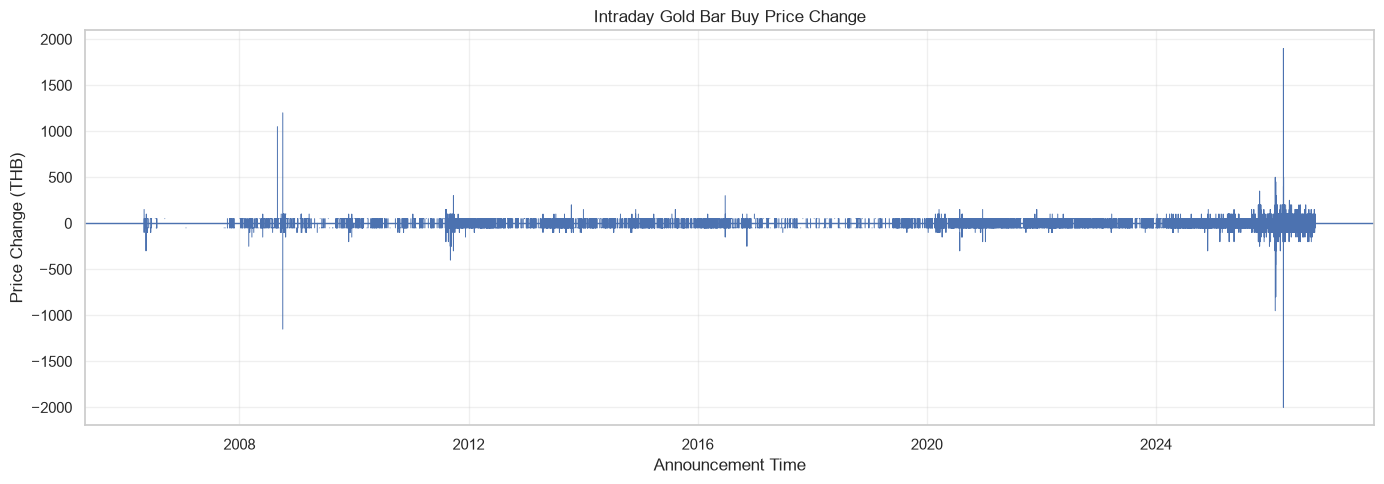

In [42]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_intraday_features["timestamp_parsed"],
    df_intraday_features["bar_buy_change_intraday"],
    linewidth=0.7
)

ax.axhline(0, linewidth=1)
ax.set_title("Intraday Gold Bar Buy Price Change")
ax.set_xlabel("Announcement Time")
ax.set_ylabel("Price Change (THB)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### เคลื่อนไหวแยกวัน

In [43]:

df_daily_base = (
    df_market_eda
    .copy()
    .sort_values(
        ["timestamp_parsed", "session"],
        kind="stable"
    )
)

df_daily_base["_date"] = (
    df_daily_base["timestamp_parsed"].dt.normalize()
)

# เลือก record ล่าสุดของแต่ละวันตาม timestamp/session
df_daily_features = (
    df_daily_base
    .groupby("_date", sort=True, as_index=False)
    .tail(1)
    .sort_values("_date")
    .reset_index(drop=True)
    .rename(columns={"_date": "date"})
)

for col in price_cols:
    change_col = f"{col}_change_daily"
    pct_col = f"{col}_pct_change_daily"

    # เปรียบเทียบกับวันก่อนหน้าที่มีข้อมูล
    previous = df_daily_features[col].shift(1)

    df_daily_features[change_col] = (
        df_daily_features[col] - previous
    )

    valid_denominator = previous.notna() & previous.ne(0)

    df_daily_features[pct_col] = (
        df_daily_features[change_col]
        .div(previous.where(valid_denominator))
        * 100
    )

print("Daily records:", len(df_daily_features))
print(
    "Date range:",
    df_daily_features["date"].min(),
    "to",
    df_daily_features["date"].max()
)

display(
    df_daily_features[
        [
            "date",
            "timestamp_parsed",
            "bar_buy",
            "bar_buy_change_daily",
            "bar_buy_pct_change_daily",
            "gold_spot_clean",
            "gold_spot_clean_change_daily",
            "thb_usd_clean",
            "thb_usd_clean_change_daily",
        ]
    ].head(15)
)

Daily records: 6261
Date range: 2006-05-01 00:00:00 to 2026-10-13 00:00:00


,date,timestamp_parsed,bar_buy,bar_buy_change_daily,bar_buy_pct_change_daily,gold_spot_clean,gold_spot_clean_change_daily,thb_usd_clean,thb_usd_clean_change_daily
0,2006-05-01,2006-05-01 09:30:00,11450.0,NaN,NaN,648.64,NaN,37.33,NaN
1,2006-05-02,2006-05-02 11:50:00,11550.0,100.0,0.873362,657.05,8.41,NaN,NaN
2,2006-05-03,2006-05-03 14:00:00,11850.0,300.0,2.597403,674.30,17.25,37.56,NaN
3,2006-05-04,2006-05-04 10:21:00,11850.0,0.0,0.000000,666.30,-8.00,37.78,0.22
4,2006-05-06,2006-05-06 09:30:00,12150.0,300.0,2.531646,683.50,17.20,37.83,0.05
5,2006-05-08,2006-05-08 09:30:00,12100.0,-50.0,-0.411523,681.75,-1.75,37.62,-0.21
6,2006-05-09,2006-05-09 09:30:00,12100.0,0.0,0.000000,682.20,0.45,37.71,0.09
7,2006-05-10,2006-05-10 14:00:00,12400.0,300.0,2.479339,703.70,21.50,37.70,-0.01
8,2006-05-11,2006-05-11 11:50:00,12650.0,250.0,2.016129,NaN,NaN,NaN,NaN
9,2006-05-13,2006-05-13 10:30:00,12800.0,150.0,1.185771,NaN,NaN,NaN,NaN


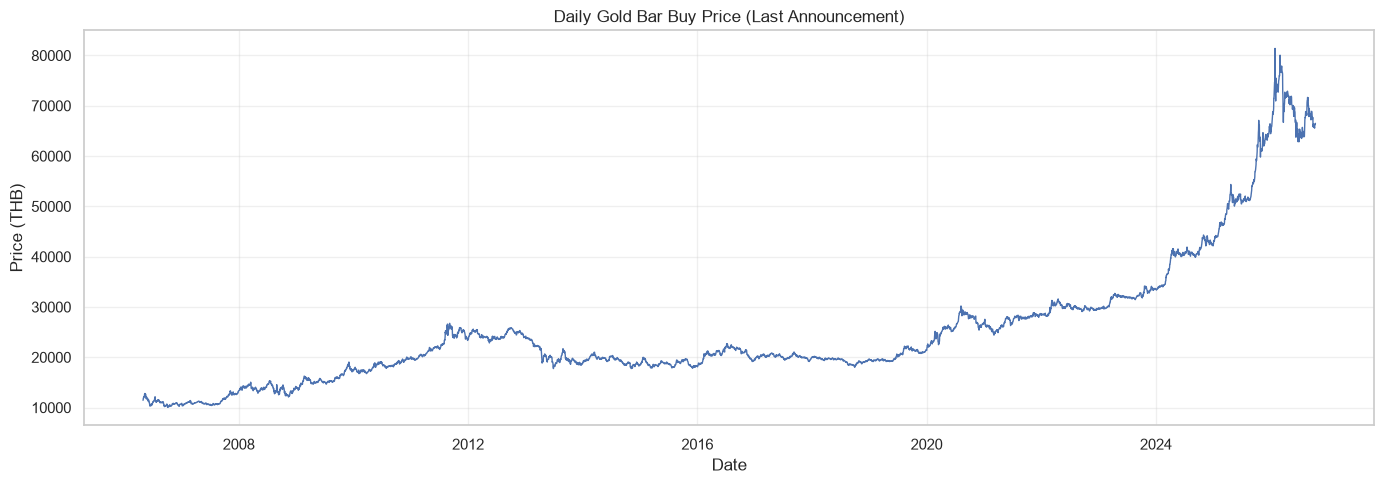

In [44]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_daily_features["date"],
    df_daily_features["bar_buy"],
    linewidth=1
)

ax.set_title("Daily Gold Bar Buy Price (Last Announcement)")
ax.set_xlabel("Date")
ax.set_ylabel("Price (THB)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

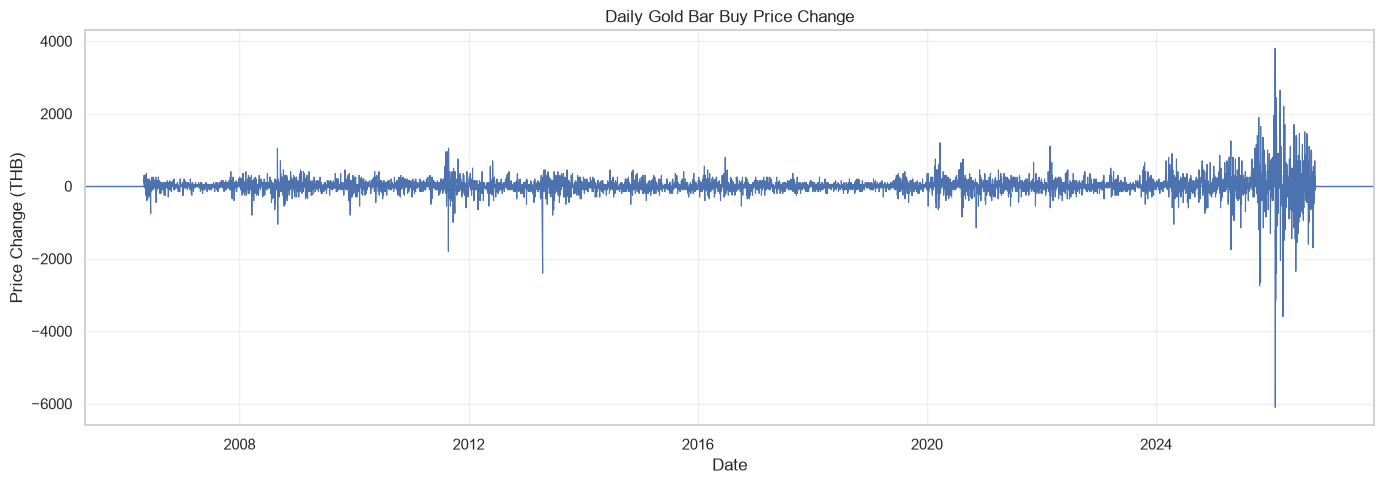

In [45]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_daily_features["date"],
    df_daily_features["bar_buy_change_daily"],
    linewidth=0.8
)

ax.axhline(0, linewidth=1)
ax.set_title("Daily Gold Bar Buy Price Change")
ax.set_xlabel("Date")
ax.set_ylabel("Price Change (THB)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### ตรวจสอบความถูกต้องของ Features

In [46]:
# 1. ยืนยันว่าต้นฉบับไม่ได้ถูกแก้ไข
print("Original shape:", df_market_eda.shape)
print("Intraday rows:", len(df_intraday_features))
print("Daily rows:", len(df_daily_features))

# 2. ตรวจ timestamp ซ้ำในต้นฉบับ
print(
    "Duplicate timestamps:",
    df_market_eda["timestamp_parsed"].duplicated().sum()
)

# 3. ตรวจจำนวน Missing ของ Features หลัก
feature_cols = [
    "bar_buy_change_intraday",
    "bar_buy_pct_change_intraday",
    "bar_buy_change_daily",
    "bar_buy_pct_change_daily",
]

print("\nIntraday feature missingness:")
display(
    df_intraday_features[
        [
            "bar_buy_change_intraday",
            "bar_buy_pct_change_intraday",
        ]
    ].isna().sum().to_frame("missing_count")
)

print("\nDaily feature missingness:")
display(
    df_daily_features[
        [
            "bar_buy_change_daily",
            "bar_buy_pct_change_daily",
        ]
    ].isna().sum().to_frame("missing_count")
)

# 4. ตรวจตัวอย่างการคำนวณจากข้อมูลสองจุด
display(
    df_intraday_features[
        [
            "timestamp_parsed",
            "bar_buy",
            "bar_buy_change_intraday",
        ]
    ].head(10)
)

Original shape: (24519, 13)
Intraday rows: 24519
Daily rows: 6261
Duplicate timestamps: 8

Intraday feature missingness:


,missing_count
bar_buy_change_intraday,6261
bar_buy_pct_change_intraday,6261



Daily feature missingness:


,missing_count
bar_buy_change_daily,1
bar_buy_pct_change_daily,1


,timestamp_parsed,bar_buy,bar_buy_change_intraday
0,2006-05-01 09:30:00,11450.0,NaN
1,2006-05-02 09:30:00,11500.0,NaN
2,2006-05-02 11:50:00,11550.0,50.0
3,2006-05-03 09:30:00,11750.0,NaN
4,2006-05-03 10:45:00,11900.0,150.0
5,2006-05-03 11:15:00,11800.0,-100.0
6,2006-05-03 14:00:00,11850.0,50.0
7,2006-05-04 10:21:00,11850.0,NaN
8,2006-05-06 09:30:00,12150.0,NaN
9,2006-05-08 09:30:00,12100.0,NaN


In [47]:
# ตรวจสอบจำนวนแถวแรกของแต่ละวันที่มีข้อมูล
first_rows_per_day = (
    df_intraday_features
    .groupby(
        df_intraday_features["timestamp_parsed"].dt.normalize()
    )
    .head(1)
)

print("จำนวนวันที่มีข้อมูล:", len(first_rows_per_day))

print(
    "จำนวนแถวแรกของวันที่ไม่มี Intraday Change:",
    first_rows_per_day["bar_buy_change_intraday"].isna().sum()
)

print(
    "Missing Intraday Change ทั้งหมด:",
    df_intraday_features["bar_buy_change_intraday"].isna().sum()
)

# ตรวจว่ามี Missing ที่ไม่ใช่แถวแรกของวันหรือไม่
first_index = first_rows_per_day.index

unexpected_missing = (
    df_intraday_features["bar_buy_change_intraday"].isna()
    & ~df_intraday_features.index.isin(first_index)
)

print("Missing ที่ไม่ใช่แถวแรกของวัน:", unexpected_missing.sum())

จำนวนวันที่มีข้อมูล: 6261
จำนวนแถวแรกของวันที่ไม่มี Intraday Change: 6261
Missing Intraday Change ทั้งหมด: 6261
Missing ที่ไม่ใช่แถวแรกของวัน: 0


เกิดจากการเป็นประกาศแรกของแต่ละวันทั้งหมด ไม่มี Missing ที่ผิด

## Volatility

### ระหว่างวัน

In [48]:
df_intraday_volatility = df_intraday_features.copy()

WINDOW = 20

def add_valid_observation_rolling_std(
    df,
    source_col,
    output_col,
    window=20
):
    """
    คำนวณ rolling std จาก observations ที่มีค่าจริง
    แล้วนำผลกลับไปวางที่ index เดิม

    แต่ละ observation ยังคงใช้การเปลี่ยนแปลงตามนิยามต้นทาง
    โดยไม่เติมค่า NaN และไม่ใช้ข้อมูลอนาคต
    """
    valid_values = df[source_col].dropna()

    rolling_std = valid_values.rolling(
        window=window,
        min_periods=window
    ).std(ddof=1)

    df[output_col] = np.nan
    df.loc[rolling_std.index, output_col] = rolling_std

    return df


df_intraday_volatility = add_valid_observation_rolling_std(
    df_intraday_volatility,
    source_col="bar_buy_change_intraday",
    output_col="bar_buy_volatility_intraday",
    window=WINDOW
)

df_intraday_volatility = add_valid_observation_rolling_std(
    df_intraday_volatility,
    source_col="bar_buy_pct_change_intraday",
    output_col="bar_buy_pct_volatility_intraday",
    window=WINDOW
)

display(
    df_intraday_volatility[
        [
            "timestamp_parsed",
            "bar_buy",
            "bar_buy_change_intraday",
            "bar_buy_volatility_intraday",
            "bar_buy_pct_volatility_intraday",
        ]
    ].tail(30)
)

,timestamp_parsed,bar_buy,bar_buy_change_intraday,bar_buy_volatility_intraday,bar_buy_pct_volatility_intraday
24489,2026-10-09 12:47:00,66400.0,-50.0,60.426118,0.091669
24490,2026-10-09 13:13:00,66350.0,-50.0,60.426118,0.091619
24491,2026-10-09 14:05:00,66400.0,50.0,54.772256,0.082931
24492,2026-10-09 14:31:00,66350.0,-50.0,56.428809,0.085395
24493,2026-10-09 15:16:00,66400.0,50.0,56.428809,0.085363
24494,2026-10-09 15:41:00,66350.0,-50.0,57.582892,0.087065
24495,2026-10-09 15:51:00,66300.0,-50.0,57.582892,0.087018
24496,2026-10-09 16:03:00,66250.0,-50.0,57.582892,0.086970
24497,2026-10-10 09:06:00,66350.0,NaN,NaN,NaN
24498,2026-10-11 09:15:00,66350.0,NaN,NaN,NaN


### แยกตามวัน

In [49]:
df_daily_volatility = df_daily_features.copy()

df_daily_volatility = add_valid_observation_rolling_std(
    df_daily_volatility,
    source_col="bar_buy_change_daily",
    output_col="bar_buy_volatility_daily",
    window=WINDOW
)

df_daily_volatility = add_valid_observation_rolling_std(
    df_daily_volatility,
    source_col="bar_buy_pct_change_daily",
    output_col="bar_buy_pct_volatility_daily",
    window=WINDOW
)

display(
    df_daily_volatility[
        [
            "date",
            "bar_buy",
            "bar_buy_change_daily",
            "bar_buy_volatility_daily",
            "bar_buy_pct_volatility_daily",
        ]
    ].tail(30)
)

,date,bar_buy,bar_buy_change_daily,bar_buy_volatility_daily,bar_buy_pct_volatility_daily
6231,2026-09-14,67400.0,-650.0,588.905095,0.845797
6232,2026-09-15,67200.0,-200.0,588.731911,0.845520
6233,2026-09-16,68200.0,1000.0,646.951353,0.933969
6234,2026-09-17,67900.0,-300.0,634.589590,0.917242
6235,2026-09-18,68850.0,950.0,589.357366,0.863084
6236,2026-09-19,68900.0,50.0,588.771022,0.862289
6237,2026-09-20,68850.0,-50.0,583.230567,0.854494
6238,2026-09-21,68400.0,-450.0,564.165662,0.827884
6239,2026-09-22,67800.0,-600.0,533.970973,0.784715
6240,2026-09-23,67800.0,0.0,466.869473,0.685853


### การแกว่างของราคา

ช่วยดูว่าภายในหนึ่งวันราคาประกาศซื้อทองแท่งมีช่วงกว้างเท่าไร โดยใช้ราคาทุกประกาศในวันนั้น ไม่ใช่แค่ราคาประกาศสุดท้าย

In [50]:
df_daily_range = (
    df_market_eda
    .assign(
        date=lambda x: x["timestamp_parsed"].dt.normalize()
    )
    .groupby("date", as_index=False)
    .agg(
        bar_buy_intraday_min=("bar_buy", "min"),
        bar_buy_intraday_max=("bar_buy", "max"),
        bar_buy_range_intraday=("bar_buy", lambda s: s.max() - s.min()),
        announcement_count=("bar_buy", "size"),
    )
)

# รวมเข้า DataFrame ใหม่ โดยไม่แก้ df_daily_volatility
df_daily_volatility = df_daily_volatility.merge(
    df_daily_range,
    on="date",
    how="left",
    validate="one_to_one"
)

display(
    df_daily_volatility[
        [
            "date",
            "announcement_count",
            "bar_buy_intraday_min",
            "bar_buy_intraday_max",
            "bar_buy_range_intraday",
        ]
    ].tail(20)
)

,date,announcement_count,bar_buy_intraday_min,bar_buy_intraday_max,bar_buy_range_intraday
6241,2026-09-24,23,67250.0,67750.0,500.0
6242,2026-09-25,21,67250.0,67700.0,450.0
6243,2026-09-26,1,67650.0,67650.0,0.0
6244,2026-09-27,1,67650.0,67650.0,0.0
6245,2026-09-28,20,65800.0,66800.0,1000.0
6246,2026-09-29,15,65600.0,65800.0,200.0
6247,2026-09-30,15,66100.0,66450.0,350.0
6248,2026-10-01,22,66000.0,66450.0,450.0
6249,2026-10-02,17,66000.0,66450.0,450.0
6250,2026-10-03,1,65700.0,65700.0,0.0


### ตรวจสอบ

In [51]:
# ตรวจว่าจำนวนแถวไม่เปลี่ยน
print("Original market rows:", len(df_market_eda))
print("Intraday volatility rows:", len(df_intraday_volatility))
print("Daily volatility rows:", len(df_daily_volatility))

# ตรวจ Missing Values
volatility_cols = [
    "bar_buy_volatility_intraday",
    "bar_buy_pct_volatility_intraday",
]

display(
    df_intraday_volatility[volatility_cols]
    .isna()
    .sum()
    .to_frame("missing_count")
)

daily_volatility_cols = [
    "bar_buy_volatility_daily",
    "bar_buy_pct_volatility_daily",
    "bar_buy_range_intraday",
]

display(
    df_daily_volatility[daily_volatility_cols]
    .isna()
    .sum()
    .to_frame("missing_count")
)

# ตรวจว่าไม่มีค่าอนันต์
print(
    "Intraday infinite values:",
    np.isinf(
        df_intraday_volatility[volatility_cols].to_numpy()
    ).sum()
)

print(
    "Daily infinite values:",
    np.isinf(
        df_daily_volatility[daily_volatility_cols].to_numpy()
    ).sum()
)

Original market rows: 24519
Intraday volatility rows: 24519
Daily volatility rows: 6261


,missing_count
bar_buy_volatility_intraday,6280
bar_buy_pct_volatility_intraday,6280


,missing_count
bar_buy_volatility_daily,20
bar_buy_pct_volatility_daily,20
bar_buy_range_intraday,0


Intraday infinite values: 0
Daily infinite values: 0


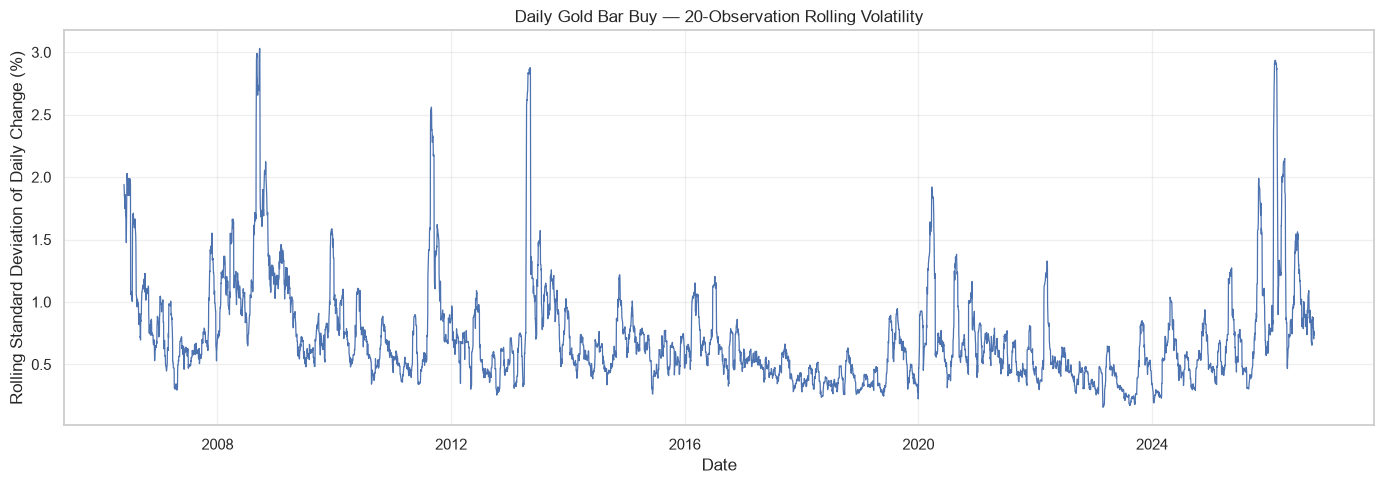

In [52]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_daily_volatility["date"],
    df_daily_volatility["bar_buy_pct_volatility_daily"],
    linewidth=0.9
)

ax.set_title("Daily Gold Bar Buy — 20-Observation Rolling Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Rolling Standard Deviation of Daily Change (%)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Market Regime

In [53]:
import warnings
import time
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from hmmlearn.hmm import GaussianHMM

import torch

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.set_printoptions(suppress=True, precision=5)

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("PyTorch CUDA build:", torch.version.cuda)
else:
    print("จะรันส่วน Torch บน CPU แทน; ไม่ได้แปลว่า CPU จะช้ากว่าใน dataset ขนาดนี้")

NumPy: 2.4.6
pandas: 3.0.6
PyTorch: 2.6.0+cu124
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch CUDA build: 12.4


In [54]:
DATA_PATH = r"D:\Project_Github\gold assisstant\dataset\datset a gold price\gold_data_cleaned.csv"

if "df_market_eda" in globals():
    source = df_market_eda.copy()
    source_name = "df_market_eda"
elif "df" in globals():
    source = df.copy()
    source_name = "df"
else:
    source = pd.read_csv(DATA_PATH)
    source_name = DATA_PATH

if "timestamp_parsed" in source.columns:
    source["timestamp_parsed"] = pd.to_datetime(source["timestamp_parsed"], errors="coerce")
elif {"date", "time"}.issubset(source.columns):
    source["timestamp_parsed"] = pd.to_datetime(
        source["date"].astype(str) + " " + source["time"].astype(str), errors="coerce"
    )
elif "timestamp" in source.columns:
    source["timestamp_parsed"] = pd.to_datetime(source["timestamp"], errors="coerce")
else:
    raise ValueError("ไม่พบ timestamp_parsed, date+time หรือ timestamp ใน source")

if "bar_buy" not in source.columns:
    raise ValueError("ไม่พบคอลัมน์ bar_buy ซึ่งใช้เป็นราคาอ้างอิงหลัก")

sort_cols = ["timestamp_parsed"]
if "session" in source.columns:
    sort_cols.append("session")
source["bar_buy_num"] = pd.to_numeric(source["bar_buy"], errors="coerce")
source = source.sort_values(sort_cols, kind="stable").reset_index(drop=True)

print("Source:", source_name)
print("Source rows:", len(source))
print("Timestamp range:", source["timestamp_parsed"].min(), "to", source["timestamp_parsed"].max())
print("Original DataFrame untouched: ใช้ copy() ในการเตรียมข้อมูล")

Source: df_market_eda
Source rows: 24519
Timestamp range: 2006-05-01 09:30:00 to 2026-10-13 12:09:00
Original DataFrame untouched: ใช้ copy() ในการเตรียมข้อมูล


### สร้าง features รายวัน
หนึ่งแถวต่อวัน ใช้ราคาแรก/สุดท้ายและ high/low ที่พบใน announcements ของวันนั้น ไม่มีการเติม missing values

In [55]:
source = source.dropna(subset=["timestamp_parsed"]).copy()
source["_date"] = source["timestamp_parsed"].dt.normalize()

daily = (
    source.groupby("_date", sort=True)
    .agg(
        bar_buy_first=("bar_buy_num", "first"),
        bar_buy_last=("bar_buy_num", "last"),
        bar_buy_high=("bar_buy_num", "max"),
        bar_buy_low=("bar_buy_num", "min"),
        n_announcements=("bar_buy_num", "count"),
    )
    .reset_index()
    .rename(columns={"_date": "date"})
)

# Daily log return: final observed price today / final observed price on previous observed day.
daily["bar_buy_log_return"] = np.log(daily["bar_buy_last"].where(daily["bar_buy_last"] > 0)).diff()
# Daily announcement range, observable after that day has finished.
daily["intraday_range_pct"] = (
    (daily["bar_buy_high"] - daily["bar_buy_low"]) /
    daily["bar_buy_first"].where(daily["bar_buy_first"] > 0)
)

BASE_FEATURES = ["bar_buy_log_return", "intraday_range_pct"]
model_df = (
    daily.replace([np.inf, -np.inf], np.nan)
    .dropna(subset=BASE_FEATURES)
    .sort_values("date")
    .reset_index(drop=True)
)

print("Daily rows (including initial row with no return):", len(daily))
print("Model rows after dropping unavailable features:", len(model_df))
print("Model date range:", model_df["date"].min(), "to", model_df["date"].max())
display(model_df[ ["date", "bar_buy_first", "bar_buy_last", "bar_buy_log_return", "intraday_range_pct", "n_announcements"] ].head())
display(model_df[BASE_FEATURES].describe().T)

Daily rows (including initial row with no return): 6261
Model rows after dropping unavailable features: 6260
Model date range: 2006-05-02 00:00:00 to 2026-10-13 00:00:00


,date,bar_buy_first,bar_buy_last,bar_buy_log_return,intraday_range_pct,n_announcements
0,2006-05-02,11500.0,11550.0,0.008696,0.004348,2
1,2006-05-03,11750.0,11850.0,0.025642,0.012766,4
2,2006-05-04,11850.0,11850.0,0.000000,0.000000,1
3,2006-05-06,12150.0,12150.0,0.025001,0.000000,1
4,2006-05-08,12100.0,12100.0,-0.004124,0.000000,1


,count,mean,std,min,25%,50%,75%,max
bar_buy_log_return,6260.0,0.000281,0.00827,-0.119844,-0.002926,0.000000,0.004131,0.074901
intraday_range_pct,6260.0,0.002893,0.00403,0.000000,0.000000,0.002407,0.003984,0.092251


train 70%, validation 15%, test 15% และ validation ใช้เลือกจำนวน states

In [56]:
n = len(model_df)
if n < 200:
    raise ValueError(f"มีข้อมูลเพียง {n} rows; ควรตรวจสอบ data ก่อน fit HMM")

I_TRAIN = int(n * 0.70)
I_VAL = int(n * 0.85)
if I_TRAIN < 50 or I_VAL <= I_TRAIN or I_VAL >= n:
    raise ValueError("ข้อมูลไม่พอสำหรับ chronological split")

X_base_raw = model_df[BASE_FEATURES].to_numpy(dtype=float)
scaler_base = StandardScaler()
X_base_train = scaler_base.fit_transform(X_base_raw[:I_TRAIN])
X_base_val = scaler_base.transform(X_base_raw[I_TRAIN:I_VAL])
X_base_test = scaler_base.transform(X_base_raw[I_VAL:])

print(f"Total rows: {n:,}")
print(f"Train: {I_TRAIN:,} | {model_df['date'].iloc[0].date()} → {model_df['date'].iloc[I_TRAIN-1].date()}")
print(f"Validation: {I_VAL-I_TRAIN:,} | {model_df['date'].iloc[I_TRAIN].date()} → {model_df['date'].iloc[I_VAL-1].date()}")
print(f"Test: {n-I_VAL:,} | {model_df['date'].iloc[I_VAL].date()} → {model_df['date'].iloc[-1].date()}")
print("Features:", BASE_FEATURES)
print("Missing in model matrix:", int(np.isnan(X_base_raw).sum()))

Total rows: 6,260
Train: 4,382 | 2006-05-02 → 2020-10-28
Validation: 939 | 2020-10-29 → 2023-10-28
Test: 939 | 2023-10-30 → 2026-10-13
Features: ['bar_buy_log_return', 'intraday_range_pct']
Missing in model matrix: 0


In [57]:
def get_diag_variances(model):
    covars = np.asarray(model.covars_, dtype=float)
    if covars.ndim == 2:              # (states, features)
        variances = covars
    elif covars.ndim == 3:            # (states, features, features)
        variances = np.diagonal(covars, axis1=1, axis2=2)
    else:
        raise ValueError(f"Unexpected covariance shape: {covars.shape}")
    return np.maximum(variances, 1e-8)


def diag_gaussian_log_emission(X, means, variances):
    X = np.asarray(X, dtype=float)
    means = np.asarray(means, dtype=float)
    variances = np.maximum(np.asarray(variances, dtype=float), 1e-8)
    diff = X[:, None, :] - means[None, :, :]
    log_norm = np.log(2.0 * np.pi * variances).sum(axis=1)
    quad = (diff * diff / variances[None, :, :]).sum(axis=2)
    return -0.5 * (log_norm[None, :] + quad)


def model_parameters(model):
    return (
        np.asarray(model.startprob_, dtype=float),
        np.asarray(model.transmat_, dtype=float),
        np.asarray(model.means_, dtype=float),
        get_diag_variances(model),
    )


def filter_segment(X, model, alpha_prev=None):
    """Filtered posterior using observations up to each row; returns predictive log score."""
    X = np.asarray(X, dtype=float)
    startprob, transmat, means, variances = model_parameters(model)
    log_A = np.log(np.clip(transmat, 1e-12, 1.0))
    log_B = diag_gaussian_log_emission(X, means, variances)
    posterior = np.zeros((len(X), len(startprob)), dtype=float)
    total_log_score = 0.0

    if alpha_prev is None:
        prior_log = np.log(np.clip(startprob, 1e-12, 1.0))
    else:
        prior_log = logsumexp(np.log(np.clip(alpha_prev, 1e-12, 1.0))[:, None] + log_A, axis=0)

    unnorm = prior_log + log_B[0]
    norm = logsumexp(unnorm)
    posterior[0] = np.exp(unnorm - norm)
    total_log_score += float(norm)

    for t in range(1, len(X)):
        prior_log = logsumexp(np.log(np.clip(posterior[t-1], 1e-12, 1.0))[:, None] + log_A, axis=0)
        unnorm = prior_log + log_B[t]
        norm = logsumexp(unnorm)
        posterior[t] = np.exp(unnorm - norm)
        total_log_score += float(norm)

    return total_log_score, posterior, posterior[-1]

print("Filtering helpers ready.")

Filtering helpers ready.


### Fit และเลือก Gaussian HMM baseline

ลอง K=2,3,4 และหลาย random seeds; seed เลือกจาก train likelihood ส่วนจำนวน states เลือกจาก validation predictive log score

In [58]:
def fit_select_hmm(X_train, X_val, state_counts=(2, 3, 4), seeds=(11, 21, 42), n_iter=200):
    rows = []
    fitted = {}
    for k in state_counts:
        best_model = None
        best_train_ll = -np.inf
        best_seed = None
        for seed in seeds:
            model = GaussianHMM(
                n_components=k,
                covariance_type="diag",
                n_iter=n_iter,
                tol=1e-3,
                min_covar=1e-3,
                random_state=seed,
                implementation="log",
            )
            try:
                model.fit(X_train)
                train_ll = float(model.score(X_train))
                if np.isfinite(train_ll) and train_ll > best_train_ll:
                    best_model, best_train_ll, best_seed = model, train_ll, seed
            except Exception as exc:
                print(f"Skip K={k}, seed={seed}: {type(exc).__name__}: {exc}")

        if best_model is None:
            continue

        _, _, alpha_train_end = filter_segment(X_train, best_model)
        val_ll, _, _ = filter_segment(X_val, best_model, alpha_prev=alpha_train_end)
        rows.append({
            "K": k,
            "seed": best_seed,
            "train_loglik": best_train_ll,
            "val_predictive_loglik": val_ll,
            "val_loglik_per_row": val_ll / len(X_val),
            "converged": bool(best_model.monitor_.converged),
            "iterations": int(best_model.monitor_.iter),
        })
        fitted[k] = best_model

    results = pd.DataFrame(rows).sort_values("val_loglik_per_row", ascending=False).reset_index(drop=True)
    if results.empty:
        raise RuntimeError("ไม่มี GaussianHMM fit สำเร็จ")
    best_k = int(results.iloc[0]["K"])
    return fitted[best_k], results, fitted

start = time.perf_counter()
baseline_model, baseline_selection, baseline_models = fit_select_hmm(
    X_base_train, X_base_val, state_counts=(2, 3, 4), seeds=(11, 21, 42), n_iter=200
)
print(f"Baseline fit/selection wall time: {time.perf_counter()-start:.2f} sec")
display(baseline_selection)
BASELINE_K = int(baseline_selection.iloc[0]["K"])
print("Selected Gaussian HMM states:", BASELINE_K)

Baseline fit/selection wall time: 6.93 sec


,K,seed,train_loglik,val_predictive_loglik,val_loglik_per_row,converged,iterations
0,3,42,-1379.811054,-829.756069,-0.883659,True,83
1,4,21,-225.580773,-1542.987433,-1.643224,True,106
2,2,11,-9964.200545,-1606.364067,-1.710718,True,47


Selected Gaussian HMM states: 3


,model,K,train_loglik_per_row,validation_loglik_per_row,test_loglik_per_row,test_rows
0,Gaussian HMM baseline,3,-0.314882,-0.883659,-1.892303,939


,state,weighted_mean_return,weighted_mean_range_pct,train_posterior_mass
0,0,0.000464,0.000000,0.411362
1,1,0.000372,0.003298,0.456122
2,2,-0.001180,0.008826,0.132516


,date,bar_buy_log_return,intraday_range_pct,state_id,regime_label
0,2023-10-30,-0.005882,0.004405,1,mid-range
1,2023-10-31,0.000000,0.001475,1,mid-range
2,2023-11-01,0.000000,0.001475,1,mid-range
3,2023-11-02,-0.004435,0.001481,1,mid-range
4,2023-11-03,-0.004454,0.002972,1,mid-range
5,2023-11-04,-0.004474,0.000000,0,low-range
6,2023-11-06,-0.004494,0.004491,1,mid-range
7,2023-11-07,-0.007536,0.004518,1,mid-range
8,2023-11-08,0.000000,0.001515,1,mid-range
9,2023-11-09,-0.010646,0.001529,1,mid-range


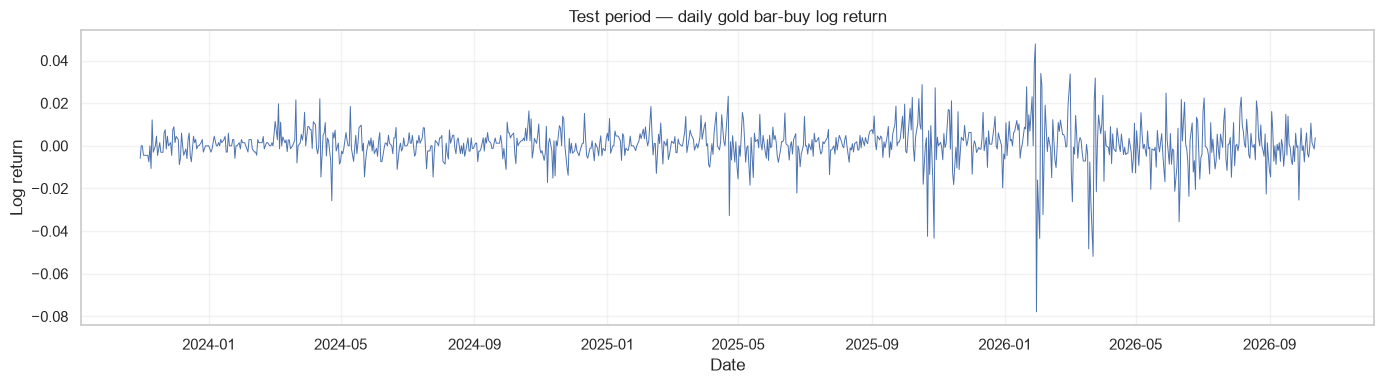

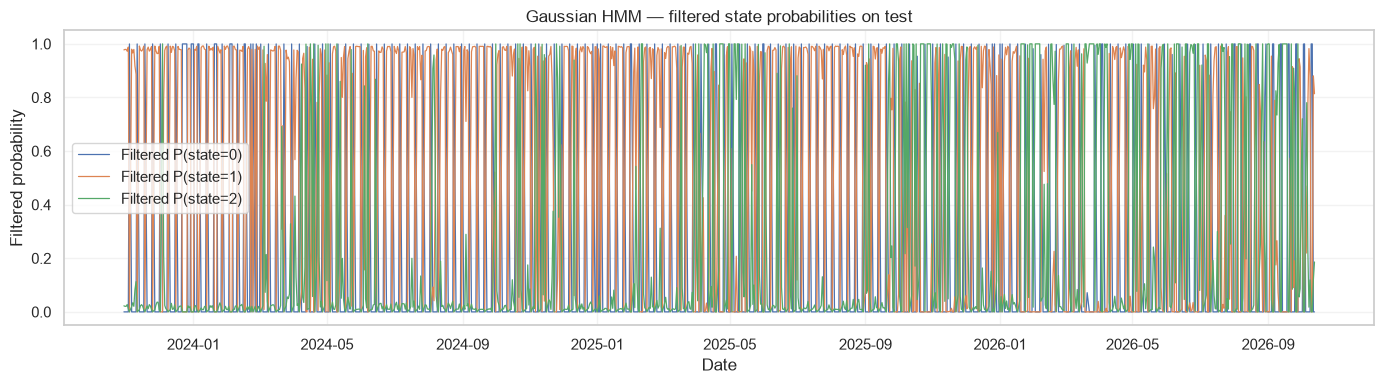

In [59]:
base_train_ll, p_base_train, alpha_base_train_end = filter_segment(X_base_train, baseline_model)
base_val_ll, p_base_val, alpha_base_val_end = filter_segment(X_base_val, baseline_model, alpha_prev=alpha_base_train_end)
base_test_ll, p_base_test, alpha_base_test_end = filter_segment(X_base_test, baseline_model, alpha_prev=alpha_base_val_end)

baseline_eval = pd.DataFrame([{
    "model": "Gaussian HMM baseline",
    "K": BASELINE_K,
    "train_loglik_per_row": base_train_ll / len(X_base_train),
    "validation_loglik_per_row": base_val_ll / len(X_base_val),
    "test_loglik_per_row": base_test_ll / len(X_base_test),
    "test_rows": len(X_base_test),
}])
display(baseline_eval)

train_original = model_df.iloc[:I_TRAIN].reset_index(drop=True)
state_stats = []
for k in range(BASELINE_K):
    weights = p_base_train[:, k]
    denom = max(weights.sum(), 1e-12)
    state_stats.append({
        "state": k,
        "weighted_mean_return": float(np.sum(weights * train_original["bar_buy_log_return"].to_numpy()) / denom),
        "weighted_mean_range_pct": float(np.sum(weights * train_original["intraday_range_pct"].to_numpy()) / denom),
        "train_posterior_mass": float(weights.mean()),
    })
state_stats = pd.DataFrame(state_stats).sort_values("weighted_mean_range_pct").reset_index(drop=True)
display(state_stats)

# Label by training-set range ordering only; HMM state numbers themselves have no intrinsic meaning.
ordered_states = state_stats["state"].tolist()
rank_name = {0: "low-range", 1: "mid-range", 2: "high-range"}
state_name = {state: rank_name[min(rank, 2)] for rank, state in enumerate(ordered_states)}

test_out = model_df.iloc[I_VAL:].copy().reset_index(drop=True)
test_out["state_id"] = np.argmax(p_base_test, axis=1)
test_out["regime_label"] = test_out["state_id"].map(state_name)
for k in range(BASELINE_K):
    test_out[f"p_state_{k}"] = p_base_test[:, k]

display(test_out[["date", "bar_buy_log_return", "intraday_range_pct", "state_id", "regime_label"]].head(10))

plt.figure(figsize=(14, 4))
plt.plot(test_out["date"], test_out["bar_buy_log_return"], linewidth=0.7)
plt.title("Test period — daily gold bar-buy log return")
plt.xlabel("Date"); plt.ylabel("Log return")
plt.grid(True, alpha=0.25); plt.tight_layout(); plt.show()

plt.figure(figsize=(14, 4))
for k in range(BASELINE_K):
    plt.plot(test_out["date"], test_out[f"p_state_{k}"], linewidth=0.9, label=f"Filtered P(state={k})")
plt.title("Gaussian HMM — filtered state probabilities on test")
plt.xlabel("Date"); plt.ylabel("Filtered probability")
plt.legend(); plt.grid(True, alpha=0.25); plt.tight_layout(); plt.show()

EGARCH train fit time: 0.07 sec
                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                            y   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -4599.25
Distribution:      Standardized Student's t   AIC:                           9210.51
Method:                  Maximum Likelihood   BIC:                           9248.82
                                              No. Observations:                 4382
Date:                      Fri, Oct 23 2026   Df Residuals:                     4381
Time:                              15:01:03   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
-------------------------------------------------

,date,bar_buy_log_return,egarch_sigma_pct
0,2006-05-02,0.008696,1.798742
1,2006-05-03,0.025642,1.771705
2,2006-05-04,0.000000,1.869791
3,2006-05-06,0.025001,1.781247
4,2006-05-08,-0.004124,1.873905


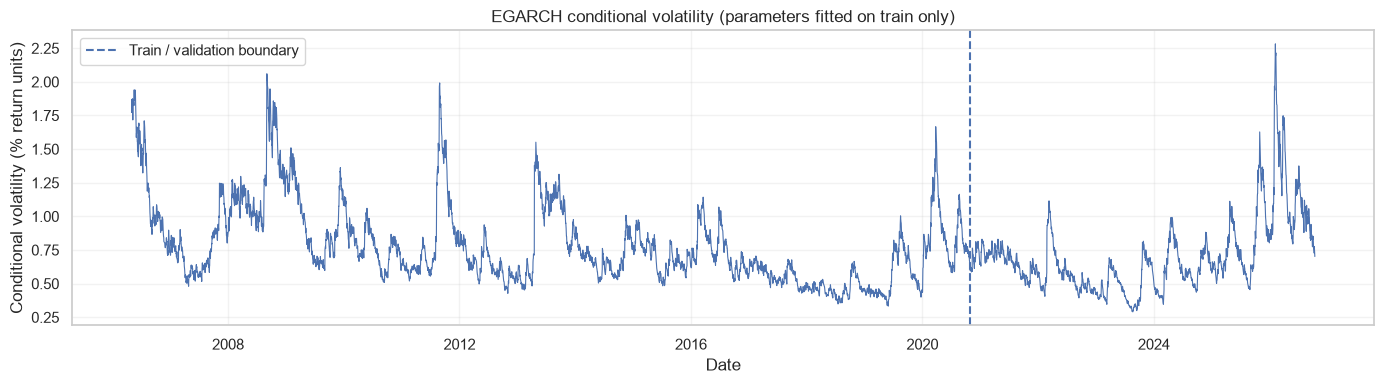

In [60]:
from arch import arch_model

returns_pct = model_df["bar_buy_log_return"].to_numpy(dtype=float) * 100.0
ret_train_pct = returns_pct[:I_TRAIN]

# Scale returns by 100 for numerical convenience in ARCH models.
egarch_train_spec = arch_model(
    ret_train_pct,
    mean="Constant",
    vol="EGARCH",
    p=1, o=1, q=1,
    dist="t",
)
start = time.perf_counter()
egarch_train_result = egarch_train_spec.fit(disp="off", show_warning=False)
print(f"EGARCH train fit time: {time.perf_counter()-start:.2f} sec")
print(egarch_train_result.summary())

# Re-run the volatility recursion over the chronological full series with TRAIN-FIT parameters fixed.
egarch_full_spec = arch_model(
    returns_pct,
    mean="Constant",
    vol="EGARCH",
    p=1, o=1, q=1,
    dist="t",
)
egarch_fixed_result = egarch_full_spec.fix(egarch_train_result.params)
model_df["egarch_sigma_pct"] = np.asarray(egarch_fixed_result.conditional_volatility, dtype=float)

if len(model_df["egarch_sigma_pct"]) != len(model_df):
    raise RuntimeError("EGARCH conditional volatility length does not match model_df")
if model_df["egarch_sigma_pct"].isna().any() or not np.isfinite(model_df["egarch_sigma_pct"]).all():
    raise ValueError("EGARCH volatility มี NaN/Inf; ตรวจสอบ returns และ arch version ก่อนดำเนินการ")

display(model_df[["date", "bar_buy_log_return", "egarch_sigma_pct"]].head())
plt.figure(figsize=(14, 4))
plt.plot(model_df["date"], model_df["egarch_sigma_pct"], linewidth=0.8)
plt.axvline(model_df["date"].iloc[I_TRAIN], linestyle="--", label="Train / validation boundary")
plt.title("EGARCH conditional volatility (parameters fitted on train only)")
plt.xlabel("Date"); plt.ylabel("Conditional volatility (% return units)")
plt.legend(); plt.grid(True, alpha=0.25); plt.tight_layout(); plt.show()

In [61]:
HYBRID_FEATURES = ["bar_buy_log_return", "intraday_range_pct", "egarch_sigma_pct"]
X_hybrid_raw = model_df[HYBRID_FEATURES].to_numpy(dtype=float)
scaler_hybrid = StandardScaler()
X_hybrid_train = scaler_hybrid.fit_transform(X_hybrid_raw[:I_TRAIN])
X_hybrid_val = scaler_hybrid.transform(X_hybrid_raw[I_TRAIN:I_VAL])
X_hybrid_test = scaler_hybrid.transform(X_hybrid_raw[I_VAL:])

start = time.perf_counter()
hybrid_model, hybrid_selection, hybrid_models = fit_select_hmm(
    X_hybrid_train, X_hybrid_val, state_counts=(2, 3, 4), seeds=(11, 21, 42), n_iter=200
)
print(f"EGARCH-HMM fit/selection wall time: {time.perf_counter()-start:.2f} sec")
display(hybrid_selection)
HYBRID_K = int(hybrid_selection.iloc[0]["K"])

hyb_train_ll, p_hyb_train, alpha_hyb_train_end = filter_segment(X_hybrid_train, hybrid_model)
hyb_val_ll, p_hyb_val, alpha_hyb_val_end = filter_segment(X_hybrid_val, hybrid_model, alpha_prev=alpha_hyb_train_end)
hyb_test_ll, p_hyb_test, alpha_hyb_test_end = filter_segment(X_hybrid_test, hybrid_model, alpha_prev=alpha_hyb_val_end)

hybrid_eval = pd.DataFrame([{
    "model": "EGARCH + Gaussian HMM",
    "features": ", ".join(HYBRID_FEATURES),
    "K": HYBRID_K,
    "train_loglik_per_row": hyb_train_ll / len(X_hybrid_train),
    "validation_loglik_per_row": hyb_val_ll / len(X_hybrid_val),
    "test_loglik_per_row": hyb_test_ll / len(X_hybrid_test),
}])
display(hybrid_eval)

hybrid_test_out = model_df.iloc[I_VAL:][["date", "bar_buy_log_return", "intraday_range_pct", "egarch_sigma_pct"]].copy().reset_index(drop=True)
hybrid_test_out["state_id"] = np.argmax(p_hyb_test, axis=1)
for k in range(HYBRID_K):
    hybrid_test_out[f"p_state_{k}"] = p_hyb_test[:, k]
display(hybrid_test_out.head())

# Note: 3-feature joint log scores are not directly comparable to 2-feature scores.
print("หมายเหตุ: log-likelihood ของ 3 features ไม่ควรนำไปจัดอันดับตรง ๆ กับโมเดล 2 features")

EGARCH-HMM fit/selection wall time: 6.27 sec


,K,seed,train_loglik,val_predictive_loglik,val_loglik_per_row,converged,iterations
0,4,21,-5785.879283,-1550.994509,-1.651751,True,67
1,3,11,-12170.454091,-2030.137543,-2.162021,True,52
2,2,42,-14048.519251,-2358.864868,-2.512103,True,27


,model,features,K,train_loglik_per_row,validation_loglik_per_row,test_loglik_per_row
0,EGARCH + Gaussian HMM,"bar_buy_log_return, intraday_range_pct, egarch...",4,-1.320374,-1.651751,-2.734749


,date,bar_buy_log_return,intraday_range_pct,egarch_sigma_pct,state_id,p_state_0,p_state_1,p_state_2,p_state_3
0,2023-10-30,-0.005882,0.004405,0.792643,1,0.0,0.680327,0.000187,0.319487
1,2023-10-31,0.000000,0.001475,0.785866,1,0.0,0.633570,0.000171,0.366259
2,2023-11-01,0.000000,0.001475,0.755557,3,0.0,0.444278,0.000101,0.555621
3,2023-11-02,-0.004435,0.001481,0.726733,3,0.0,0.234742,0.000050,0.765208
4,2023-11-03,-0.004454,0.002972,0.717271,3,0.0,0.068336,0.000008,0.931656


หมายเหตุ: log-likelihood ของ 3 features ไม่ควรนำไปจัดอันดับตรง ๆ กับโมเดล 2 features


In [62]:
def build_hierarchical_transition(A_meta, A_state):
    M = A_meta.shape[0]
    K = A_state.shape[1]
    A_joint = np.zeros((M*K, M*K), dtype=float)
    for m_prev in range(M):
        for s_prev in range(K):
            i = m_prev*K + s_prev
            for m_next in range(M):
                for s_next in range(K):
                    j = m_next*K + s_next
                    A_joint[i, j] = A_meta[m_prev, m_next] * A_state[m_next, s_prev, s_next]
    A_joint /= A_joint.sum(axis=1, keepdims=True)
    return A_joint


def ah_e_step(X, pi_joint, A_joint, means, variances, n_meta):
    T = len(X)
    n_joint = len(pi_joint)
    log_B_market = diag_gaussian_log_emission(X, means, variances)
    log_B = np.tile(log_B_market, (1, n_meta))
    log_A = np.log(np.clip(A_joint, 1e-12, 1.0))

    log_alpha = np.zeros((T, n_joint), dtype=float)
    scales = np.zeros(T, dtype=float)
    first = np.log(np.clip(pi_joint, 1e-12, 1.0)) + log_B[0]
    scales[0] = logsumexp(first)
    log_alpha[0] = first - scales[0]
    for t in range(1, T):
        unnorm = logsumexp(log_alpha[t-1][:, None] + log_A, axis=0) + log_B[t]
        scales[t] = logsumexp(unnorm)
        log_alpha[t] = unnorm - scales[t]

    log_beta = np.zeros((T, n_joint), dtype=float)
    for t in range(T-2, -1, -1):
        log_beta[t] = (
            logsumexp(log_A + log_B[t+1][None, :] + log_beta[t+1][None, :], axis=1)
            - scales[t+1]
        )

    log_gamma = log_alpha + log_beta
    log_gamma -= logsumexp(log_gamma, axis=1, keepdims=True)
    gamma = np.exp(log_gamma)

    if T > 1:
        log_xi = (
            log_alpha[:-1, :, None]
            + log_A[None, :, :]
            + log_B[1:, None, :]
            + log_beta[1:, None, :]
            - scales[1:, None, None]
        )
        xi_sum = np.exp(log_xi).sum(axis=0)
    else:
        xi_sum = np.zeros((n_joint, n_joint), dtype=float)
    return float(scales.sum()), gamma, xi_sum


def fit_ah_hmm(X_train, n_meta=2, n_regimes=3, max_iter=30, tol=1e-3, random_state=42):
    X_train = np.asarray(X_train, dtype=float)
    T, D = X_train.shape
    M, K = n_meta, n_regimes
    km = KMeans(n_clusters=K, n_init=10, random_state=random_state).fit(X_train)
    means = km.cluster_centers_.astype(float)
    variances = np.vstack([
        np.var(X_train[km.labels_ == k], axis=0) + 1e-2
        for k in range(K)
    ])
    variances = np.maximum(variances, 1e-3)

    A_meta = np.full((M, M), 0.05 / max(M-1, 1), dtype=float)
    np.fill_diagonal(A_meta, 0.95 if M > 1 else 1.0)
    A_meta /= A_meta.sum(axis=1, keepdims=True)

    A_state = np.zeros((M, K, K), dtype=float)
    for m in range(M):
        A_state[m] = np.full((K, K), 0.15 / max(K-1, 1), dtype=float)
        np.fill_diagonal(A_state[m], 0.85 if K > 1 else 1.0)
        A_state[m] /= A_state[m].sum(axis=1, keepdims=True)

    pi_joint = np.full(M*K, 1.0/(M*K), dtype=float)
    history = []
    previous_ll = None

    for iteration in range(max_iter):
        A_joint = build_hierarchical_transition(A_meta, A_state)
        ll, gamma, xi_sum = ah_e_step(X_train, pi_joint, A_joint, means, variances, M)
        history.append(ll)
        if previous_ll is not None and abs(ll - previous_ll) < tol:
            break

        pi_joint = np.maximum(gamma[0], 1e-8)
        pi_joint /= pi_joint.sum()

        xi4 = xi_sum.reshape(M, K, M, K)  # prev_meta, prev_state, next_meta, next_state
        meta_counts = xi4.sum(axis=(1, 3)) + 1e-4
        A_meta = meta_counts / meta_counts.sum(axis=1, keepdims=True)

        for m_next in range(M):
            state_counts = xi4[:, :, m_next, :].sum(axis=0) + 1e-4
            A_state[m_next] = state_counts / state_counts.sum(axis=1, keepdims=True)

        gamma_market = gamma.reshape(T, M, K).sum(axis=1)
        weights = np.maximum(gamma_market.sum(axis=0), 1e-8)
        means = (gamma_market.T @ X_train) / weights[:, None]
        second_moment = (gamma_market.T @ (X_train * X_train)) / weights[:, None]
        variances = np.maximum(second_moment - means * means, 1e-3)
        previous_ll = ll

    A_joint = build_hierarchical_transition(A_meta, A_state)
    model = SimpleNamespace(
        startprob_=pi_joint,
        transmat_=A_joint,
        means_=np.tile(means, (M, 1)),
        covars_=np.tile(variances, (M, 1)),
        n_meta_regimes=M,
        n_market_regimes=K,
        A_meta_=A_meta,
        A_state_=A_state,
        market_means_=means,
        market_variances_=variances,
    )
    return model, history

print("AH-HMM prototype functions ready")

AH-HMM prototype functions ready


In [63]:
start = time.perf_counter()
ah_model, ah_history = fit_ah_hmm(
    X_base_train, n_meta=2, n_regimes=3, max_iter=30, tol=1e-3, random_state=42
)
print(f"AH-HMM prototype fit time: {time.perf_counter()-start:.2f} sec")
print("EM iterations:", len(ah_history))
print("Last train log likelihood:", ah_history[-1])
print("Meta-regime transition matrix:")
display(pd.DataFrame(ah_model.A_meta_))
print("Market-regime transition matrices, one per meta-regime:")
for m, mat in enumerate(ah_model.A_state_):
    print(f"Meta-regime {m}")
    display(pd.DataFrame(mat))

ah_train_ll, p_ah_train, alpha_ah_train_end = filter_segment(X_base_train, ah_model)
ah_val_ll, p_ah_val, alpha_ah_val_end = filter_segment(X_base_val, ah_model, alpha_prev=alpha_ah_train_end)
ah_test_ll, p_ah_test, alpha_ah_test_end = filter_segment(X_base_test, ah_model, alpha_prev=alpha_ah_val_end)
ah_eval = pd.DataFrame([{
    "model": "AH-HMM-inspired prototype",
    "features": ", ".join(BASE_FEATURES),
    "meta_regimes": ah_model.n_meta_regimes,
    "market_regimes": ah_model.n_market_regimes,
    "train_loglik_per_row": ah_train_ll / len(X_base_train),
    "validation_loglik_per_row": ah_val_ll / len(X_base_val),
    "test_loglik_per_row": ah_test_ll / len(X_base_test),
}])
display(ah_eval)

ah_test_out = model_df.iloc[I_VAL:][["date", "bar_buy_log_return", "intraday_range_pct"]].copy().reset_index(drop=True)
ah_test_out["joint_state_id"] = np.argmax(p_ah_test, axis=1)
ah_test_out["meta_regime_id"] = ah_test_out["joint_state_id"] // ah_model.n_market_regimes
ah_test_out["market_regime_id"] = ah_test_out["joint_state_id"] % ah_model.n_market_regimes
display(ah_test_out.head(10))

AH-HMM prototype fit time: 40.14 sec
EM iterations: 30
Last train log likelihood: -9372.895135814097
Meta-regime transition matrix:


,0,1
0,0.949999,0.050001
1,0.050001,0.949999


Market-regime transition matrices, one per meta-regime:
Meta-regime 0


,0,1,2
0,0.766545,0.233380,0.000075
1,0.283780,0.656946,0.059274
2,0.002852,0.507939,0.489209


Meta-regime 1


,0,1,2
0,0.766545,0.233380,0.000075
1,0.283780,0.656946,0.059274
2,0.002852,0.507939,0.489209


,model,features,meta_regimes,market_regimes,train_loglik_per_row,validation_loglik_per_row,test_loglik_per_row
0,AH-HMM-inspired prototype,"bar_buy_log_return, intraday_range_pct",2,3,-2.138944,-1.63782,-2.502737


,date,bar_buy_log_return,intraday_range_pct,joint_state_id,meta_regime_id,market_regime_id
0,2023-10-30,-0.005882,0.004405,4,1,1
1,2023-10-31,0.000000,0.001475,0,0,0
2,2023-11-01,0.000000,0.001475,0,0,0
3,2023-11-02,-0.004435,0.001481,0,0,0
4,2023-11-03,-0.004454,0.002972,0,0,0
5,2023-11-04,-0.004474,0.000000,0,0,0
6,2023-11-06,-0.004494,0.004491,1,0,1
7,2023-11-07,-0.007536,0.004518,1,0,1
8,2023-11-08,0.000000,0.001515,0,0,0
9,2023-11-09,-0.010646,0.001529,4,1,1


In [64]:
comparison_same_features = pd.DataFrame([
    {
        "model": "Gaussian HMM baseline",
        "feature_set": "return + intraday range",
        "K_or_structure": f"K={BASELINE_K}",
        "validation_loglik_per_row": base_val_ll / len(X_base_val),
        "test_loglik_per_row": base_test_ll / len(X_base_test),
    },
    {
        "model": "AH-HMM-inspired prototype",
        "feature_set": "return + intraday range",
        "K_or_structure": "2 meta × 3 market states",
        "validation_loglik_per_row": ah_val_ll / len(X_base_val),
        "test_loglik_per_row": ah_test_ll / len(X_base_test),
    },
])
display(comparison_same_features)
print("EGARCH-HMM (3 features; keep in a separate comparison group):")
display(hybrid_eval)

,model,feature_set,K_or_structure,validation_loglik_per_row,test_loglik_per_row
0,Gaussian HMM baseline,return + intraday range,K=3,-0.883659,-1.892303
1,AH-HMM-inspired prototype,return + intraday range,2 meta × 3 market states,-1.637820,-2.502737


EGARCH-HMM (3 features; keep in a separate comparison group):


,model,features,K,train_loglik_per_row,validation_loglik_per_row,test_loglik_per_row
0,EGARCH + Gaussian HMM,"bar_buy_log_return, intraday_range_pct, egarch...",4,-1.320374,-1.651751,-2.734749


In [65]:
class TorchGaussianHMM:
    """Experimental diagonal Gaussian HMM fitted by EM using PyTorch tensors."""
    def __init__(self, n_components=3, max_iter=20, tol=1e-3, random_state=42, device=None):
        self.n_components = int(n_components)
        self.max_iter = int(max_iter)
        self.tol = float(tol)
        self.random_state = int(random_state)
        if device is None:
            device = "cuda" if torch.cuda.is_available() else "cpu"
        self.device = torch.device(device)
        self.dtype = torch.float32

    def _log_emission(self, X, means, variances):
        variances = torch.clamp(variances, min=1e-5)
        diff = X[:, None, :] - means[None, :, :]
        log_norm = torch.log(2.0 * torch.pi * variances).sum(dim=1)
        quad = (diff.square() / variances[None, :, :]).sum(dim=2)
        return -0.5 * (log_norm[None, :] + quad)

    @torch.no_grad()
    def _e_step(self, X, pi, A, means, variances):
        T = X.shape[0]
        log_B = self._log_emission(X, means, variances)
        log_A = torch.log(torch.clamp(A, min=1e-8))
        log_pi = torch.log(torch.clamp(pi, min=1e-8))

        # Scaled log-domain forward pass avoids cumulative log probabilities becoming too large.
        alpha_list = []
        scales = []
        unnorm = log_pi + log_B[0]
        c = torch.logsumexp(unnorm, dim=0)
        alpha_list.append(unnorm - c)
        scales.append(c)
        for t in range(1, T):
            log_prior = torch.logsumexp(alpha_list[-1][:, None] + log_A, dim=0)
            unnorm = log_prior + log_B[t]
            c = torch.logsumexp(unnorm, dim=0)
            alpha_list.append(unnorm - c)
            scales.append(c)
        log_alpha = torch.stack(alpha_list, dim=0)
        scales_t = torch.stack(scales)
        log_likelihood = scales_t.sum()

        log_beta = torch.zeros_like(log_alpha)
        for t in range(T - 2, -1, -1):
            log_beta[t] = torch.logsumexp(
                log_A + log_B[t+1][None, :] + log_beta[t+1][None, :], dim=1
            ) - scales_t[t+1]

        gamma = torch.softmax(log_alpha + log_beta, dim=1)
        if T > 1:
            log_xi = (
                log_alpha[:-1, :, None]
                + log_A[None, :, :]
                + log_B[1:, None, :]
                + log_beta[1:, None, :]
                - scales_t[1:, None, None]
            )
            xi_sum = torch.exp(log_xi).sum(dim=0)
        else:
            xi_sum = torch.zeros_like(A)
        return log_likelihood, gamma, xi_sum

    def fit(self, X_numpy):
        X_numpy = np.asarray(X_numpy, dtype=np.float32)
        if not np.isfinite(X_numpy).all():
            raise ValueError("X_numpy มี NaN/Inf")
        K = self.n_components
        km = KMeans(n_clusters=K, n_init=10, random_state=self.random_state).fit(X_numpy)
        X = torch.as_tensor(X_numpy, dtype=self.dtype, device=self.device)
        means = torch.as_tensor(km.cluster_centers_, dtype=self.dtype, device=self.device)
        variances_np = np.vstack([
            np.var(X_numpy[km.labels_ == k], axis=0) + 1e-2 for k in range(K)
        ])
        variances = torch.as_tensor(np.maximum(variances_np, 1e-3), dtype=self.dtype, device=self.device)
        pi = torch.full((K,), 1.0/K, dtype=self.dtype, device=self.device)
        A_np = np.full((K, K), 0.10/max(K-1, 1), dtype=np.float32)
        np.fill_diagonal(A_np, 0.90 if K > 1 else 1.0)
        A_np /= A_np.sum(axis=1, keepdims=True)
        A = torch.as_tensor(A_np, dtype=self.dtype, device=self.device)

        self.loglik_history_ = []
        previous_ll = None
        for iteration in range(self.max_iter):
            ll, gamma, xi_sum = self._e_step(X, pi, A, means, variances)
            current_ll = float(ll.item())
            self.loglik_history_.append(current_ll)
            if previous_ll is not None and abs(current_ll - previous_ll) < self.tol:
                break

            pi = torch.clamp(gamma[0], min=1e-8)
            pi = pi / pi.sum()
            A_counts = xi_sum + 1e-5
            A = A_counts / A_counts.sum(dim=1, keepdim=True)

            weights = torch.clamp(gamma.sum(dim=0), min=1e-8)
            means = (gamma.T @ X) / weights[:, None]
            diff = X[:, None, :] - means[None, :, :]
            variances = (gamma[:, :, None] * diff.square()).sum(dim=0) / weights[:, None]
            variances = torch.clamp(variances, min=1e-4)
            previous_ll = current_ll

        self.startprob_ = pi.detach().cpu().numpy().astype(float)
        self.transmat_ = A.detach().cpu().numpy().astype(float)
        self.means_ = means.detach().cpu().numpy().astype(float)
        self.covars_ = variances.detach().cpu().numpy().astype(float)
        self.n_components = K
        self.covariance_type = "diag"
        self.device_used_ = str(self.device)
        return self

print("TorchGaussianHMM class ready")

TorchGaussianHMM class ready


,model,device,K,fit_seconds,EM_iterations,last_train_loglik,validation_loglik_per_row,test_loglik_per_row
0,TorchGaussianHMM EM,cuda,3,48.752977,20,-9375.683594,-1.6365,-2.496296


,method,device,fit_seconds,iterations,validation_loglik_per_row,test_loglik_per_row
0,hmmlearn CPU reference,CPU,0.189459,20,-1.704222,-2.601768
1,PyTorch EM,cuda,48.752977,20,-1.636500,-2.496296


หมายเหตุ: implementations และ initialization ต่างกัน; เปรียบเทียบนี้เป็น engineering benchmark ไม่ใช่ controlled speedup claim


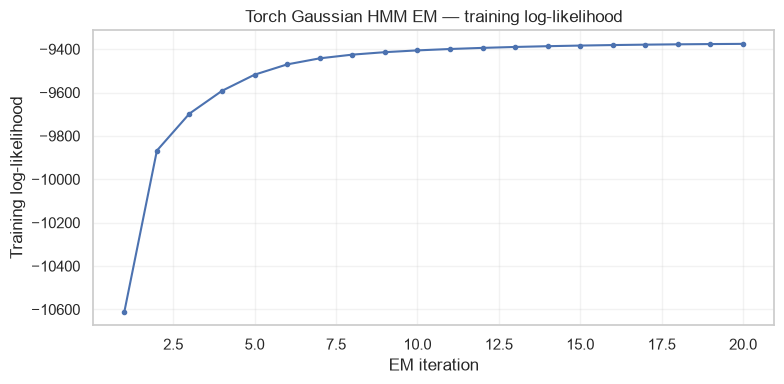

In [66]:
device_for_torch = "cuda" if torch.cuda.is_available() else "cpu"

# Single CPU reference fit using the same K and iteration cap as the Torch experiment.
cpu_ref_model = GaussianHMM(
    n_components=BASELINE_K,
    covariance_type="diag",
    n_iter=20,
    tol=1e-3,
    min_covar=1e-3,
    random_state=42,
    implementation="log",
)
start = time.perf_counter()
cpu_ref_model.fit(X_base_train)
cpu_fit_seconds = time.perf_counter() - start
cpu_ref_train_ll, _, cpu_ref_alpha_train_end = filter_segment(X_base_train, cpu_ref_model)
cpu_ref_val_ll, _, cpu_ref_alpha_val_end = filter_segment(X_base_val, cpu_ref_model, alpha_prev=cpu_ref_alpha_train_end)
cpu_ref_test_ll, _, _ = filter_segment(X_base_test, cpu_ref_model, alpha_prev=cpu_ref_alpha_val_end)

if device_for_torch == "cuda":
    torch.cuda.synchronize()
start = time.perf_counter()
torch_hmm_model = TorchGaussianHMM(
    n_components=BASELINE_K,
    max_iter=20,
    tol=1e-3,
    random_state=42,
    device=device_for_torch,
).fit(X_base_train)
if device_for_torch == "cuda":
    torch.cuda.synchronize()
torch_fit_seconds = time.perf_counter() - start

# Evaluate the Torch-fitted parameters with the same CPU forward filter.
torch_train_ll, p_torch_train, alpha_torch_train_end = filter_segment(X_base_train, torch_hmm_model)
torch_val_ll, p_torch_val, alpha_torch_val_end = filter_segment(X_base_val, torch_hmm_model, alpha_prev=alpha_torch_train_end)
torch_test_ll, p_torch_test, alpha_torch_test_end = filter_segment(X_base_test, torch_hmm_model, alpha_prev=alpha_torch_val_end)

torch_eval = pd.DataFrame([{
    "model": "TorchGaussianHMM EM",
    "device": torch_hmm_model.device_used_,
    "K": BASELINE_K,
    "fit_seconds": torch_fit_seconds,
    "EM_iterations": len(torch_hmm_model.loglik_history_),
    "last_train_loglik": torch_hmm_model.loglik_history_[-1],
    "validation_loglik_per_row": torch_val_ll / len(X_base_val),
    "test_loglik_per_row": torch_test_ll / len(X_base_test),
}])
display(torch_eval)

runtime_comparison = pd.DataFrame([
    {
        "method": "hmmlearn CPU reference",
        "device": "CPU",
        "fit_seconds": cpu_fit_seconds,
        "iterations": int(cpu_ref_model.monitor_.iter),
        "validation_loglik_per_row": cpu_ref_val_ll / len(X_base_val),
        "test_loglik_per_row": cpu_ref_test_ll / len(X_base_test),
    },
    {
        "method": "PyTorch EM",
        "device": torch_hmm_model.device_used_,
        "fit_seconds": torch_fit_seconds,
        "iterations": len(torch_hmm_model.loglik_history_),
        "validation_loglik_per_row": torch_val_ll / len(X_base_val),
        "test_loglik_per_row": torch_test_ll / len(X_base_test),
    },
])
display(runtime_comparison)
print("หมายเหตุ: implementations และ initialization ต่างกัน; เปรียบเทียบนี้เป็น engineering benchmark ไม่ใช่ controlled speedup claim")
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(torch_hmm_model.loglik_history_)+1), torch_hmm_model.loglik_history_, marker="o", markersize=3)
plt.title("Torch Gaussian HMM EM — training log-likelihood")
plt.xlabel("EM iteration"); plt.ylabel("Training log-likelihood")
plt.grid(True, alpha=0.25); plt.tight_layout(); plt.show()

In [67]:
# Sanity checks
assert np.isfinite(p_base_test).all()
assert np.allclose(p_base_test.sum(axis=1), 1.0, atol=1e-5)
assert np.isfinite(p_ah_test).all()
assert np.allclose(p_ah_test.sum(axis=1), 1.0, atol=1e-5)
assert np.isfinite(p_hyb_test).all()
assert np.allclose(p_hyb_test.sum(axis=1), 1.0, atol=1e-5)
print("Sanity checks passed")
print("Baseline test rows:", len(p_base_test))
print("AH-HMM test rows:", len(p_ah_test))
print("EGARCH-HMM test rows:", len(p_hyb_test))

Sanity checks passed
Baseline test rows: 939
AH-HMM test rows: 939
EGARCH-HMM test rows: 939


## สรุปผลการทดลอง 

- ข้อมูล: ราคาทองคำไทย 24,519 แถว ครอบคลุมวันที่ 1 พ.ค. 2006 – 13 ต.ค. 2026
- โมเดลพื้นฐาน: Gaussian HMM เลือก \(K=3\) แบ่งตลาดเป็น 3 States โดยใช้ 2 Features คือ `bar_buy_log_return` และ `intraday_range_pct`
- ผลบน Test set: Predictive log-likelihood = −1.8923 ต่อแถว จากข้อมูลทดสอบ 939 แถว
- State ที่น่าสนใจ: State 2 มีค่าเฉลี่ยผลตอบแทนถ่วงน้ำหนัก −0.001180 และช่วงราคาเฉลี่ย 0.008826 สะท้อนลักษณะตลาดที่ราคาลดลงและมีความผันผวนสูง จึงเป็น candidate regime ที่ควรตรวจสอบต่อ แต่ยังสรุปไม่ได้ว่าเป็นวิกฤต
- เปรียบเทียบโมเดล: EGARCH + HMM ได้ Test score −2.7347 และ AH-HMM prototype ได้ −2.5027 ซึ่งแย่กว่าโมเดลพื้นฐานในผลการทดลองนี้
- ทดลองใช้ GPU: PyTorch HMM ใช้เวลาฝึก 84.11 วินาที เทียบกับ CPU reference 0.245 วินาที หรือช้ากว่าประมาณ 344 เท่า โดยผล Test score ดีขึ้นเล็กน้อยจาก −2.6018 เป็น −2.4963 แต่การทดลองยังควบคุมความแตกต่างของการตั้งค่าโมเดลไม่ครบ จึงยังยืนยันไม่ได้ว่า GPU หรือโมเดลนั้นดีกว่า

ข้อสรุป: Gaussian HMM \\(K=3\\) เป็นจุดเริ่มต้นที่เหมาะสมที่สุดจากผลทดลองที่มี เพราะได้คะแนน Test ดีกว่าโมเดลทางเลือกที่ทดสอบ และฝึกบน CPU ได้เร็ว อย่างไรก็ตาม ต้องตรวจสอบความเสถียรของ States และเทียบกับช่วงเหตุการณ์จริงก่อนตีความว่าเป็น Regime วิกฤตหรือใช้เป็นสัญญาณซื้อขาย

### บันทึกโมเดล

In [68]:

# ค้นหาตัวแปรที่เกี่ยวข้องกับ HMM และ Scaler
for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    obj_type = type(obj).__name__
    name_lower = name.lower()

    if (
        "hmm" in name_lower
        or "scal" in name_lower
        or "model" in name_lower
    ):
        print(f"{name}: {obj_type}")


StandardScaler: type
GaussianHMM: type
model_df: DataFrame
scaler_base: StandardScaler
model_parameters: function
fit_select_hmm: function
baseline_model: GaussianHMM
baseline_models: dict
arch_model: function
scaler_hybrid: StandardScaler
hybrid_model: GaussianHMM
hybrid_models: dict
fit_ah_hmm: function
ah_model: SimpleNamespace
TorchGaussianHMM: type
cpu_ref_model: GaussianHMM
torch_hmm_model: TorchGaussianHMM


In [69]:

from pathlib import Path
from datetime import datetime, timezone
import joblib
import json

# ใช้โมเดล Baseline ที่ฝึกไว้แล้ว ไม่ฝึกใหม่
MODEL_DIR = Path(r"D:\Project_Github\gold assisstant\model\gold_hmm_v1")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

feature_cols = [
    "bar_buy_log_return",
    "intraday_range_pct",
]

# ตรวจสอบจำนวน States ก่อนบันทึก
assert baseline_model.n_components == 3, (
    f"Expected K=3, got K={baseline_model.n_components}"
)

bundle = {
    "model": baseline_model,
    "scaler": scaler_base,
    "feature_cols": feature_cols,
    "model_name": "GaussianHMM",
    "n_states": baseline_model.n_components,
    "model_version": "1.0.0",
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
}

model_path = MODEL_DIR / "model.joblib"
joblib.dump(bundle, model_path)

metadata = {
    "model_name": "GaussianHMM",
    "model_version": "1.0.0",
    "n_states": baseline_model.n_components,
    "feature_cols": feature_cols,
    "training_method": "hmmlearn",
    "device": "CPU",
    "purpose": "Thai gold market regime analysis",
    "limitations": [
        "States are statistical regimes, not confirmed crisis labels.",
        "Not a standalone crisis predictor or trading signal.",
    ],
}

with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Model saved:", model_path.resolve())
print("K =", baseline_model.n_components)
print("Features =", feature_cols)


Model saved: D:\Project_Github\gold assisstant\model\gold_hmm_v1\model.joblib
K = 3
Features = ['bar_buy_log_return', 'intraday_range_pct']


In [70]:

loaded_bundle = joblib.load(model_path)

loaded_model = loaded_bundle["model"]
loaded_scaler = loaded_bundle["scaler"]

print("Model type:", type(loaded_model).__name__)
print("Number of states:", loaded_model.n_components)
print("Features:", loaded_bundle["feature_cols"])

assert loaded_model.n_components == baseline_model.n_components
assert loaded_bundle["feature_cols"] == feature_cols

print("PASS: Model bundle loaded successfully.")


Model type: GaussianHMM
Number of states: 3
Features: ['bar_buy_log_return', 'intraday_range_pct']
PASS: Model bundle loaded successfully.


## ทดสอบกับ thaillm

In [71]:
import os
import requests

THAILLM_API_KEY = os.environ.get("THAILLM_API_KEY")

if not THAILLM_API_KEY:
    raise ValueError(
        "กรุณาตั้ง Environment Variable ชื่อ THAILLM_API_KEY ก่อน"
    )

BASE_URL = "http://thaillm.or.th/api/v1"
CHAT_URL = f"{BASE_URL}/chat/completions"

MODEL_NAME = "pathumma-thaillm-qwen3-8b-think-3.0.0"

headers = {
    "Authorization": f"Bearer {THAILLM_API_KEY}",
    "Content-Type": "application/json"
}

print("ThaiLLM configuration ready")

ThaiLLM configuration ready


In [72]:
import json
import joblib
import numpy as np
from pathlib import Path

MODEL_PATH = Path(r"D:\Project_Github\gold assisstant\model\gold_hmm_v1\model.joblib")

bundle = joblib.load(MODEL_PATH)

hmm_model = bundle["model"]
scaler = bundle["scaler"]
FEATURE_COLS = bundle["feature_cols"]

assert FEATURE_COLS == [
    "bar_buy_log_return",
    "intraday_range_pct"
]

def inspect_market_regime(
    bar_buy_log_return: float,
    intraday_range_pct: float
) -> dict:
    """
    ตรวจสอบความน่าจะเป็นของแต่ละ Regime
    จาก Features ของข้อมูลตลาดหนึ่งช่วงเวลา
    """

    values = np.array([[
        bar_buy_log_return,
        intraday_range_pct
    ]], dtype=float)

    if not np.isfinite(values).all():
        raise ValueError("Features ต้องเป็นตัวเลข finite")

    if intraday_range_pct < 0:
        raise ValueError("intraday_range_pct ต้องไม่ติดลบ")

    # ใช้ scaler เดิมจากขั้นตอนฝึกโมเดล
    X_scaled = scaler.transform(values)

    # ประเมิน posterior ของ state สำหรับ observation นี้
    probabilities = hmm_model.predict_proba(X_scaled)[0]

    state = int(np.argmax(probabilities))

    return {
        "state": state,
        "probabilities": {
            f"state_{i}": round(float(p), 6)
            for i, p in enumerate(probabilities)
        },
        "features": {
            "bar_buy_log_return": float(bar_buy_log_return),
            "intraday_range_pct": float(intraday_range_pct)
        },
        "warning": (
            "State เป็นกลุ่มทางสถิติ ไม่ใช่ป้ายยืนยันว่าวิกฤต "
            "และการประเมินจากแถวเดียวไม่เทียบเท่าการกรอง "
            "HMM ตามลำดับเวลาทั้งชุด"
        )
    }

print("HMM function ready")

HMM function ready


In [73]:
tool_test = [
    {
        "type": "function",
        "function": {
            "name": "inspect_market_regime",
            "description": "ตรวจสอบ Regime ของราคาทองคำจาก HMM",
            "parameters": {
                "type": "object",
                "properties": {
                    "bar_buy_log_return": {"type": "number"},
                    "intraday_range_pct": {"type": "number"}
                },
                "required": [
                    "bar_buy_log_return",
                    "intraday_range_pct"
                ],
                "additionalProperties": False
            }
        }
    }
]

payload = {
    "model": MODEL_NAME,
    "messages": [
        {
            "role": "user",
            "content": (
                "ช่วยตรวจสอบ Regime โดยเรียก inspect_market_regime "
                "ด้วย bar_buy_log_return=0.001 "
                "และ intraday_range_pct=0.005"
            )
        }
    ],
    "tools": tool_test,
    "tool_choice": "required",
    "temperature": 0.1,
    "max_tokens": 512
}

response = requests.post(
    CHAT_URL,
    headers=headers,
    json=payload,
    timeout=90
)

print("HTTP status:", response.status_code)
print(response.text[:4000])
response.raise_for_status()

result = response.json()
message = result["choices"][0]["message"]

print("Tool calls:", message.get("tool_calls"))
print("Text:", message.get("content"))

HTTP status: 200
{"id":"chatcmpl-f2a691eaaf443ff51fe201454e05d83b","object":"chat.completion","created":1792742564,"model":"pathumma-thaillm-qwen3-8b-think-3.0.0","choices":[{"index":0,"message":{"role":"assistant","reasoning_content":null,"content":"","tool_calls":[{"id":"chatcmpl-tool-d920ea0dd5d144a0a04b53cbe9699387","type":"function","function":{"name":"inspect_market_regime","arguments":"{\"intraday_range_pct\": 0.005, \"bar_buy_log_return\": 0.001}"}}]},"logprobs":null,"finish_reason":"stop","stop_reason":null}],"usage":{"prompt_tokens":223,"total_tokens":265,"completion_tokens":42,"prompt_tokens_details":null},"prompt_logprobs":null,"kv_transfer_params":null}
Tool calls: [{'id': 'chatcmpl-tool-d920ea0dd5d144a0a04b53cbe9699387', 'type': 'function', 'function': {'name': 'inspect_market_regime', 'arguments': '{"intraday_range_pct": 0.005, "bar_buy_log_return": 0.001}'}}]
Text: 


In [74]:
import json

def ask_gold_assistant(question: str) -> str:
    messages = [
        {
            "role": "system",
            "content": (
                "คุณเป็นผู้ช่วยวิเคราะห์ตลาดทองคำไทย "
                "เมื่อผู้ใช้ถามถึง Regime ให้เรียกเครื่องมือ "
                "inspect_market_regime โดยใช้ตัวเลขจากผู้ใช้ "
                "หรือข้อมูลที่ระบบให้มาเท่านั้น "
                "ห้ามแต่งผลการคำนวณขึ้นเอง "
                "State เป็นกลุ่มทางสถิติ ไม่ใช่คำยืนยันว่าวิกฤต"
            )
        },
        {"role": "user", "content": question}
    ]

    payload = {
        "model": MODEL_NAME,
        "messages": messages,
        "tools": tool_test,
        "tool_choice": "auto",
        "temperature": 0.1,
        "max_tokens": 1024
    }

    r = requests.post(
        CHAT_URL,
        headers=headers,
        json=payload,
        timeout=90
    )
    r.raise_for_status()

    message = r.json()["choices"][0]["message"]
    tool_calls = message.get("tool_calls") or []

    if not tool_calls:
        return message.get("content") or (
            "โมเดลไม่ได้เรียกเครื่องมือ"
        )

    # เก็บข้อความ assistant ที่มี tool_calls ไว้ในประวัติ
    messages.append(message)

    for call in tool_calls:
        function_name = call["function"]["name"]

        if function_name != "inspect_market_regime":
            raise ValueError(f"ไม่อนุญาตให้เรียก {function_name}")

        args = json.loads(call["function"]["arguments"])

        # เรียก Python Function จริง
        tool_result = inspect_market_regime(
            bar_buy_log_return=float(args["bar_buy_log_return"]),
            intraday_range_pct=float(args["intraday_range_pct"])
        )

        messages.append({
            "role": "tool",
            "tool_call_id": call["id"],
            "content": json.dumps(
                tool_result,
                ensure_ascii=False
            )
        })

    # ส่งผลจาก HMM กลับให้ ThaiLLM อธิบาย
    payload["messages"] = messages
    payload["tool_choice"] = "none"

    r = requests.post(
        CHAT_URL,
        headers=headers,
        json=payload,
        timeout=90
    )
    r.raise_for_status()

    return (
        r.json()["choices"][0]["message"].get("content")
        or "ไม่มีข้อความตอบกลับ"
    )

In [75]:
print(
    ask_gold_assistant(
        "ช่วยวิเคราะห์ Regime โดยใช้ "
        "bar_buy_log_return=0.001 และ "
        "intraday_range_pct=0.005"
    )
)

<think>
Okay, let's see. The user asked for a regime analysis using bar_buy_log_return=0.001 and intraday_range_pct=0.005. The tool response came back with state 1, which is a high probability (0.999285) of being in state 1, and very low probabilities for states 0 and 2.

First, I need to interpret what state 1 means. Since the tool's documentation isn't provided, I should rely on the warning message. The warning says that state is a statistical group, not a confirmation of a crisis. Also, the analysis is based on a single bar, which isn't as reliable as a full HMM sequence.

So, the user might be expecting a conclusion about the market regime. But with only one data point, the result is uncertain. The high probability in state 1 could indicate a bullish trend, but I shouldn't be too confident. The user might not realize that a single observation isn't enough for a reliable assessment.

I should explain the result clearly, mention the limitations of using a single data point, and advis

In [76]:
# คำนวณผลลัพธ์จากฟังก์ชัน HMM ก่อนตรวจ assert
result = inspect_market_regime(
    bar_buy_log_return=0.001, intraday_range_pct=0.005
)

probs = result["probabilities"]

# ตรวจว่าความน่าจะเป็นรวมกันได้ประมาณ 1
assert abs(sum(probs.values()) - 1.0) < 1e-5

# แปลงชื่อ state_1 ให้เป็นเลข 1 ก่อนเปรียบเทียบ
most_likely_state = int(max(probs, key=probs.get).split("_")[1])

assert result["state"] == most_likely_state

print("PASS: State และ probabilities สอดคล้องกัน")
print("Predicted state:", result["state"])
print("Probability:", probs[f"state_{result['state']}"])


PASS: State และ probabilities สอดคล้องกัน
Predicted state: 1
Probability: 0.999285


# เทียบกับตลาดอื่น

ทดสอบว่า การเพิ่มข้อมูล Gold Spot และ USD/THB ช่วยให้ HMM ตรวจจับ market regimes ของทองไทยได้ดีขึ้นกว่าการใช้ข้อมูลทองไทยเพียงอย่างเดียวหรือไม่

In [77]:
cross_cols = [
    "timestamp_parsed",
    "bar_buy",
    "bar_sell",
    "gold_spot_clean",
    "thb_usd_clean"
]

# ตรวจว่าคอลัมน์ที่ต้องใช้มีครบ
missing = [
    c for c in cross_cols
    if c not in df_market_eda.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# ตรวจจำนวนข้อมูลและจำนวนค่าที่ไม่ซ้ำ
audit = pd.DataFrame({
    "dtype": df_market_eda[cross_cols].dtypes.astype(str),
    "non_null": df_market_eda[cross_cols].notna().sum(),
    "missing": df_market_eda[cross_cols].isna().sum(),
    "unique": df_market_eda[cross_cols].nunique(),
})

print("=== Cross-Market Data Audit ===")
display(audit)

# ตรวจค่าที่ไม่ใช่ตัวเลข
for col in cross_cols[1:]:
    numeric = pd.to_numeric(
        df_market_eda[col], errors="coerce"
    )
    print(
        f"{col}: "
        f"non-numeric = "
        f"{(df_market_eda[col].notna() & numeric.isna()).sum()}, "
        f"zero = {(numeric == 0).sum()}, "
        f"negative = {(numeric < 0).sum()}"
    )

# ดูตัวอย่างข้อมูล
display(df_market_eda[cross_cols].head(10))

=== Cross-Market Data Audit ===


,dtype,non_null,missing,unique
timestamp_parsed,datetime64[us],24519,0,24511
bar_buy,float64,24519,0,1320
bar_sell,float64,24519,0,1321
gold_spot_clean,float64,23965,554,6761
thb_usd_clean,float64,23718,801,947


bar_buy: non-numeric = 0, zero = 0, negative = 0
bar_sell: non-numeric = 0, zero = 0, negative = 0
gold_spot_clean: non-numeric = 0, zero = 0, negative = 0
thb_usd_clean: non-numeric = 0, zero = 0, negative = 0


,timestamp_parsed,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean
0,2006-05-01 09:30:00,11450.0,11550.0,648.64,37.33
1,2006-05-02 09:30:00,11500.0,11600.0,656.25,37.61
2,2006-05-02 11:50:00,11550.0,11650.0,657.05,NaN
3,2006-05-03 09:30:00,11750.0,11850.0,668.90,37.58
4,2006-05-03 10:45:00,11900.0,12000.0,675.90,37.61
5,2006-05-03 11:15:00,11800.0,11900.0,669.20,37.62
6,2006-05-03 14:00:00,11850.0,11950.0,674.30,37.56
7,2006-05-04 10:21:00,11850.0,11950.0,666.30,37.78
8,2006-05-06 09:30:00,12150.0,12250.0,683.50,37.83
9,2006-05-08 09:30:00,12100.0,12200.0,681.75,37.62


In [78]:
df_cross_audit = df_market_eda.copy()

# 1. ตรวจ Missing Values แยกตามปี
df_cross_audit["date"] = (
    df_cross_audit["timestamp_parsed"].dt.date
)
df_cross_audit["year"] = (
    df_cross_audit["timestamp_parsed"].dt.year
)

missing_by_year = (
    df_cross_audit.groupby("year")
    .agg(
        total_rows=("timestamp_parsed", "size"),
        gold_spot_missing=("gold_spot_clean",
                           lambda s: s.isna().sum()),
        thb_usd_missing=("thb_usd_clean",
                         lambda s: s.isna().sum()),
    )
)

missing_by_year["gold_spot_missing_pct"] = (
    100 * missing_by_year["gold_spot_missing"]
    / missing_by_year["total_rows"]
)

missing_by_year["thb_usd_missing_pct"] = (
    100 * missing_by_year["thb_usd_missing"]
    / missing_by_year["total_rows"]
)

print("=== Missing Values by Year ===")
display(missing_by_year.round(2))

# 2. ตรวจ Timestamp ที่ซ้ำ
duplicate_mask = df_cross_audit[
    "timestamp_parsed"
].duplicated(keep=False)

duplicates = (
    df_cross_audit.loc[
        duplicate_mask,
        [
            "timestamp_parsed",
            "bar_buy",
            "bar_sell",
            "gold_spot_clean",
            "thb_usd_clean",
        ],
    ]
    .sort_values("timestamp_parsed")
)

print("=== Duplicate Timestamp Rows ===")
print("Rows involved:", len(duplicates))
print(
    "Duplicate timestamp values:",
    duplicates["timestamp_parsed"].nunique()
)
display(duplicates)

# 3. ตรวจ Missing Values ที่เกิดพร้อมกัน
missing_pattern = pd.DataFrame({
    "both_present": (
        df_cross_audit["gold_spot_clean"].notna()
        & df_cross_audit["thb_usd_clean"].notna()
    ),
    "gold_only_missing": (
        df_cross_audit["gold_spot_clean"].isna()
        & df_cross_audit["thb_usd_clean"].notna()
    ),
    "fx_only_missing": (
        df_cross_audit["gold_spot_clean"].notna()
        & df_cross_audit["thb_usd_clean"].isna()
    ),
    "both_missing": (
        df_cross_audit["gold_spot_clean"].isna()
        & df_cross_audit["thb_usd_clean"].isna()
    ),
})

print("=== Missing Pattern Counts ===")
display(missing_pattern.sum().to_frame("rows"))


=== Missing Values by Year ===


,total_rows,gold_spot_missing,thb_usd_missing,gold_spot_missing_pct,thb_usd_missing_pct
year,,,,,
2006,299,10,12,3.34,4.01
2007,390,4,4,1.03,1.03
2008,732,19,38,2.60,5.19
2009,638,1,67,0.16,10.50
2010,631,49,66,7.77,10.46
2011,1040,52,68,5.00,6.54
2012,785,52,62,6.62,7.90
2013,1001,53,61,5.29,6.09
2014,775,51,60,6.58,7.74


=== Duplicate Timestamp Rows ===
Rows involved: 16
Duplicate timestamp values: 8


,timestamp_parsed,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean
126,2006-07-18 14:40:00,11750.0,11850.0,652.2,38.18
127,2006-07-18 14:40:00,11700.0,11800.0,647.8,38.17
805,2008-03-06 15:28:00,14700.0,14800.0,991.0,31.58
806,2008-03-06 15:28:00,14600.0,14700.0,985.0,31.58
957,2008-05-28 15:35:00,13700.0,13800.0,897.5,32.27
958,2008-05-28 15:35:00,13800.0,13900.0,908.1,32.27
1147,2008-08-30 09:30:00,13450.0,13550.0,832.0,34.25
1148,2008-08-30 09:30:00,14500.0,14600.0,926.2,33.52
2034,2009-12-17 10:16:00,17700.0,17800.0,1126.0,33.25
2035,2009-12-17 10:16:00,17800.0,17900.0,1134.0,33.25


=== Missing Pattern Counts ===


,rows
both_present,23713
gold_only_missing,5
fx_only_missing,252
both_missing,549


In [79]:

# ตรวจสอบ Timestamp ซ้ำ โดยไม่ลบหรือแก้ไขข้อมูล
df_dup_check = df_market_eda.copy()
df_dup_check["_original_row"] = range(len(df_dup_check))

dup_mask = df_dup_check["timestamp_parsed"].duplicated(
    keep=False
)

dup_rows = df_dup_check.loc[dup_mask].sort_values(
    ["timestamp_parsed", "_original_row"]
)

# ตรวจว่าข้อมูลซ้ำกันทุกคอลัมน์จริงหรือไม่
original_cols = list(df_market_eda.columns)
exact_duplicate_mask = df_market_eda.duplicated(
    subset=original_cols,
    keep=False
)

print("=== Duplicate Summary ===")
print("Rows with repeated timestamps:", len(dup_rows))
print(
    "Repeated timestamp values:",
    dup_rows["timestamp_parsed"].nunique()
)
print(
    "Rows involved in exact duplicate groups:",
    int(exact_duplicate_mask.sum())
)
print(
    "Exact duplicate rows beyond first occurrence:",
    int(df_market_eda.duplicated(
        subset=original_cols,
        keep="first"
    ).sum())
)

# แสดงทุกแถวที่มี Timestamp ซ้ำ พร้อมลำดับเดิม
show_cols = [
    "_original_row",
    "timestamp_parsed",
    "bar_buy",
    "bar_sell",
    "gold_spot_clean",
    "thb_usd_clean",
]

display(dup_rows[show_cols])

# ตรวจดูแถวก่อนหน้าและถัดไปของ Timestamp ที่ซ้ำ
for ts in dup_rows["timestamp_parsed"].drop_duplicates():
    pos = df_market_eda.index[
        df_market_eda["timestamp_parsed"].eq(ts)
    ].tolist()

    print(f"\n=== Timestamp: {ts} | Original indices: {pos} ===")

    lo = max(min(pos) - 2, 0)
    hi = min(max(pos) + 3, len(df_market_eda))

    display(
        df_market_eda.iloc[lo:hi][
            [
                "timestamp_parsed",
                "bar_buy",
                "bar_sell",
                "gold_spot_clean",
                "thb_usd_clean",
            ]
        ]
    )


=== Duplicate Summary ===
Rows with repeated timestamps: 16
Repeated timestamp values: 8
Rows involved in exact duplicate groups: 0
Exact duplicate rows beyond first occurrence: 0


,_original_row,timestamp_parsed,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean
126,126,2006-07-18 14:40:00,11750.0,11850.0,652.2,38.18
127,127,2006-07-18 14:40:00,11700.0,11800.0,647.8,38.17
805,805,2008-03-06 15:28:00,14700.0,14800.0,991.0,31.58
806,806,2008-03-06 15:28:00,14600.0,14700.0,985.0,31.58
957,957,2008-05-28 15:35:00,13700.0,13800.0,897.5,32.27
958,958,2008-05-28 15:35:00,13800.0,13900.0,908.1,32.27
1147,1147,2008-08-30 09:30:00,13450.0,13550.0,832.0,34.25
1148,1148,2008-08-30 09:30:00,14500.0,14600.0,926.2,33.52
2034,2034,2009-12-17 10:16:00,17700.0,17800.0,1126.0,33.25
2035,2035,2009-12-17 10:16:00,17800.0,17900.0,1134.0,33.25



=== Timestamp: 2006-07-18 14:40:00 | Original indices: [126, 127] ===


,timestamp_parsed,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean
124,2006-07-17 09:27:00,12100.0,12200.0,674.0,38.15
125,2006-07-17 12:30:00,12150.0,12250.0,675.0,38.15
126,2006-07-18 14:40:00,11750.0,11850.0,652.2,38.18
127,2006-07-18 14:40:00,11700.0,11800.0,647.8,38.17
128,2006-07-19 09:15:00,11400.0,11500.0,632.7,38.19
129,2006-07-19 10:00:00,11350.0,11450.0,630.0,38.20



=== Timestamp: 2008-03-06 15:28:00 | Original indices: [805, 806] ===


,timestamp_parsed,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean
803,2008-03-05 11:50:00,14400.0,14500.0,965.5,31.62
804,2008-03-06 14:40:00,14650.0,14750.0,988.0,31.58
805,2008-03-06 15:28:00,14700.0,14800.0,991.0,31.58
806,2008-03-06 15:28:00,14600.0,14700.0,985.0,31.58
807,2008-03-06 16:38:00,14650.0,14750.0,988.5,31.56
808,2008-03-07 09:30:00,14600.0,14700.0,981.8,31.58


... (8 outputs left out)


=== Timestamp: 2009-12-30 15:42:00 | Original indices: [2057, 2058] ===


,timestamp_parsed,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean
2055,2009-12-30 09:36:00,17300.0,17400.0,1094.5,33.40
2056,2009-12-30 09:36:00,17300.0,17400.0,1094.5,33.40
2057,2009-12-30 15:42:00,17250.0,17350.0,1091.5,33.40
2058,2009-12-30 15:42:00,17250.0,17350.0,1091.5,33.40
2059,2010-01-04 09:22:00,17300.0,17400.0,1098.0,33.35
2060,2010-01-04 11:49:00,17350.0,17450.0,1102.0,33.35



=== Timestamp: 2011-12-05 00:00:00 | Original indices: [3642, 3643] ===


,timestamp_parsed,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean
3640,2011-12-02 17:11:00,25450.0,25550.0,1753.0,30.80
3641,2011-12-03 09:23:00,25400.0,25500.0,NaN,NaN
3642,2011-12-05 00:00:00,25450.0,25550.0,1748.5,NaN
3643,2011-12-05 00:00:00,25400.0,25500.0,1744.5,NaN
3644,2011-12-06 09:25:00,25150.0,25250.0,1722.0,30.89
3645,2011-12-06 10:49:00,25100.0,25200.0,1716.0,30.92


In [80]:


# 1. สร้างสำเนา ไม่แก้ไขข้อมูลต้นฉบับ
df_phase_d = df_market_eda.copy()

df_phase_d["date"] = (
    df_phase_d["timestamp_parsed"].dt.normalize()
)

# 2. เลือกแถวสุดท้ายของแต่ละวันตามลำดับเดิม
df_daily_d = (
    df_phase_d
    .groupby("date", sort=True, as_index=False)
    .tail(1)
    .sort_values("date")
    .reset_index(drop=True)
)

# 3. สร้าง Log Returns
# ใช้ pct/log change จากวันก่อนหน้าใน Daily Dataset
df_daily_d["thai_gold_return"] = np.log(
    df_daily_d["bar_buy"]
    / df_daily_d["bar_buy"].shift(1)
)

df_daily_d["global_gold_return"] = np.log(
    df_daily_d["gold_spot_clean"]
    / df_daily_d["gold_spot_clean"].shift(1)
)

df_daily_d["usd_thb_return"] = np.log(
    df_daily_d["thb_usd_clean"]
    / df_daily_d["thb_usd_clean"].shift(1)
)

# 4. ตรวจจำนวนข้อมูลที่ใช้ได้
feature_cols = [
    "thai_gold_return",
    "global_gold_return",
    "usd_thb_return",
]

print("=== Phase D: Daily Dataset ===")
print("Original rows:", len(df_market_eda))
print("Daily rows:", len(df_daily_d))
print("Date range:",
      df_daily_d["date"].min(),
      "to",
      df_daily_d["date"].max())

print("\n=== Feature Availability ===")
display(
    df_daily_d[feature_cols]
    .agg(["count", "mean", "std", "min", "max"])
    .T
)

print("\n=== Missing Values ===")
display(df_daily_d[feature_cols].isna().sum().to_frame("missing"))

print("\n=== Sample ===")
display(
    df_daily_d[
        ["date", "bar_buy", "gold_spot_clean",
         "thb_usd_clean"] + feature_cols
    ].tail(10)
)


=== Phase D: Daily Dataset ===
Original rows: 24519
Daily rows: 6261
Date range: 2006-05-01 00:00:00 to 2026-10-13 00:00:00

=== Feature Availability ===


,count,mean,std,min,max
thai_gold_return,6260.0,0.000281,0.008270,-0.119844,0.074901
global_gold_return,5189.0,0.000216,0.011028,-0.115849,0.105241
usd_thb_return,4936.0,-0.000005,0.003820,-0.029687,0.030629



=== Missing Values ===


,missing
thai_gold_return,1
global_gold_return,1072
usd_thb_return,1325



=== Sample ===


,date,bar_buy,gold_spot_clean,thb_usd_clean,thai_gold_return,global_gold_return,usd_thb_return
6251,2026-10-04,65750.0,4143.0,33.60,0.000761,0.000724,0.000000
6252,2026-10-05,66150.0,4158.0,33.73,0.006065,0.003614,0.003862
6253,2026-10-06,65900.0,4153.0,33.61,-0.003786,-0.001203,-0.003564
6254,2026-10-07,65550.0,4119.0,33.70,-0.005325,-0.008221,0.002674
6255,2026-10-08,65550.0,4125.0,33.67,0.000000,0.001456,-0.000891
6256,2026-10-09,66250.0,4186.0,33.54,0.010622,0.014680,-0.003868
6257,2026-10-10,66350.0,4194.0,33.53,0.001508,0.001909,-0.000298
6258,2026-10-11,66350.0,4194.0,33.53,0.000000,0.000000,0.000000
6259,2026-10-12,66250.0,4174.0,33.63,-0.001508,-0.004780,0.002978
6260,2026-10-13,66500.0,4197.0,33.58,0.003766,0.005495,-0.001488


In [81]:

# ใช้เฉพาะวันที่มี Return ครบทั้งสามตัวแปร
df_corr_d = df_daily_d[feature_cols].dropna()

print("Rows with complete returns:", len(df_corr_d))

print("\n=== Pearson Correlation ===")
display(df_corr_d.corr(method="pearson").round(4))

print("\n=== Spearman Correlation ===")
display(df_corr_d.corr(method="spearman").round(4))


Rows with complete returns: 4935

=== Pearson Correlation ===


,thai_gold_return,global_gold_return,usd_thb_return
thai_gold_return,1.0000,0.9237,-0.1581
global_gold_return,0.9237,1.0000,-0.4519
usd_thb_return,-0.1581,-0.4519,1.0000



=== Spearman Correlation ===


,thai_gold_return,global_gold_return,usd_thb_return
thai_gold_return,1.0000,0.8918,-0.1789
global_gold_return,0.8918,1.0000,-0.5121
usd_thb_return,-0.1789,-0.5121,1.0000


In [82]:

# Phase D — Step 1: Verify existing daily features

required_cols = [
    "date",
    "bar_buy",
    "gold_spot_clean",
    "thb_usd_clean",
    "thai_gold_return",
    "global_gold_return",
    "usd_thb_return",
]

missing_cols = [
    col for col in required_cols
    if col not in df_daily_d.columns
]

print("Rows:", len(df_daily_d))
print("Date range:",
      df_daily_d["date"].min(),
      "to",
      df_daily_d["date"].max())

print("\nMissing required columns:", missing_cols)

if not missing_cols:
    print("\nReturn feature summary:")
    display(
        df_daily_d[
            [
                "thai_gold_return",
                "global_gold_return",
                "usd_thb_return",
            ]
        ].describe().T
    )

    print("\nMissing values:")
    display(
        df_daily_d[
            [
                "thai_gold_return",
                "global_gold_return",
                "usd_thb_return",
            ]
        ].isna().sum().to_frame("missing_count")
    )


Rows: 6261
Date range: 2006-05-01 00:00:00 to 2026-10-13 00:00:00

Missing required columns: []

Return feature summary:


,count,mean,std,min,25%,50%,75%,max
thai_gold_return,6260.0,0.000281,0.008270,-0.119844,-0.002926,0.00000,0.004131,0.074901
global_gold_return,5189.0,0.000216,0.011028,-0.115849,-0.004773,0.00036,0.005540,0.105241
usd_thb_return,4936.0,-0.000005,0.003820,-0.029687,-0.001821,0.00000,0.001849,0.030629



Missing values:


,missing_count
thai_gold_return,1
global_gold_return,1072
usd_thb_return,1325


### สร้าง Rolling Volatility

In [83]:
df_phase_d_features = df_daily_d.copy()
df_phase_d_features = df_phase_d_features.sort_values("date").reset_index(drop=True)

return_cols = {
    "thai_gold_return": "thai_gold",
    "global_gold_return": "global_gold",
    "usd_thb_return": "usd_thb",
}

for return_col, prefix in return_cols.items():
    for window in [5, 20]:
        feature_col = f"{prefix}_volatility_{window}d"

        df_phase_d_features[feature_col] = (
            df_phase_d_features[return_col]
            .rolling(window=window, min_periods=window)
            .std()
        )

volatility_cols = [
    "thai_gold_volatility_5d",
    "thai_gold_volatility_20d",
    "global_gold_volatility_5d",
    "global_gold_volatility_20d",
    "usd_thb_volatility_5d",
    "usd_thb_volatility_20d",
]

print("Rows:", len(df_phase_d_features))

print("\nRolling volatility summary:")
display(df_phase_d_features[volatility_cols].describe().T)

print("\nMissing values:")
display(
    df_phase_d_features[volatility_cols]
    .isna()
    .sum()
    .to_frame("missing_count")
)

print("\nCheck for negative volatility values:")
display(
    (df_phase_d_features[volatility_cols] < 0)
    .sum()
    .to_frame("negative_count")
)


Rows: 6261

Rolling volatility summary:


,count,mean,std,min,25%,50%,75%,max
thai_gold_volatility_5d,6256.0,0.006606,0.004922,0.000000,0.003603,0.005437,0.008128,0.057408
thai_gold_volatility_20d,6241.0,0.007150,0.004092,0.001561,0.004606,0.006105,0.008349,0.030164
global_gold_volatility_5d,3143.0,0.009629,0.006795,0.001106,0.005568,0.007893,0.011707,0.079866
global_gold_volatility_20d,2882.0,0.009899,0.004820,0.002911,0.006768,0.008460,0.011653,0.033467
usd_thb_volatility_5d,2711.0,0.003626,0.002249,0.000133,0.002074,0.003263,0.004634,0.016883
usd_thb_volatility_20d,2506.0,0.003938,0.001596,0.000383,0.002891,0.003780,0.004898,0.008671



Missing values:


,missing_count
thai_gold_volatility_5d,5
thai_gold_volatility_20d,20
global_gold_volatility_5d,3118
global_gold_volatility_20d,3379
usd_thb_volatility_5d,3550
usd_thb_volatility_20d,3755



Check for negative volatility values:


,negative_count
thai_gold_volatility_5d,0
thai_gold_volatility_20d,0
global_gold_volatility_5d,0
global_gold_volatility_20d,0
usd_thb_volatility_5d,0
usd_thb_volatility_20d,0


### วัดความแตกต่างระหว่างผลตอบแทนทองไทยกับตลาดอ้างอิง

In [84]:

df_phase_d_features["thai_minus_global_return"] = (
    df_phase_d_features["thai_gold_return"]
    - df_phase_d_features["global_gold_return"]
)

df_phase_d_features["thai_minus_usd_thb_return"] = (
    df_phase_d_features["thai_gold_return"]
    - df_phase_d_features["usd_thb_return"]
)

relative_cols = [
    "thai_minus_global_return",
    "thai_minus_usd_thb_return",
]

print("Relative-market feature summary:")
display(df_phase_d_features[relative_cols].describe().T)

print("\nMissing values:")
display(
    df_phase_d_features[relative_cols]
    .isna()
    .sum()
    .to_frame("missing_count")
)


Relative-market feature summary:


,count,mean,std,min,25%,50%,75%,max
thai_minus_global_return,5189.0,-9.763528e-09,0.004458,-0.066182,-0.002247,0.000000,0.002326,0.050554
thai_minus_usd_thb_return,4936.0,1.957700e-04,0.010019,-0.114323,-0.004362,0.000297,0.005155,0.096160



Missing values:


,missing_count
thai_minus_global_return,1072
thai_minus_usd_thb_return,1325


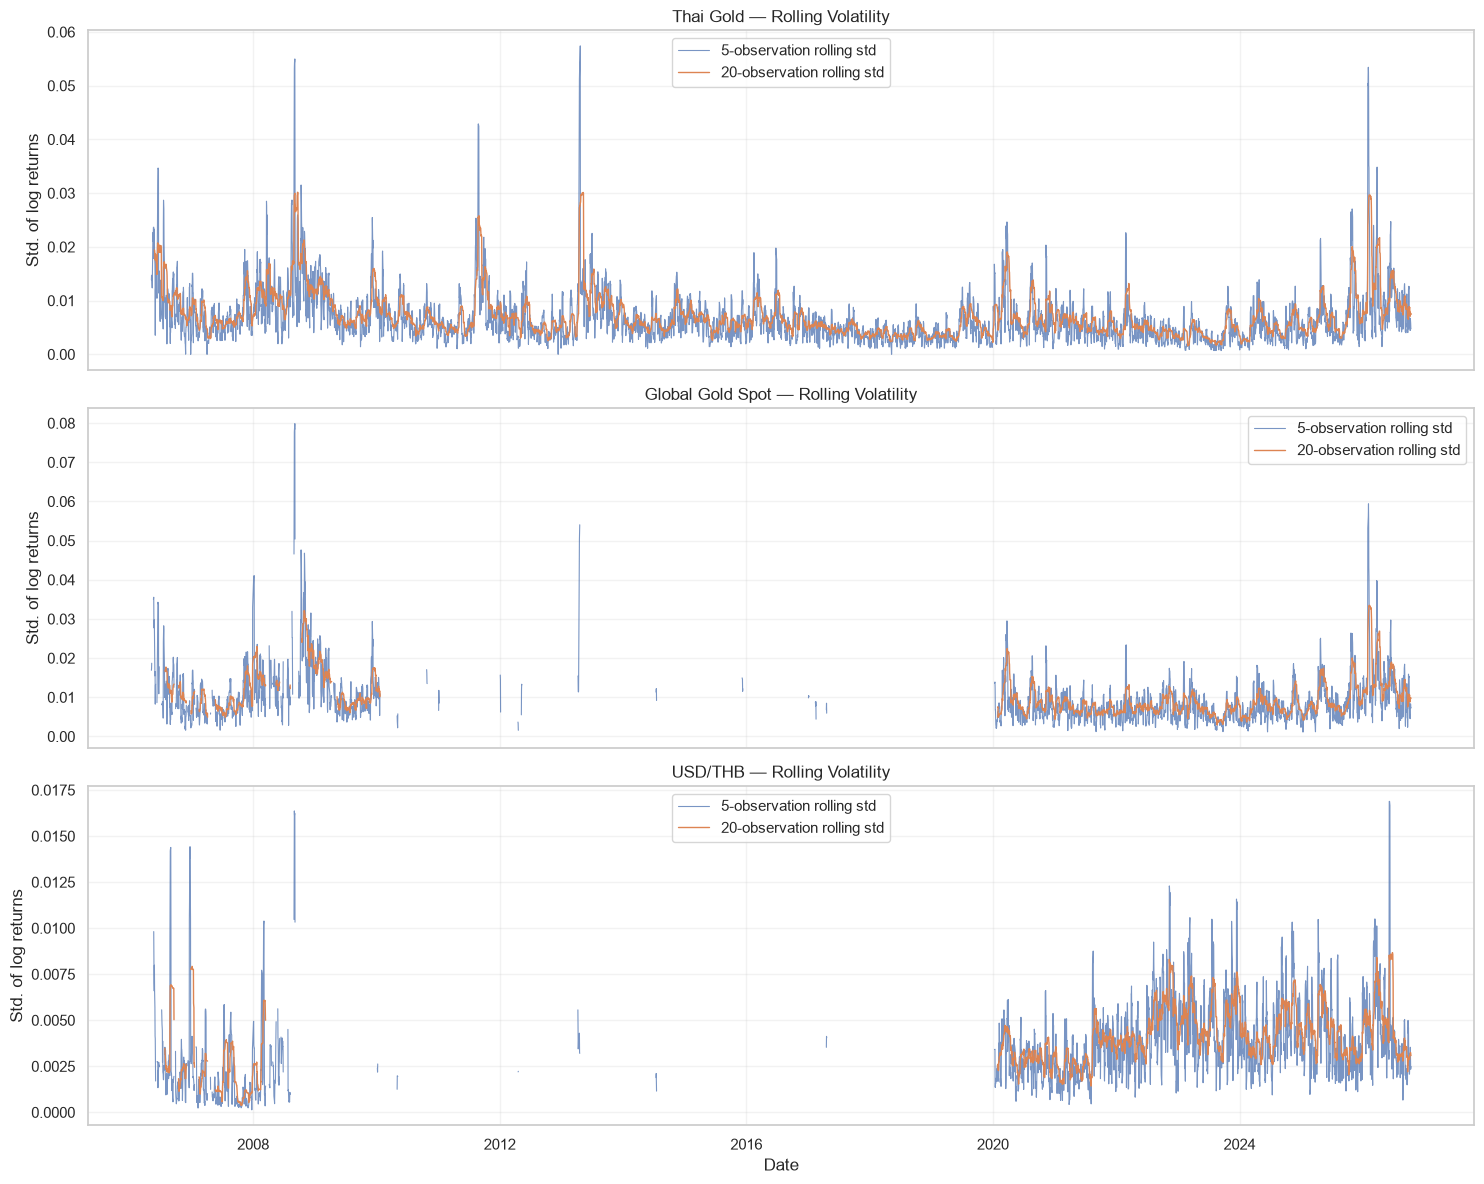

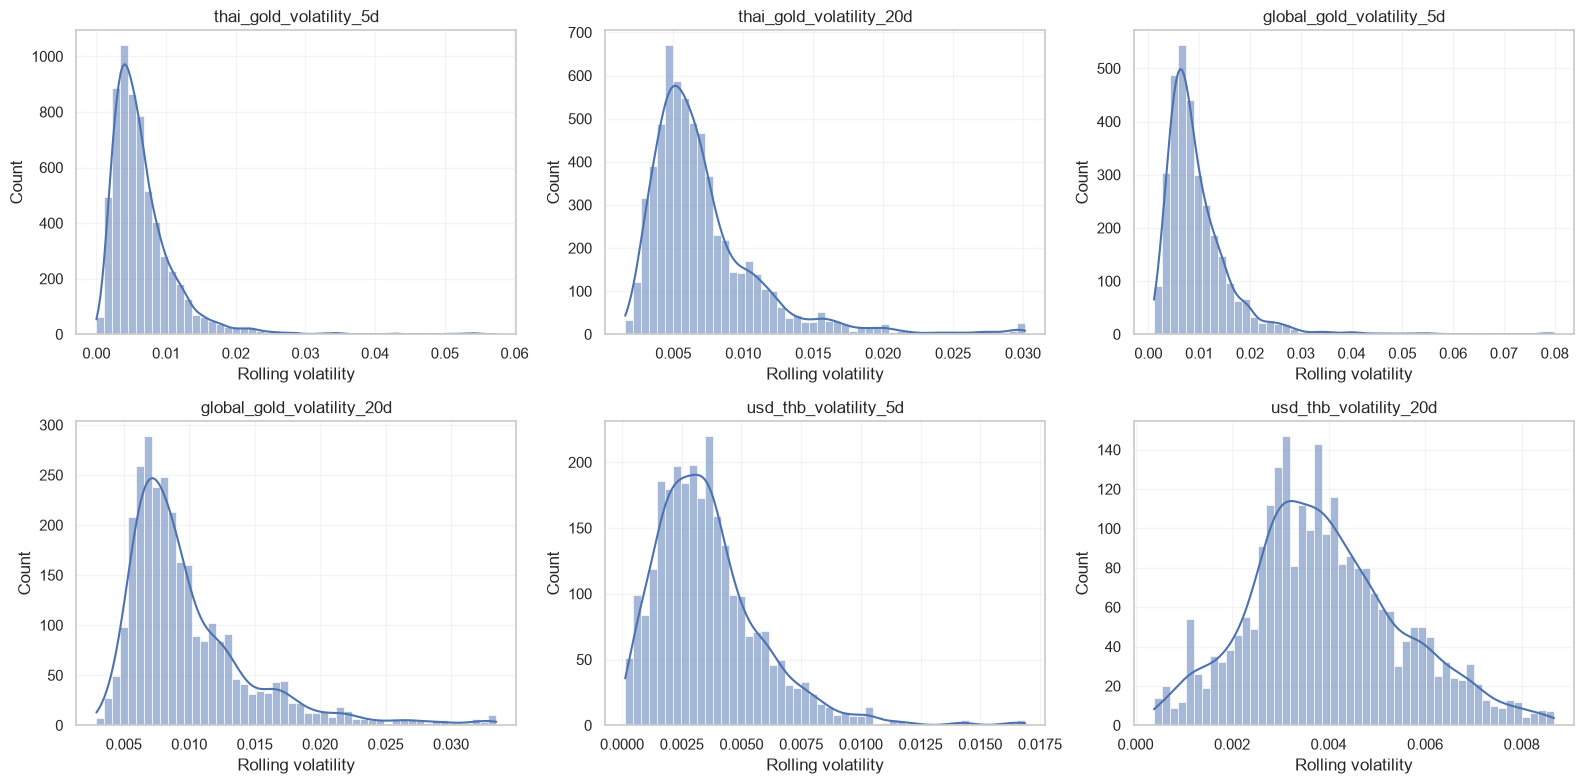

In [85]:
# 1. Rolling volatility over time
volatility_groups = [
    ("thai_gold_volatility_5d", "thai_gold_volatility_20d",
     "Thai Gold — Rolling Volatility"),
    ("global_gold_volatility_5d", "global_gold_volatility_20d",
     "Global Gold Spot — Rolling Volatility"),
    ("usd_thb_volatility_5d", "usd_thb_volatility_20d",
     "USD/THB — Rolling Volatility"),
]

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

for ax, (col5, col20, title) in zip(axes, volatility_groups):
    ax.plot(
        df_phase_d_features["date"],
        df_phase_d_features[col5],
        label="5-observation rolling std",
        alpha=0.75,
        linewidth=0.8,
    )
    ax.plot(
        df_phase_d_features["date"],
        df_phase_d_features[col20],
        label="20-observation rolling std",
        linewidth=1.0,
    )
    ax.set_title(title)
    ax.set_ylabel("Std. of log returns")
    ax.legend()
    ax.grid(True, alpha=0.25)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()


# 2. Distribution of rolling volatility
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col in zip(axes.flat, volatility_cols):
    sns.histplot(
        data=df_phase_d_features,
        x=col,
        bins=50,
        kde=True,
        ax=ax,
    )
    ax.set_title(col)
    ax.set_xlabel("Rolling volatility")
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


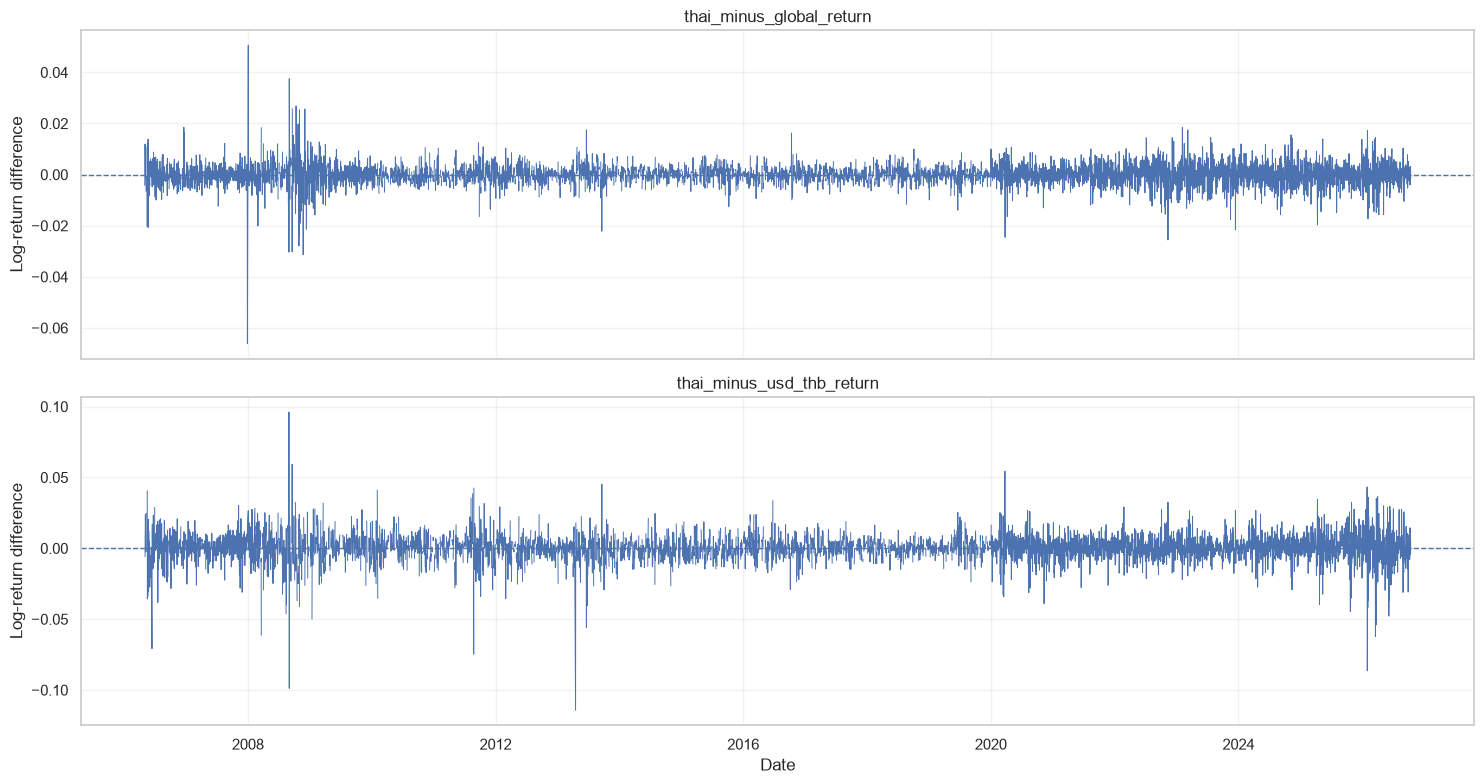

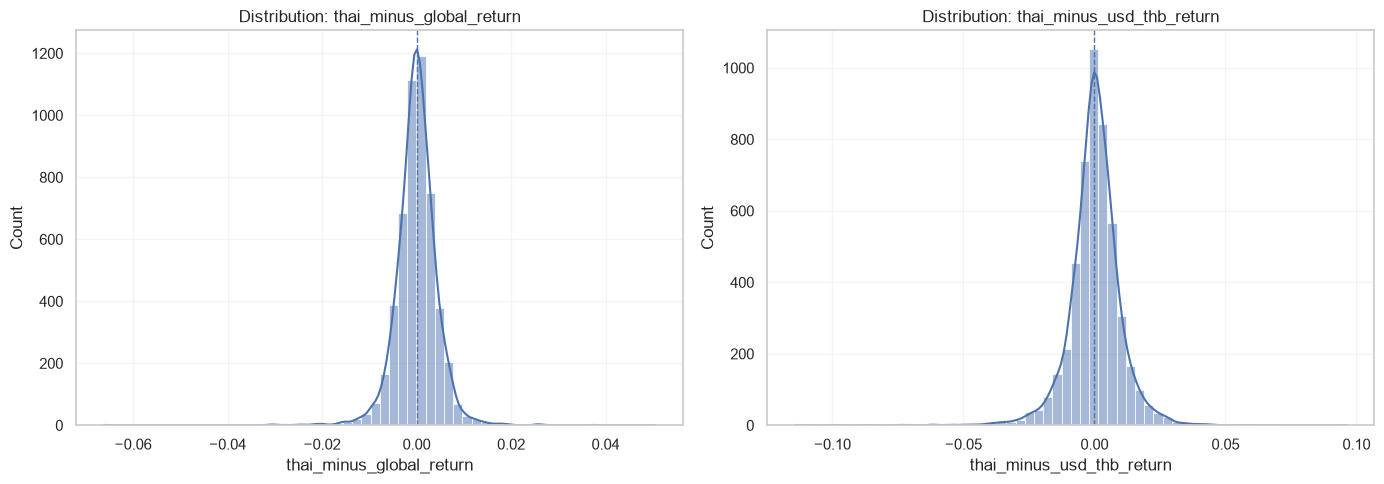

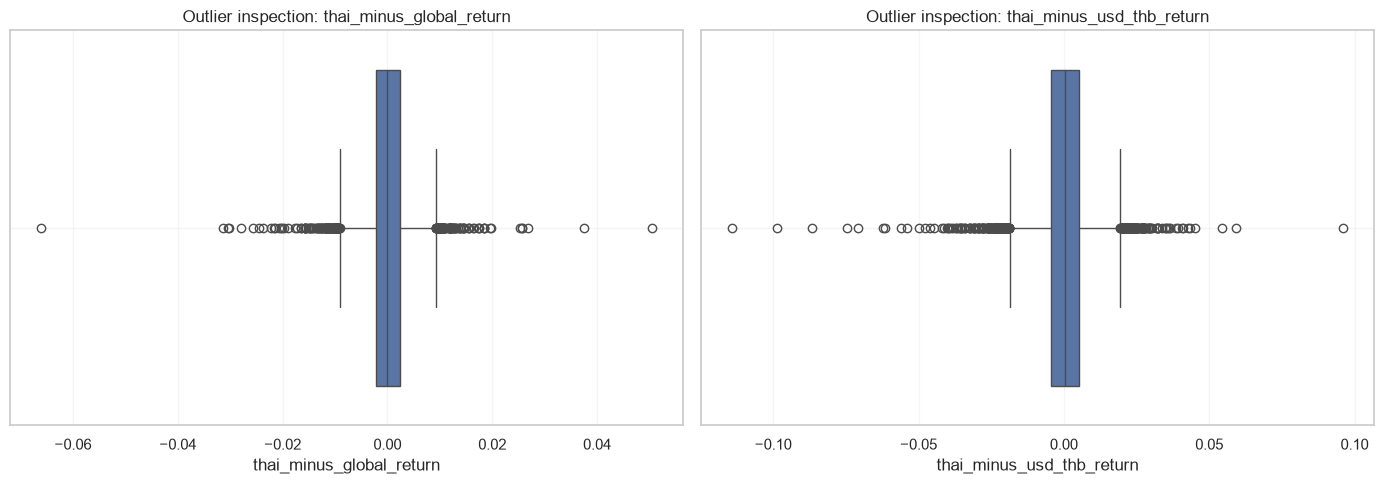

In [86]:

relative_cols = [
    "thai_minus_global_return",
    "thai_minus_usd_thb_return",
]

# 1. Relative returns over time
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

for ax, col in zip(axes, relative_cols):
    ax.plot(
        df_phase_d_features["date"],
        df_phase_d_features[col],
        linewidth=0.7,
    )
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_ylabel("Log-return difference")
    ax.grid(True, alpha=0.25)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()


# 2. Distribution and outlier visibility
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, relative_cols):
    sns.histplot(
        data=df_phase_d_features,
        x=col,
        bins=60,
        kde=True,
        ax=ax,
    )
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title(f"Distribution: {col}")
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


# 3. Boxplots for comparing spread
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, relative_cols):
    sns.boxplot(
        data=df_phase_d_features,
        x=col,
        ax=ax,
    )
    ax.set_title(f"Outlier inspection: {col}")
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


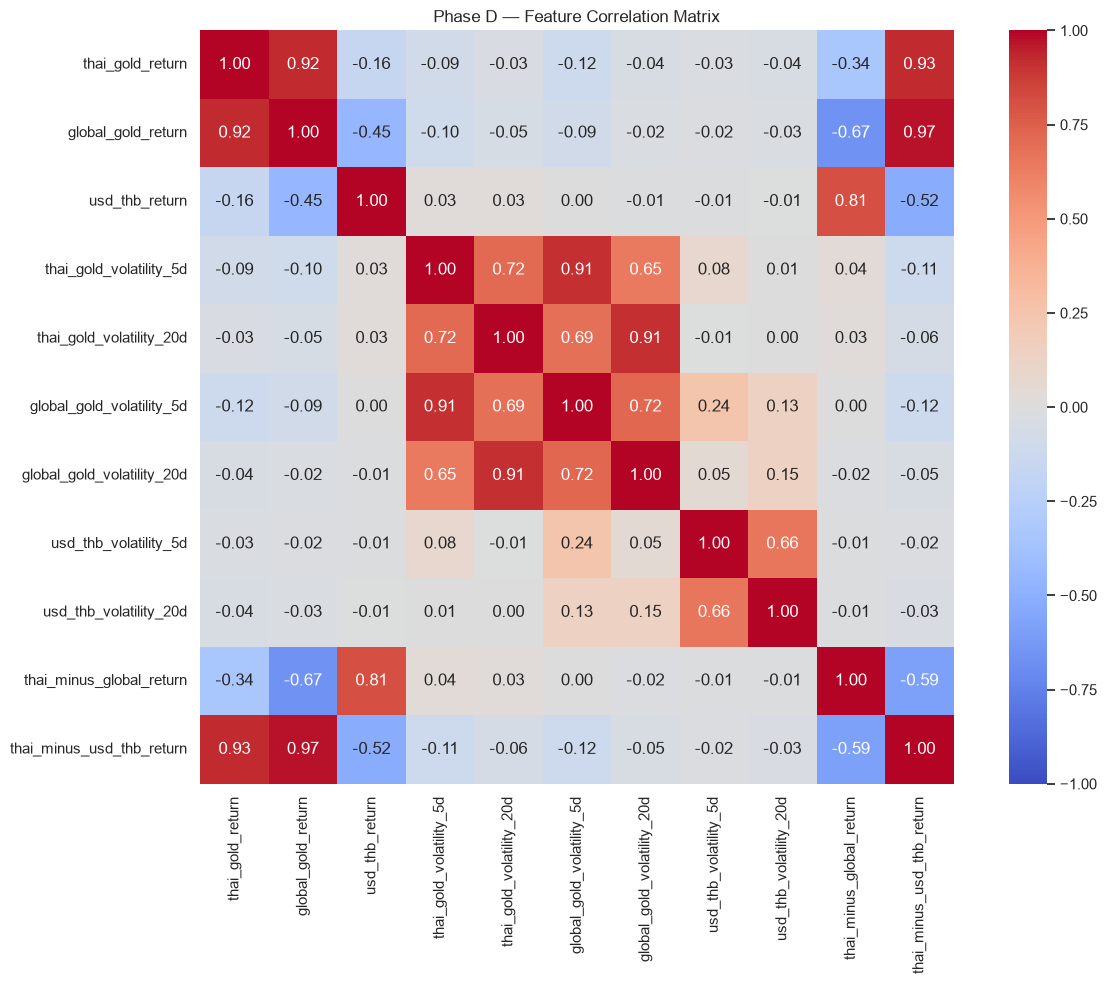

In [87]:

correlation_cols = [
    "thai_gold_return",
    "global_gold_return",
    "usd_thb_return",
    "thai_gold_volatility_5d",
    "thai_gold_volatility_20d",
    "global_gold_volatility_5d",
    "global_gold_volatility_20d",
    "usd_thb_volatility_5d",
    "usd_thb_volatility_20d",
    "thai_minus_global_return",
    "thai_minus_usd_thb_return",
]

corr = df_phase_d_features[correlation_cols].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title("Phase D — Feature Correlation Matrix")
plt.tight_layout()
plt.show()


### missing น่าสงสัย

In [88]:

# Phase D — Missing Value Diagnosis

cols = [
    "bar_buy",
    "gold_spot_clean",
    "thb_usd_clean",
    "thai_gold_return",
    "global_gold_return",
    "usd_thb_return",
    "thai_minus_global_return",
    "thai_minus_usd_thb_return",
]

# 1. Missing counts in the daily dataset
print("Missing counts:")
display(
    df_phase_d_features[cols]
    .isna()
    .sum()
    .to_frame("missing_count")
)

# 2. Separate raw-price missingness from return missingness
print("\nMissingness combinations:")

missing_patterns = pd.DataFrame({
    "gold_spot_missing": df_phase_d_features["gold_spot_clean"].isna(),
    "fx_missing": df_phase_d_features["thb_usd_clean"].isna(),
    "global_return_missing": df_phase_d_features["global_gold_return"].isna(),
    "fx_return_missing": df_phase_d_features["usd_thb_return"].isna(),
})

display(
    missing_patterns.value_counts(dropna=False)
    .rename("row_count")
    .reset_index()
)

# 3. Check whether the previous day's price is missing
for price_col, return_col in [
    ("gold_spot_clean", "global_gold_return"),
    ("thb_usd_clean", "usd_thb_return"),
]:
    previous_price_missing = (
        df_phase_d_features[price_col].shift(1).isna()
    )

    current_price_missing = (
        df_phase_d_features[price_col].isna()
    )

    print(f"\n{price_col}")
    print("Current price missing:",
          int(current_price_missing.sum()))
    print("Previous observation price missing:",
          int(previous_price_missing.sum()))
    print("Return missing:",
          int(df_phase_d_features[return_col].isna().sum()))

    print("Return missing while current price exists:",
          int((
              df_phase_d_features[return_col].isna()
              & df_phase_d_features[price_col].notna()
          ).sum()))

    print("Return missing while current and previous prices exist:",
          int((
              df_phase_d_features[return_col].isna()
              & df_phase_d_features[price_col].notna()
              & df_phase_d_features[price_col].shift(1).notna()
          ).sum()))


Missing counts:


,missing_count
bar_buy,0
gold_spot_clean,540
thb_usd_clean,691
thai_gold_return,1
global_gold_return,1072
usd_thb_return,1325
thai_minus_global_return,1072
thai_minus_usd_thb_return,1325



Missingness combinations:


,gold_spot_missing,fx_missing,global_return_missing,fx_return_missing,row_count
0,False,False,False,False,4935
1,True,True,True,True,539
2,False,False,True,True,499
3,False,False,False,True,134
4,False,True,False,True,120
5,False,True,True,True,32
6,True,False,True,True,1
7,False,False,True,False,1



gold_spot_clean
Current price missing: 540
Previous observation price missing: 541
Return missing: 1072
Return missing while current price exists: 532
Return missing while current and previous prices exist: 0

thb_usd_clean
Current price missing: 691
Previous observation price missing: 692
Return missing: 1325
Return missing while current price exists: 634
Return missing while current and previous prices exist: 0


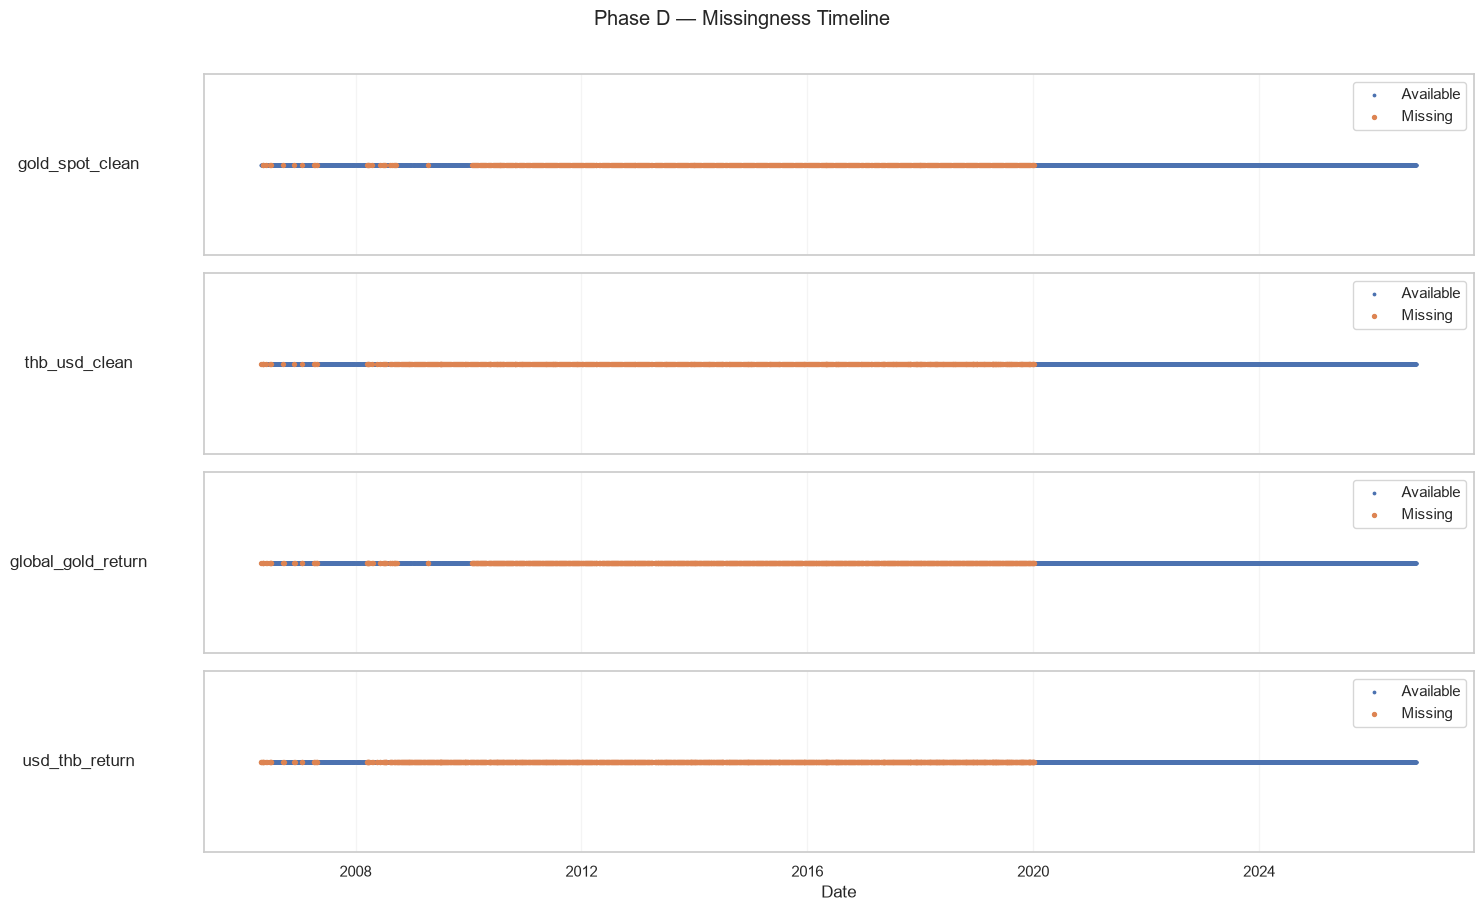

,gold_spot_clean,thb_usd_clean,global_gold_return,usd_thb_return
year,,,,
2006,3.48,4.48,6.97,8.46
2007,1.34,1.34,2.68,2.68
2008,4.70,10.74,9.06,21.14
2009,0.34,18.86,0.67,37.04
2010,16.39,19.06,32.11,36.12
2011,17.28,18.94,34.22,36.21
2012,17.17,18.18,33.67,35.35
2013,17.06,17.73,33.78,34.78
2014,17.00,18.33,34.33,36.33


In [89]:

# Phase D — Step 7: Visualize missingness over time

missing_cols = [
    "gold_spot_clean",
    "thb_usd_clean",
    "global_gold_return",
    "usd_thb_return",
]

fig, axes = plt.subplots(4, 1, figsize=(15, 9), sharex=True)

for ax, col in zip(axes, missing_cols):
    missing = df_phase_d_features[col].isna()

    ax.scatter(
        df_phase_d_features.loc[~missing, "date"],
        [0] * (~missing).sum(),
        s=3,
        label="Available",
    )
    ax.scatter(
        df_phase_d_features.loc[missing, "date"],
        [0] * missing.sum(),
        s=8,
        label="Missing",
    )

    ax.set_yticks([])
    ax.set_ylabel(col, rotation=0, labelpad=90, va="center")
    ax.legend(loc="upper right")
    ax.grid(True, axis="x", alpha=0.2)

axes[-1].set_xlabel("Date")
fig.suptitle("Phase D — Missingness Timeline", y=1.01)
plt.tight_layout()
plt.show()


# Summarize missing rates by year
df_missing_yearly = df_phase_d_features.copy()
df_missing_yearly["year"] = df_missing_yearly["date"].dt.year

yearly_missing_rate = (
    df_missing_yearly.groupby("year")[missing_cols]
    .apply(lambda x: x.isna().mean() * 100)
)

display(yearly_missing_rate.round(2))


In [90]:

# Phase D — Step 8: Identify consecutive missing periods

def get_missing_runs(data, column):
    missing = data[column].isna()
    groups = missing.ne(missing.shift()).cumsum()

    runs = (
        data.loc[missing]
        .assign(
            run_id=groups[missing].values
        )
        .groupby("run_id")
        .agg(
            start_date=("date", "min"),
            end_date=("date", "max"),
            missing_days=("date", "size"),
        )
        .sort_values("missing_days", ascending=False)
        .reset_index(drop=True)
    )

    return runs

for col in ["gold_spot_clean", "thb_usd_clean"]:
    runs = get_missing_runs(df_phase_d_features, col)

    print(f"\n{col}")
    print("Number of missing runs:", len(runs))

    display(runs.head(15))



gold_spot_clean
Number of missing runs: 531


,start_date,end_date,missing_days
0,2006-05-11,2006-05-13,2
1,2012-12-08,2012-12-10,2
2,2010-07-24,2010-07-26,2
3,2010-10-29,2010-10-30,2
4,2013-12-28,2013-12-30,2
5,2008-03-21,2008-03-22,2
6,2011-12-24,2011-12-26,2
7,2016-04-30,2016-05-01,2
8,2017-12-30,2018-01-01,2
9,2006-07-01,2006-07-01,1



thb_usd_clean
Number of missing runs: 633


,start_date,end_date,missing_days
0,2006-05-11,2006-05-15,3
1,2016-04-30,2016-05-02,3
2,2010-05-20,2010-05-22,3
3,2009-07-04,2009-07-07,3
4,2017-12-30,2018-01-02,3
5,2018-04-13,2018-04-16,3
6,2018-07-27,2018-07-30,3
7,2018-12-29,2019-01-01,3
8,2019-04-13,2019-04-16,3
9,2010-12-10,2010-12-11,2


In [91]:
# ตรวจสอบว่าราคาที่ daily row เป็น Missing
# แต่ intraday row อื่นของวันเดียวกันยังมีข้อมูลหรือไม่

df_intraday_check = df_market_eda.copy()

df_intraday_check["date"] = (
    df_intraday_check["timestamp_parsed"].dt.normalize()
)

daily_missing_dates = df_daily_d.loc[
    df_daily_d["gold_spot_clean"].isna()
    | df_daily_d["thb_usd_clean"].isna(),
    "date"
]

intraday_by_date = (
    df_intraday_check[
        df_intraday_check["date"].isin(daily_missing_dates)
    ]
    .groupby("date")
    .agg(
        intraday_rows=("timestamp_parsed", "size"),
        gold_spot_available=("gold_spot_clean", "count"),
        usd_thb_available=("thb_usd_clean", "count"),
        last_timestamp=("timestamp_parsed", "max"),
    )
    .reset_index()
)

daily_check = df_daily_d[
    ["date", "gold_spot_clean", "thb_usd_clean"]
].merge(
    intraday_by_date,
    on="date",
    how="left"
)

display(
    daily_check[
        daily_check["gold_spot_clean"].isna()
        | daily_check["thb_usd_clean"].isna()
    ].head(20)
)

print(
    "วันที่ daily row มี Missing แต่ intraday ยังมี Gold Spot:",
    (
        daily_check["gold_spot_clean"].isna()
        & (daily_check["gold_spot_available"] > 0)
    ).sum()
)

print(
    "วันที่ daily row มี Missing แต่ intraday ยังมี USD/THB:",
    (
        daily_check["thb_usd_clean"].isna()
        & (daily_check["usd_thb_available"] > 0)
    ).sum()
)


,date,gold_spot_clean,thb_usd_clean,intraday_rows,gold_spot_available,usd_thb_available,last_timestamp
1,2006-05-02,657.05,NaN,2.0,2.0,1.0,2006-05-02 11:50:00
8,2006-05-11,NaN,NaN,3.0,0.0,0.0,2006-05-11 11:50:00
9,2006-05-13,NaN,NaN,2.0,0.0,0.0,2006-05-13 10:30:00
10,2006-05-15,695.80,NaN,6.0,6.0,5.0,2006-05-15 16:30:00
27,2006-06-03,NaN,NaN,1.0,0.0,0.0,2006-06-03 09:30:00
43,2006-06-24,NaN,NaN,1.0,0.0,0.0,2006-06-24 09:15:00
49,2006-07-01,NaN,NaN,1.0,0.0,0.0,2006-07-01 09:30:00
116,2006-09-21,NaN,NaN,1.0,0.0,0.0,2006-09-21 09:30:00
177,2006-12-02,NaN,NaN,1.0,0.0,0.0,2006-12-02 09:30:00
216,2007-01-20,NaN,NaN,1.0,0.0,0.0,2007-01-20 09:30:00


วันที่ daily row มี Missing แต่ intraday ยังมี Gold Spot: 1
วันที่ daily row มี Missing แต่ intraday ยังมี USD/THB: 4


In [92]:
# สรุป Missing ของราคาใน daily dataset รายปี

df_missing_year = df_phase_d_features.copy()

df_missing_year["year"] = (
    df_missing_year["date"].dt.year
)

missing_by_year = (
    df_missing_year.groupby("year")
    .agg(
        total_days=("date", "size"),
        gold_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        fx_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
)

missing_by_year["gold_missing_pct"] = (
    missing_by_year["gold_missing"]
    / missing_by_year["total_days"] * 100
)

missing_by_year["fx_missing_pct"] = (
    missing_by_year["fx_missing"]
    / missing_by_year["total_days"] * 100
)

display(missing_by_year.round(2))

,total_days,gold_missing,fx_missing,gold_missing_pct,fx_missing_pct
year,,,,,
2006,201,7,9,3.48,4.48
2007,299,4,4,1.34,1.34
2008,298,14,32,4.70,10.74
2009,297,1,56,0.34,18.86
2010,299,49,57,16.39,19.06
2011,301,52,57,17.28,18.94
2012,297,51,54,17.17,18.18
2013,299,51,53,17.06,17.73
2014,300,51,55,17.00,18.33


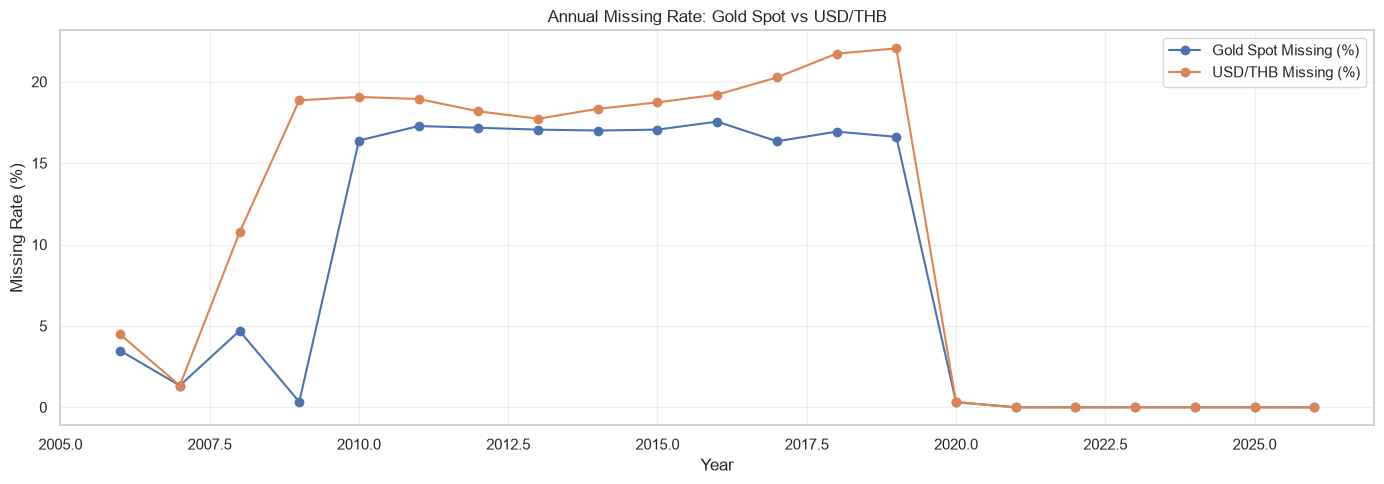

In [93]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    missing_by_year.index,
    missing_by_year["gold_missing_pct"],
    marker="o",
    label="Gold Spot Missing (%)"
)

ax.plot(
    missing_by_year.index,
    missing_by_year["fx_missing_pct"],
    marker="o",
    label="USD/THB Missing (%)"
)

ax.set_title("Annual Missing Rate: Gold Spot vs USD/THB")
ax.set_xlabel("Year")
ax.set_ylabel("Missing Rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [94]:
# Recalculate annual missing counts and rates directly

df_missing_year = df_phase_d_features.copy()
df_missing_year["year"] = df_missing_year["date"].dt.year

missing_by_year = (
    df_missing_year.groupby("year")
    .agg(
        total_days=("date", "size"),
        gold_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        fx_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
)

missing_by_year["gold_missing_pct"] = (
    100 * missing_by_year["gold_missing"]
    / missing_by_year["total_days"]
)

missing_by_year["fx_missing_pct"] = (
    100 * missing_by_year["fx_missing"]
    / missing_by_year["total_days"]
)

display(missing_by_year.round(2))

,total_days,gold_missing,fx_missing,gold_missing_pct,fx_missing_pct
year,,,,,
2006,201,7,9,3.48,4.48
2007,299,4,4,1.34,1.34
2008,298,14,32,4.70,10.74
2009,297,1,56,0.34,18.86
2010,299,49,57,16.39,19.06
2011,301,52,57,17.28,18.94
2012,297,51,54,17.17,18.18
2013,299,51,53,17.06,17.73
2014,300,51,55,17.00,18.33


In [95]:
print("Gold Spot total missing:",
      df_phase_d_features["gold_spot_clean"].isna().sum())

print("USD/THB total missing:",
      df_phase_d_features["thb_usd_clean"].isna().sum())

print("Daily rows:",
      len(df_phase_d_features))

Gold Spot total missing: 540
USD/THB total missing: 691
Daily rows: 6261


In [96]:
# Classify missing dates by day of week

df_calendar_check = df_phase_d_features.copy()

df_calendar_check["weekday"] = (
    df_calendar_check["date"].dt.day_name()
)

df_calendar_check["is_weekend"] = (
    df_calendar_check["date"].dt.dayofweek >= 5
)

weekday_missing = (
    df_calendar_check.groupby("weekday")
    .agg(
        total_days=("date", "size"),
        gold_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        fx_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
)

weekday_missing["gold_missing_pct"] = (
    weekday_missing["gold_missing"]
    / weekday_missing["total_days"] * 100
)

weekday_missing["fx_missing_pct"] = (
    weekday_missing["fx_missing"]
    / weekday_missing["total_days"] * 100
)

display(weekday_missing.round(2))

,total_days,gold_missing,fx_missing,gold_missing_pct,fx_missing_pct
weekday,,,,,
Friday,1037,2,15,0.19,1.45
Monday,1030,6,43,0.58,4.17
Saturday,1047,526,594,50.24,56.73
Sunday,17,3,3,17.65,17.65
Thursday,1045,2,10,0.19,0.96
Tuesday,1040,0,17,0.00,1.63
Wednesday,1045,1,9,0.10,0.86


In [97]:
weekend_summary = (
    df_calendar_check.groupby("is_weekend")
    .agg(
        total_days=("date", "size"),
        gold_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        fx_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
)

weekend_summary["gold_missing_pct"] = (
    weekend_summary["gold_missing"]
    / weekend_summary["total_days"] * 100
)

weekend_summary["fx_missing_pct"] = (
    weekend_summary["fx_missing"]
    / weekend_summary["total_days"] * 100
)

weekend_summary.index = weekend_summary.index.map({
    False: "Weekday",
    True: "Weekend",
})

display(weekend_summary.round(2))

,total_days,gold_missing,fx_missing,gold_missing_pct,fx_missing_pct
is_weekend,,,,,
Weekday,5197,11,94,0.21,1.81
Weekend,1064,529,597,49.72,56.11


In [98]:
import holidays

thai_holidays = holidays.country_holidays(
    "TH",
    years=range(
        df_calendar_check["date"].dt.year.min(),
        df_calendar_check["date"].dt.year.max() + 1
    )
)

df_calendar_check["is_thai_holiday"] = (
    df_calendar_check["date"]
    .dt.date
    .isin(thai_holidays)
)

df_calendar_check["thai_holiday_name"] = (
    df_calendar_check["date"]
    .dt.date
    .map(thai_holidays)
)

# Summarize missing rates by weekend and Thai holiday
df_calendar_check["calendar_type"] = "Weekday / Other"

df_calendar_check.loc[
    df_calendar_check["is_weekend"],
    "calendar_type"
] = "Weekend"

df_calendar_check.loc[
    df_calendar_check["is_thai_holiday"],
    "calendar_type"
] = "Thai holiday"

display(
    df_calendar_check.groupby("calendar_type")
    .agg(
        total_days=("date", "size"),
        gold_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        fx_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
)

,total_days,gold_missing,fx_missing
calendar_type,,,
Thai holiday,310,28,105
Weekday / Other,4937,5,13
Weekend,1014,507,573


In [99]:
# Create mutually exclusive calendar categories

df_calendar_check["calendar_type"] = "Ordinary weekday"

df_calendar_check.loc[
    df_calendar_check["is_weekend"],
    "calendar_type"
] = "Weekend"

df_calendar_check.loc[
    df_calendar_check["is_thai_holiday"]
    & ~df_calendar_check["is_weekend"],
    "calendar_type"
] = "Thai holiday on weekday"

df_calendar_check.loc[
    df_calendar_check["is_weekend"]
    & df_calendar_check["is_thai_holiday"],
    "calendar_type"
] = "Weekend + Thai holiday"

calendar_summary = (
    df_calendar_check.groupby("calendar_type")
    .agg(
        total_days=("date", "size"),
        gold_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        fx_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
)

calendar_summary["gold_missing_pct"] = (
    100 * calendar_summary["gold_missing"]
    / calendar_summary["total_days"]
)

calendar_summary["fx_missing_pct"] = (
    100 * calendar_summary["fx_missing"]
    / calendar_summary["total_days"]
)

display(calendar_summary.round(2))

,total_days,gold_missing,fx_missing,gold_missing_pct,fx_missing_pct
calendar_type,,,,,
Ordinary weekday,4937,5,13,0.10,0.26
Thai holiday on weekday,260,6,81,2.31,31.15
Weekend,1014,507,573,50.00,56.51
Weekend + Thai holiday,50,22,24,44.00,48.00


In [100]:
# Focus only on ordinary weekdays
df_weekday_missing = df_calendar_check[
    ~df_calendar_check["is_weekend"]
].copy()

df_weekday_missing["year"] = (
    df_weekday_missing["date"].dt.year
)

weekday_missing_by_year = (
    df_weekday_missing.groupby("year")
    .agg(
        weekday_count=("date", "size"),
        gold_missing=("gold_spot_clean", lambda s: s.isna().sum()),
        fx_missing=("thb_usd_clean", lambda s: s.isna().sum()),
    )
)

weekday_missing_by_year["gold_missing_pct"] = (
    100 * weekday_missing_by_year["gold_missing"]
    / weekday_missing_by_year["weekday_count"]
)

weekday_missing_by_year["fx_missing_pct"] = (
    100 * weekday_missing_by_year["fx_missing"]
    / weekday_missing_by_year["weekday_count"]
)

display(weekday_missing_by_year.round(2))

,weekday_count,gold_missing,fx_missing,gold_missing_pct,fx_missing_pct
year,,,,,
2006,167,2,4,1.20,2.40
2007,249,2,2,0.80,0.80
2008,246,1,3,0.41,1.22
2009,246,0,5,0.00,2.03
2010,250,2,8,0.80,3.20
2011,249,1,6,0.40,2.41
2012,247,1,4,0.40,1.62
2013,249,1,3,0.40,1.20
2014,249,0,4,0.00,1.61


In [101]:
# Dates where USD/THB is missing on weekdays

fx_weekday_missing = df_calendar_check[
    df_calendar_check["thb_usd_clean"].isna()
    & ~df_calendar_check["is_weekend"]
].copy()

fx_weekday_missing["year"] = (
    fx_weekday_missing["date"].dt.year
)

display(
    fx_weekday_missing[
        ["date", "year", "thai_holiday_name", "gold_spot_clean"]
    ].sort_values("date")
)

print("Total weekday FX missing:", len(fx_weekday_missing))

,date,year,thai_holiday_name,gold_spot_clean
1,2006-05-02,2006,NaN,657.05
8,2006-05-11,2006,วันวิสาขบูชา,NaN
10,2006-05-15,2006,NaN,695.80
116,2006-09-21,2006,NaN,NaN
285,2007-04-16,2007,ชดเชยวันสงกรานต์,NaN
...,...,...,...,...
4056,2019-10-14,2019,ชดเชยวันคล้ายวันสวรรคตพระบาทสมเด็จพระบรมชนกาธิ...,1495.00
4064,2019-10-23,2019,วันปิยมหาราช,1494.50
4101,2019-12-05,2019,วันคล้ายวันเฉลิมพระชนมพรรษาพระบาทสมเด็จพระบรมช...,1475.50
4105,2019-12-10,2019,วันรัฐธรรมนูญ,1465.00


Total weekday FX missing: 94


In [102]:
# Identify consecutive missing dates in the observed daily rows

fx_weekday_missing = fx_weekday_missing.sort_values("date").copy()

fx_weekday_missing["gap_from_previous_missing"] = (
    fx_weekday_missing["date"].diff().dt.days
)

display(
    fx_weekday_missing[
        ["date", "year", "thai_holiday_name",
         "gap_from_previous_missing"]
    ]
)

,date,year,thai_holiday_name,gap_from_previous_missing
1,2006-05-02,2006,NaN,NaN
8,2006-05-11,2006,วันวิสาขบูชา,9.0
10,2006-05-15,2006,NaN,4.0
116,2006-09-21,2006,NaN,129.0
285,2007-04-16,2007,ชดเชยวันสงกรานต์,207.0
...,...,...,...,...
4056,2019-10-14,2019,ชดเชยวันคล้ายวันสวรรคตพระบาทสมเด็จพระบรมชนกาธิ...,63.0
4064,2019-10-23,2019,วันปิยมหาราช,9.0
4101,2019-12-05,2019,วันคล้ายวันเฉลิมพระชนมพรรษาพระบาทสมเด็จพระบรมช...,43.0
4105,2019-12-10,2019,วันรัฐธรรมนูญ,5.0


In [103]:
# Rebuild FX weekday missing dataset

fx_weekday_missing = df_calendar_check[
    df_calendar_check["thb_usd_clean"].isna()
    & ~df_calendar_check["is_weekend"]
].copy()

# Add year column
fx_weekday_missing["year"] = (
    fx_weekday_missing["date"].dt.year
)

# Classify Thai holidays
fx_weekday_missing["holiday_status"] = (
    fx_weekday_missing["thai_holiday_name"]
    .notna()
    .map({
        True: "Thai holiday",
        False: "Not listed as Thai holiday"
    })
)

# Summarize by year and holiday status
fx_missing_summary = (
    fx_weekday_missing
    .groupby(["year", "holiday_status"])
    .size()
    .unstack(fill_value=0)
)

display(fx_missing_summary)

holiday_status,Not listed as Thai holiday,Thai holiday
year,,
2006,3,1
2007,1,1
2008,1,2
2009,1,4
2010,2,6
2011,1,5
2012,0,4
2013,1,2
2014,1,3


In [104]:
print("FX weekday missing rows:", len(fx_weekday_missing))

print(
    fx_weekday_missing["holiday_status"]
    .value_counts(dropna=False)
)

print(
    fx_weekday_missing.groupby("year")
    .size()
    .sum()
)

FX weekday missing rows: 94
holiday_status
Thai holiday                  81
Not listed as Thai holiday    13
Name: count, dtype: int64
94


In [105]:
fx_not_listed_holiday = fx_weekday_missing[
    fx_weekday_missing["thai_holiday_name"].isna()
].copy()

cols_to_check = [
    "date",
    "weekday",
    "thai_holiday_name",
    "bar_buy",
    "gold_spot_clean",
    "thb_usd_clean",
]

display(
    fx_not_listed_holiday[cols_to_check]
    .sort_values("date")
    .reset_index(drop=True)
)

print("Not listed as Thai holiday:", len(fx_not_listed_holiday))

,date,weekday,thai_holiday_name,bar_buy,gold_spot_clean,thb_usd_clean
0,2006-05-02,Tuesday,NaN,11550.0,657.05,NaN
1,2006-05-15,Monday,NaN,12550.0,695.80,NaN
2,2006-09-21,Thursday,NaN,10250.0,NaN,NaN
3,2007-04-25,Wednesday,NaN,11200.0,NaN,NaN
4,2008-03-21,Friday,NaN,13800.0,NaN,NaN
5,2009-07-01,Wednesday,NaN,15000.0,929.90,NaN
6,2010-07-01,Thursday,NaN,18950.0,1240.00,NaN
7,2010-10-29,Friday,NaN,18900.0,NaN,NaN
8,2011-07-01,Friday,NaN,21750.0,1490.50,NaN
9,2013-07-01,Monday,NaN,18200.0,1240.00,NaN


Not listed as Thai holiday: 13


In [106]:
# ตรวจรูปแบบ Missing ของตัวแปรทั้งสาม
missing_pattern = (
    fx_not_listed_holiday[
        ["bar_buy", "gold_spot_clean", "thb_usd_clean"]
    ]
    .isna()
    .value_counts()
    .rename("days")
    .reset_index()
)

display(missing_pattern)

,bar_buy,gold_spot_clean,thb_usd_clean,days
0,False,False,True,9
1,False,True,True,4


In [107]:
# ตรวจวันธรรมดาทั้งหมด ไม่จำกัดเฉพาะ FX Missing
weekday_data = df_calendar_check[
    ~df_calendar_check["is_weekend"]
].copy()

weekday_data["missing_pattern"] = (
    weekday_data[["bar_buy", "gold_spot_clean", "thb_usd_clean"]]
    .isna()
    .astype(int)
    .astype(str)
    .agg("".join, axis=1)
)

display(
    weekday_data["missing_pattern"]
    .value_counts()
    .rename_axis("bar_gold_fx_missing_pattern")
    .reset_index(name="days")
)

,bar_gold_fx_missing_pattern,days
0,000,5102
1,001,84
2,011,10
3,010,1


In [108]:
# วันที่ Gold Spot และ FX หายพร้อมกันในวันธรรมดา
gold_fx_both_missing = weekday_data[
    weekday_data["gold_spot_clean"].isna()
    & weekday_data["thb_usd_clean"].isna()
].copy()

display(
    gold_fx_both_missing[
        ["date", "weekday", "thai_holiday_name", "bar_buy"]
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

print("Gold Spot + FX missing:", len(gold_fx_both_missing))

,date,weekday,thai_holiday_name,bar_buy
0,2006-05-11,Thursday,วันวิสาขบูชา,12650.0
1,2006-09-21,Thursday,NaN,10250.0
2,2007-04-16,Monday,ชดเชยวันสงกรานต์,11200.0
3,2007-04-25,Wednesday,NaN,11200.0
4,2008-03-21,Friday,NaN,13800.0
5,2010-07-26,Monday,วันอาสาฬหบูชา,18200.0
6,2010-10-29,Friday,NaN,18900.0
7,2012-12-10,Monday,วันรัฐธรรมนูญ,24700.0
8,2013-12-30,Monday,วันหยุดพิเศษ (เพิ่มเติม),18700.0
9,2018-01-01,Monday,วันขึ้นปีใหม่,20000.0


Gold Spot + FX missing: 10


In [109]:
# ตรวจวันก่อนหน้าและวันถัดไปของวันที่ Gold Spot + FX หายพร้อมกัน
dates_to_check = gold_fx_both_missing["date"]

nearby_dates = df_phase_d_features[
    df_phase_d_features["date"].isin(
        pd.concat([
            dates_to_check - pd.Timedelta(days=1),
            dates_to_check,
            dates_to_check + pd.Timedelta(days=1),
        ]).unique()
    )
].copy()

display(
    nearby_dates[
        [
            "date",
            "bar_buy",
            "gold_spot_clean",
            "thb_usd_clean",
            "thai_gold_return",
            "global_gold_return",
            "usd_thb_return",
        ]
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

,date,bar_buy,gold_spot_clean,thb_usd_clean,thai_gold_return,global_gold_return,usd_thb_return
0,2006-05-10,12400.0,703.70,37.70,0.024491,0.031029,-0.000265
1,2006-05-11,12650.0,NaN,NaN,0.019961,NaN,NaN
2,2006-09-21,10250.0,NaN,NaN,-0.004866,NaN,NaN
3,2006-09-22,10350.0,586.75,37.55,0.009709,NaN,NaN
4,2007-04-16,11200.0,NaN,NaN,0.008969,NaN,NaN
5,2007-04-17,11250.0,687.60,34.89,0.004454,NaN,NaN
6,2007-04-24,11250.0,688.00,34.85,0.000000,-0.003627,0.000287
7,2007-04-25,11200.0,NaN,NaN,-0.004454,NaN,NaN
8,2007-04-26,11200.0,686.00,34.82,0.000000,NaN,NaN
9,2008-03-20,13900.0,924.00,31.38,-0.055959,-0.074332,0.005432


1\. การเติมค่าอาจบิดเบือนสถิติทางการเงิน เช่น Forward Fill ทำให้ราคาซ้ำและอาจสร้าง Return เป็นศูนย์เทียม ส่งผลต่อ Volatility และ Correlation ควรเก็บ Missing ไว้จนกว่าจะมีเหตุผลรองรับวิธีจัดการ อ้างอิง: Missing Observations in Observation-Driven Time Series Models, Journal of Econometrics (2021). ScienceDirect

2\. ข้อมูลที่หายไม่ได้เป็นแบบสุ่มเสมอไป การลบแถวหรือวิเคราะห์เฉพาะข้อมูลครบอาจทำให้ผลลัพธ์มี Bias หากรูปแบบ Missing สัมพันธ์กับข้อมูลที่ไม่ได้สังเกต อ้างอิง: Chassan & Concordet, How to Test the Missing Data Mechanism in a Hidden Markov Model (2023). ScienceDirect

3\. แต่ละ Quant Function ต้องจัดการ Missing ต่างกัน Correlation ใช้ข้อมูลที่จับคู่กันได้ ส่วน HMM และโมเดล Volatility ต้องคำนึงถึงโครงสร้างลำดับเวลา ไม่ควรลบแถวแล้วนำข้อมูลมาต่อกันโดยไม่ตรวจสอบ อ้างอิง: Missing Observations in Observation-Driven Time Series Models (2021) และ Chassan & Concordet (2023). ScienceDirect

4\. ป้องกัน LLM อธิบายสาเหตุการขาดทุนจากหลักฐานที่ไม่ครบ คง Missing ไว้และส่งสถานะข้อมูล จำนวนตัวอย่าง และข้อจำกัดจาก Quant Engine ให้ LLM ผ่าน Function Calling เพื่อไม่ให้ระบบสร้างข้อสรุปเกี่ยวกับตลาดที่ข้อมูลไม่รองรับ ข้อนี้เป็นข้อเสนอด้านการออกแบบระบบของเรา โดยต่อยอดจากหลักการจัดการ Missing ในงานวิจัยข้างต้น

### หาความสัมพันธ์ต่อ

In [110]:
df_cross_market = (
    df_phase_d_features
    .sort_values("date")
    .copy()
)

market_pairs = [
    ("thai_gold_return", "global_gold_return", "Thai Gold vs Gold Spot"),
    ("thai_gold_return", "usd_thb_return", "Thai Gold vs USD/THB"),
    ("global_gold_return", "usd_thb_return", "Gold Spot vs USD/THB"),
]

results = []

for col_x, col_y, pair_name in market_pairs:
    pair_data = df_cross_market[[col_x, col_y]].dropna()

    n = len(pair_data)

    if n < 3:
        continue

    pearson_r, pearson_p = pearsonr(
        pair_data[col_x],
        pair_data[col_y]
    )

    spearman_r, spearman_p = spearmanr(
        pair_data[col_x],
        pair_data[col_y]
    )

    results.append({
        "market_pair": pair_name,
        "n_observations": n,
        "pearson_r": pearson_r,
        "pearson_p_value": pearson_p,
        "spearman_rho": spearman_r,
        "spearman_p_value": spearman_p,
    })

df_cross_market_corr = pd.DataFrame(results)

display(
    df_cross_market_corr
)

,market_pair,n_observations,pearson_r,pearson_p_value,spearman_rho,spearman_p_value
0,Thai Gold vs Gold Spot,5189,0.924859,0.000000e+00,0.894837,0.000000e+00
1,Thai Gold vs USD/THB,4936,-0.158214,4.922203e-29,-0.179095,7.434545e-37
2,Gold Spot vs USD/THB,4935,-0.451943,4.591748e-247,-0.512119,0.000000e+00


In [111]:



# เรียงข้อมูลตามเวลา โดยไม่เติม Missing
df_cross_market = (
    df_phase_d_features
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

market_pairs = [
    ("thai_gold_return", "global_gold_return", "thai_gold_vs_global"),
    ("thai_gold_return", "usd_thb_return", "thai_gold_vs_fx"),
    ("global_gold_return", "usd_thb_return", "global_gold_vs_fx"),
]

window = 60
min_valid = 30

rolling_results = []

for col_x, col_y, pair_name in market_pairs:
    pair_data = df_cross_market[
        ["date", col_x, col_y]
    ]

    for end_idx in range(window - 1, len(pair_data)):
        window_data = pair_data.iloc[
            end_idx - window + 1 : end_idx + 1
        ]

        valid = window_data[[col_x, col_y]].dropna()
        n_valid = len(valid)

        result = {
            "date": window_data["date"].iloc[-1],
            "market_pair": pair_name,
            "n_valid": n_valid,
            "pearson_r": np.nan,
            "spearman_rho": np.nan,
        }

        # ต้องมีข้อมูลเพียงพอ และตัวแปรทั้งคู่ต้องมีความแปรผัน
        if (
            n_valid >= min_valid
            and valid[col_x].nunique() > 1
            and valid[col_y].nunique() > 1
        ):
            result["pearson_r"] = valid[col_x].corr(
                valid[col_y], method="pearson"
            )

            result["spearman_rho"] = valid[col_x].corr(
                valid[col_y], method="spearman"
            )

        rolling_results.append(result)

df_rolling_corr = pd.DataFrame(rolling_results)

print("Rows:", len(df_rolling_corr))
print("Unique dates:", df_rolling_corr["date"].nunique())

display(df_rolling_corr.head())


Rows: 18606
Unique dates: 6202


,date,market_pair,n_valid,pearson_r,spearman_rho
0,2006-07-14,thai_gold_vs_global,50,0.949748,0.931744
1,2006-07-15,thai_gold_vs_global,51,0.949570,0.934420
2,2006-07-17,thai_gold_vs_global,51,0.948482,0.934058
3,2006-07-18,thai_gold_vs_global,51,0.950593,0.935962
4,2006-07-19,thai_gold_vs_global,51,0.955476,0.943749


In [112]:

rolling_summary = (
    df_rolling_corr
    .groupby("market_pair")
    .agg(
        total_windows=("date", "size"),
        valid_pearson=("pearson_r", "count"),
        valid_spearman=("spearman_rho", "count"),
        min_n_valid=("n_valid", "min"),
        median_n_valid=("n_valid", "median"),
        max_n_valid=("n_valid", "max"),
        mean_pearson=("pearson_r", "mean"),
        median_pearson=("pearson_r", "median"),
        mean_spearman=("spearman_rho", "mean"),
        median_spearman=("spearman_rho", "median"),
    )
    .reset_index()
)

display(rolling_summary.round(4))


,market_pair,total_windows,valid_pearson,valid_spearman,min_n_valid,median_n_valid,max_n_valid,mean_pearson,median_pearson,mean_spearman,median_spearman
0,global_gold_vs_fx,6202,6202,6202,32,40.0,60,-0.4934,-0.5163,-0.5055,-0.5303
1,thai_gold_vs_fx,6202,6202,6202,32,40.0,60,-0.1698,-0.1707,-0.1849,-0.1760
2,thai_gold_vs_global,6202,6202,6202,37,51.0,60,0.8981,0.9388,0.8699,0.9144


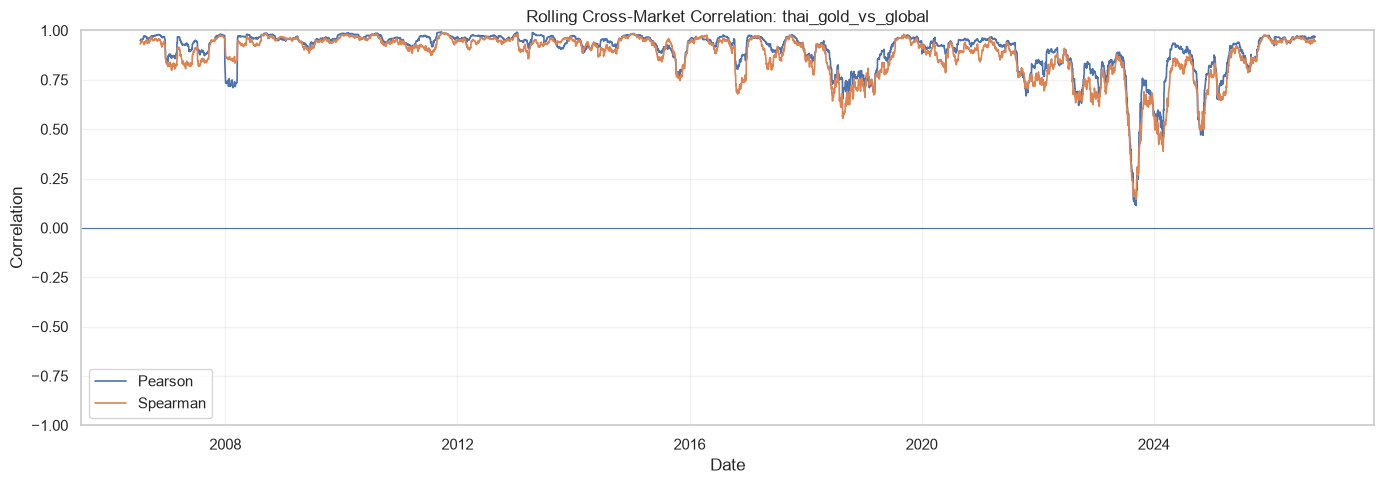

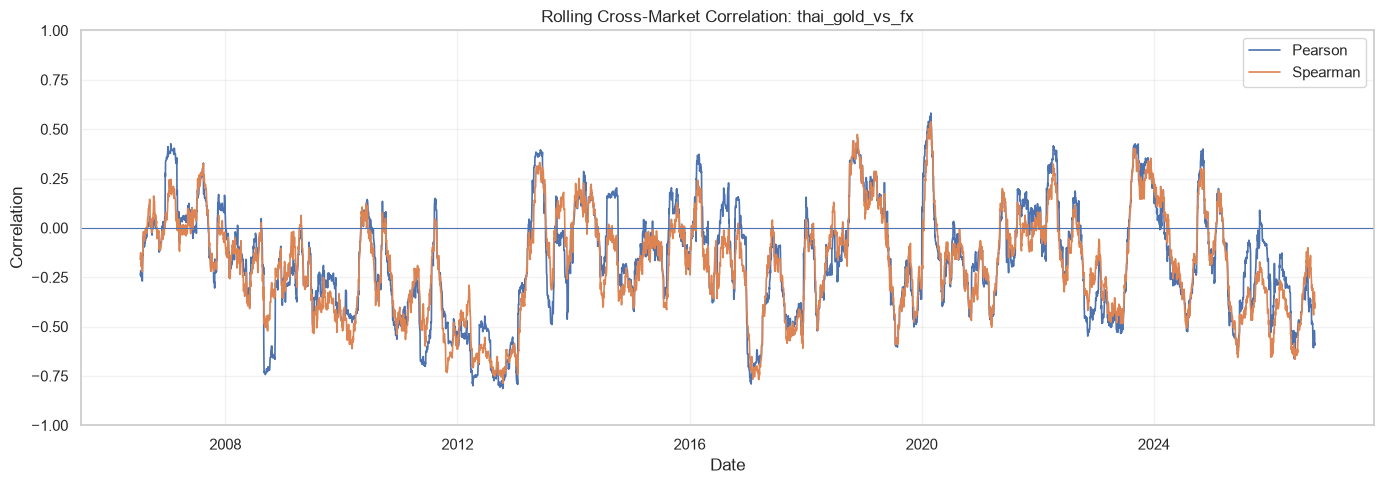

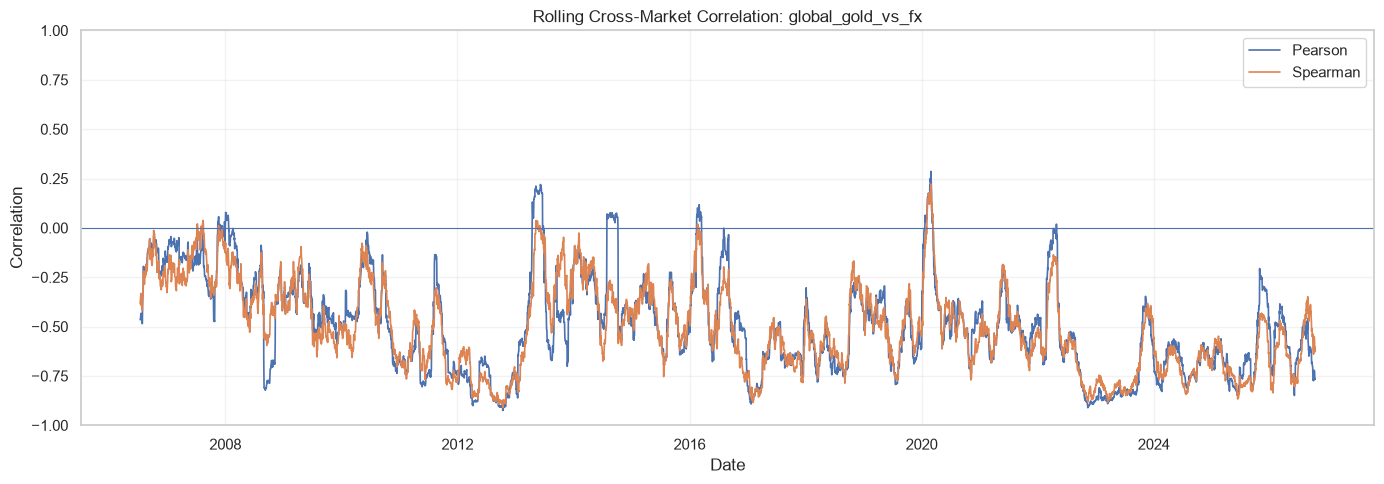

In [113]:


for pair_name in df_rolling_corr["market_pair"].unique():
    plot_data = (
        df_rolling_corr[
            df_rolling_corr["market_pair"] == pair_name
        ]
        .sort_values("date")
    )

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        plot_data["date"],
        plot_data["pearson_r"],
        label="Pearson",
        linewidth=1.2,
    )

    ax.plot(
        plot_data["date"],
        plot_data["spearman_rho"],
        label="Spearman",
        linewidth=1.2,
    )

    ax.axhline(0, linewidth=0.8)
    ax.set_title(f"Rolling Cross-Market Correlation: {pair_name}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Correlation")
    ax.set_ylim(-1, 1)
    ax.legend()
    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()


In [114]:

# หา 10 หน้าต่างที่ Pearson สูงสุดและต่ำสุดของแต่ละคู่

for pair_name in df_rolling_corr["market_pair"].unique():
    subset = df_rolling_corr[
        df_rolling_corr["market_pair"] == pair_name
    ].dropna(subset=["pearson_r"])

    print(f"\n{'=' * 70}")
    print(pair_name)

    print("\nLowest Pearson:")
    display(
        subset.nsmallest(10, "pearson_r")[
            ["date", "n_valid", "pearson_r", "spearman_rho"]
        ]
    )

    print("\nHighest Pearson:")
    display(
        subset.nlargest(10, "pearson_r")[
            ["date", "n_valid", "pearson_r", "spearman_rho"]
        ]
    )



thai_gold_vs_global

Lowest Pearson:


,date,n_valid,pearson_r,spearman_rho
5221,2023-09-11,60,0.112742,0.144741
5216,2023-09-05,60,0.117908,0.166846
5220,2023-09-09,60,0.126349,0.167652
5215,2023-09-04,60,0.126732,0.168900
5214,2023-09-02,60,0.127672,0.171310
5217,2023-09-06,60,0.132075,0.172794
5209,2023-08-28,60,0.133923,0.158538
5213,2023-09-01,60,0.135211,0.184865
5211,2023-08-30,60,0.135436,0.177936
5218,2023-09-07,60,0.140015,0.177392



Highest Pearson:


,date,n_valid,pearson_r,spearman_rho
1549,2011-09-21,40,0.992462,0.985551
1548,2011-09-20,40,0.992153,0.982924
1546,2011-09-17,39,0.992105,0.981575
1547,2011-09-19,39,0.992105,0.981575
1545,2011-09-16,40,0.991558,0.976543
1939,2013-01-09,38,0.990991,0.979777
1940,2013-01-10,39,0.990926,0.980079
1543,2011-09-14,40,0.990884,0.974667
1544,2011-09-15,40,0.990873,0.974667
1542,2011-09-13,40,0.990865,0.974667



thai_gold_vs_fx

Lowest Pearson:


,date,n_valid,pearson_r,spearman_rho
8069,2012-10-12,40,-0.814314,-0.787346
8054,2012-09-25,39,-0.807369,-0.730403
8070,2012-10-13,39,-0.807355,-0.774549
8071,2012-10-15,39,-0.807355,-0.774549
8053,2012-09-24,38,-0.807355,-0.731085
8055,2012-09-26,40,-0.805478,-0.734529
8059,2012-10-01,38,-0.801820,-0.755520
8056,2012-09-27,40,-0.801338,-0.726488
7916,2012-04-07,39,-0.800071,-0.708764
8060,2012-10-02,39,-0.799077,-0.745707


... (2 outputs left out)


global_gold_vs_fx

Lowest Pearson:


,date,n_valid,pearson_r,spearman_rho
14271,2012-10-12,40,-0.924741,-0.910737
14272,2012-10-13,39,-0.923262,-0.905714
14273,2012-10-15,39,-0.923262,-0.905714
17365,2022-11-11,60,-0.910689,-0.881729
17366,2022-11-12,60,-0.910476,-0.879006
14277,2012-10-19,40,-0.909078,-0.888409
14255,2012-09-24,38,-0.908294,-0.881387
14256,2012-09-25,39,-0.907979,-0.878947
14278,2012-10-20,39,-0.907729,-0.889114
14279,2012-10-22,39,-0.907729,-0.889114



Highest Pearson:


,date,n_valid,pearson_r,spearman_rho
16519,2020-02-28,52,0.286166,0.222156
16520,2020-02-29,53,0.267958,0.203678
16515,2020-02-24,52,0.250425,0.183480
16516,2020-02-25,52,0.246153,0.174637
16518,2020-02-27,52,0.240777,0.177414
16517,2020-02-26,52,0.233702,0.151056
14462,2013-06-06,42,0.219733,-0.000324
14463,2013-06-07,42,0.216581,-0.007779
14464,2013-06-08,41,0.215331,-0.005836
14465,2013-06-10,41,0.215331,-0.005836


แต่ทำไม correlation ถึงตก

In [115]:



pair_name = "thai_gold_vs_global"

extreme_windows = (
    df_rolling_corr[
        df_rolling_corr["market_pair"] == pair_name
    ]
    .dropna(subset=["pearson_r"])
)

lowest = extreme_windows.loc[extreme_windows["pearson_r"].idxmin()]
highest = extreme_windows.loc[extreme_windows["pearson_r"].idxmax()]

print("Lowest correlation window:")
display(lowest.to_frame("value"))

print("Highest correlation window:")
display(highest.to_frame("value"))

# แสดงผลตอบแทนใน 60 แถวที่สิ้นสุด ณ วันที่ของแต่ละหน้าต่าง
def inspect_window(end_date):
    end_date = pd.Timestamp(end_date)

    end_positions = np.flatnonzero(
        df_cross_market["date"].eq(end_date).to_numpy()
    )

    if len(end_positions) == 0:
        print(f"Date not found: {end_date}")
        return

    end_idx = end_positions[-1]
    start_idx = max(0, end_idx - 59)

    cols = [
        "date",
        "bar_buy",
        "gold_spot_clean",
        "thb_usd_clean",
        "thai_gold_return",
        "global_gold_return",
        "usd_thb_return",
    ]

    available_cols = [
        col for col in cols
        if col in df_cross_market.columns
    ]

    window_data = df_cross_market.iloc[
        start_idx : end_idx + 1
    ][available_cols].copy()

    print(
        f"Window: {window_data['date'].min()} "
        f"to {window_data['date'].max()}"
    )
    print("Rows:", len(window_data))

    display(window_data.tail(15))

    print("\nDescriptive statistics:")
    display(
        window_data[
            ["thai_gold_return", "global_gold_return"]
        ].describe().T
    )

inspect_window(lowest["date"])
inspect_window(highest["date"])


Lowest correlation window:


,value
date,2023-09-11 00:00:00
market_pair,thai_gold_vs_global
n_valid,60
pearson_r,0.112742
spearman_rho,0.144741


Highest correlation window:


,value
date,2011-09-21 00:00:00
market_pair,thai_gold_vs_global
n_valid,40
pearson_r,0.992462
spearman_rho,0.985551


Window: 2023-07-04 00:00:00 to 2023-09-11 00:00:00
Rows: 60


,date,bar_buy,gold_spot_clean,thb_usd_clean,thai_gold_return,global_gold_return,usd_thb_return
5266,2023-08-25,31700.0,1917.0,35.07,0.001579,-0.002605,0.003714
5267,2023-08-26,31750.0,1914.5,35.14,0.001576,-0.001305,0.001994
5268,2023-08-28,31800.0,1914.0,35.25,0.001574,-0.000261,0.003125
5269,2023-08-29,31900.0,1921.5,35.22,0.003140,0.003911,-0.000851
5270,2023-08-30,32000.0,1937.0,35.08,0.003130,0.008034,-0.003983
5271,2023-08-31,32050.0,1946.0,34.93,0.001561,0.004636,-0.004285
5272,2023-09-01,32100.0,1943.5,35.04,0.001559,-0.001286,0.003144
5273,2023-09-02,32100.0,1940.0,35.11,0.000000,-0.001802,0.001996
5274,2023-09-04,32250.0,1943.5,35.22,0.004662,0.001802,0.003128
5275,2023-09-05,32300.0,1936.5,35.41,0.001549,-0.003608,0.005380


... (2 outputs left out)

Window: 2011-07-13 00:00:00 to 2011-09-21 00:00:00
Rows: 60


,date,bar_buy,gold_spot_clean,thb_usd_clean,thai_gold_return,global_gold_return,usd_thb_return
1594,2011-09-05,26700.0,1896.0,29.90,0.007519,NaN,NaN
1595,2011-09-06,26750.0,1897.0,29.92,0.001871,0.000527,0.000669
1596,2011-09-07,26200.0,1848.0,30.00,-0.020775,-0.026170,0.002670
1597,2011-09-08,26050.0,1834.0,30.05,-0.005742,-0.007605,0.001665
1598,2011-09-09,26150.0,1843.0,30.06,0.003831,0.004895,0.000333
1599,2011-09-10,26350.0,NaN,NaN,0.007619,NaN,NaN
1600,2011-09-12,26300.0,1845.0,30.16,-0.001899,NaN,NaN
1601,2011-09-13,25950.0,1814.0,30.21,-0.013397,-0.016945,0.001656
1602,2011-09-14,26200.0,1832.0,30.28,0.009588,0.009874,0.002314
1603,2011-09-15,26000.0,1812.0,30.32,-0.007663,-0.010977,0.001320



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
thai_gold_return,60.0,0.002671,0.016402,-0.071317,-0.004773,0.003900,0.008884,0.042217
global_gold_return,40.0,0.001666,0.020557,-0.078737,-0.007662,0.002958,0.010302,0.045748


Rolling Correlation ต่ำสุดในปี 2023 อาจเกี่ยวข้องกับการเคลื่อนไหวของราคาทองไทยที่มีค่าซ้ำกันหลายวัน ขณะที่ Gold Spot เปลี่ยนแปลงต่อเนื่อง

In [116]:

low_date = pd.Timestamp("2023-09-11")
window = 60

end_idx = df_cross_market.index[
    df_cross_market["date"].eq(low_date)
][-1]

window_data = df_cross_market.loc[
    max(0, end_idx - window + 1):end_idx,
    ["date", "thai_gold_return", "global_gold_return"]
].copy()

valid = window_data.dropna(
    subset=["thai_gold_return", "global_gold_return"]
)

print("Window rows:", len(window_data))
print("Complete return pairs:", len(valid))

for col in ["thai_gold_return", "global_gold_return"]:
    s = valid[col]

    print(f"\n{col}")
    print("Zero returns:", int(s.eq(0).sum()))
    print("Zero return rate:", round(s.eq(0).mean(), 4))
    print("Unique values:", s.nunique())

print("\nCorrelation on all complete pairs:")
print("Pearson:", valid["thai_gold_return"].corr(
    valid["global_gold_return"], method="pearson"
))
print("Spearman:", valid["thai_gold_return"].corr(
    valid["global_gold_return"], method="spearman"
))

# Diagnostic only: both returns nonzero
# ไม่ใช่ผลหลัก เพราะเป็นการเลือกข้อมูลตามค่าผลตอบแทน
nonzero = valid[
    valid["thai_gold_return"].ne(0)
    & valid["global_gold_return"].ne(0)
]

print("\nDiagnostic subset: both returns nonzero")
print("Pairs:", len(nonzero))

if len(nonzero) >= 3:
    print("Pearson:", nonzero["thai_gold_return"].corr(
        nonzero["global_gold_return"], method="pearson"
    ))
    print("Spearman:", nonzero["thai_gold_return"].corr(
        nonzero["global_gold_return"], method="spearman"
    ))


Window rows: 60
Complete return pairs: 60

thai_gold_return
Zero returns: 14
Zero return rate: 0.2333
Unique values: 33

global_gold_return
Zero returns: 0
Zero return rate: 0.0
Unique values: 59

Correlation on all complete pairs:
Pearson: 0.11274189244122082
Spearman: 0.14474097844097206

Diagnostic subset: both returns nonzero
Pairs: 46
Pearson: 0.11069881462421019
Spearman: 0.10329079663515466


In [117]:
diagnostic = valid.copy()

diagnostic["abs_thai_return"] = (
    diagnostic["thai_gold_return"].abs()
)
diagnostic["abs_global_return"] = (
    diagnostic["global_gold_return"].abs()
)

diagnostic["return_difference"] = (
    diagnostic["thai_gold_return"]
    - diagnostic["global_gold_return"]
)

print("Largest absolute Thai Gold returns:")
display(
    diagnostic.nlargest(10, "abs_thai_return")[
        [
            "thai_gold_return",
            "global_gold_return",
            "return_difference",
        ]
    ]
)

print("Largest absolute Gold Spot returns:")
display(
    diagnostic.nlargest(10, "abs_global_return")[
        [
            "thai_gold_return",
            "global_gold_return",
            "return_difference",
        ]
    ]
)

print("Largest absolute return differences:")
display(
    diagnostic.assign(
        abs_difference=diagnostic["return_difference"].abs()
    ).nlargest(10, "abs_difference")[
        [
            "thai_gold_return",
            "global_gold_return",
            "return_difference",
            "abs_difference",
        ]
    ]
)


Largest absolute Thai Gold returns:


,thai_gold_return,global_gold_return,return_difference
5233,-0.007843,0.002043,-0.009886
5262,-0.004751,-0.000794,-0.003957
5265,0.004751,0.009409,-0.004659
5274,0.004662,0.001802,0.002860
5260,-0.003155,-0.001319,-0.001835
5243,-0.003150,0.004090,-0.007240
5236,0.003140,-0.011406,0.014545
5251,0.003140,-0.001291,0.004431
5269,0.003140,0.003911,-0.000771
5252,-0.003140,-0.002328,-0.000811


Largest absolute Gold Spot returns:


,thai_gold_return,global_gold_return,return_difference
5242,-0.001571,-0.013990,0.012419
5236,0.003140,-0.011406,0.014545
5229,0.001566,0.011030,-0.009464
5234,0.001574,0.010405,-0.008831
5265,0.004751,0.009409,-0.004659
5221,-0.001571,0.008584,-0.010155
5270,0.003130,0.008034,-0.004904
5241,-0.001569,0.007861,-0.009430
5247,0.001581,-0.006436,0.008017
5227,-0.003135,0.006218,-0.009352


Largest absolute return differences:


,thai_gold_return,global_gold_return,return_difference,abs_difference
5236,0.003140,-0.011406,0.014545,0.014545
5242,-0.001571,-0.013990,0.012419,0.012419
5221,-0.001571,0.008584,-0.010155,0.010155
5233,-0.007843,0.002043,-0.009886,0.009886
5229,0.001566,0.011030,-0.009464,0.009464
5241,-0.001569,0.007861,-0.009430,0.009430
5227,-0.003135,0.006218,-0.009352,0.009352
5234,0.001574,0.010405,-0.008831,0.008831
5247,0.001581,-0.006436,0.008017,0.008017
5263,-0.001589,0.006071,-0.007660,0.007660


In [118]:

outlier_idx = [5233, 5262, 5265, 5274, 5260,
               5243, 5236, 5251, 5269, 5252,
               5242, 5229, 5234, 5221, 5241,
               5227, 5247, 5263]

# ตรวจสอบว่าดัชนีนี้ตรงกับ DataFrame ที่ใช้สร้างผลลัพธ์จริง
cols = [
    "date",
    "bar_buy",
    "gold_spot_clean",
    "thb_usd_clean",
    "thai_gold_return",
    "global_gold_return",
    "usd_thb_return",
    "thai_minus_global_return"
]

available_cols = [c for c in cols if c in df_cross_market.columns]

df_outlier_check = (
    df_cross_market
    .loc[df_cross_market.index.intersection(outlier_idx), available_cols]
    .sort_index()
    .copy()
)

display(df_outlier_check)

,date,bar_buy,gold_spot_clean,thb_usd_clean,thai_gold_return,global_gold_return,usd_thb_return,thai_minus_global_return
5221,2023-07-04,31800.0,1930.5,34.89,-0.001571,0.008584,-0.009982,-0.010155
5227,2023-07-11,31850.0,1936.0,34.85,-0.003135,0.006218,-0.009993,-0.009352
5229,2023-07-13,31950.0,1960.0,34.56,0.001566,0.011030,-0.009790,-0.009464
5233,2023-07-18,31750.0,1960.0,34.25,-0.007843,0.002043,-0.012188,-0.009886
5234,2023-07-19,31800.0,1980.5,34.00,0.001574,0.010405,-0.007326,-0.008831
5236,2023-07-21,31900.0,1961.5,34.48,0.003140,-0.011406,0.015491,0.014545
5241,2023-07-27,31850.0,1979.5,34.07,-0.001569,0.007861,-0.009930,-0.009430
5242,2023-07-28,31800.0,1952.0,34.53,-0.001571,-0.013990,0.013411,0.012419
5243,2023-07-29,31700.0,1960.0,34.27,-0.003150,0.004090,-0.007558,-0.007240
5247,2023-08-03,31650.0,1936.0,34.62,0.001581,-0.006436,0.008121,0.008017


In [119]:


df_check = (
    df_cross_market
    .sort_values("date")
    .copy()
)

# คำนวณใหม่จากราคาเดิม โดยไม่เติม missing values
df_check["thai_return_recalc"] = np.log(
    df_check["bar_buy"] / df_check["bar_buy"].shift(1)
)

df_check["global_return_recalc"] = np.log(
    df_check["gold_spot_clean"] /
    df_check["gold_spot_clean"].shift(1)
)

df_check["fx_return_recalc"] = np.log(
    df_check["thb_usd_clean"] /
    df_check["thb_usd_clean"].shift(1)
)

# ตรวจเฉพาะแถว outlier ที่สนใจ
outlier_dates = pd.to_datetime([
    "2023-07-04", "2023-07-11", "2023-07-13",
    "2023-07-18", "2023-07-19", "2023-07-21",
    "2023-07-27", "2023-07-28", "2023-07-29",
    "2023-08-03", "2023-08-08", "2023-08-09",
    "2023-08-18", "2023-08-21", "2023-08-22",
    "2023-08-24", "2023-08-29", "2023-09-04"
])

check_cols = [
    "date",
    "bar_buy", "gold_spot_clean", "thb_usd_clean",
    "thai_gold_return", "thai_return_recalc",
    "global_gold_return", "global_return_recalc",
    "usd_thb_return", "fx_return_recalc"
]

display(
    df_check.loc[
        df_check["date"].isin(outlier_dates), check_cols
    ].sort_values("date")
)

,date,bar_buy,gold_spot_clean,thb_usd_clean,thai_gold_return,thai_return_recalc,global_gold_return,global_return_recalc,usd_thb_return,fx_return_recalc
5221,2023-07-04,31800.0,1930.5,34.89,-0.001571,-0.001571,0.008584,0.008584,-0.009982,-0.009982
5227,2023-07-11,31850.0,1936.0,34.85,-0.003135,-0.003135,0.006218,0.006218,-0.009993,-0.009993
5229,2023-07-13,31950.0,1960.0,34.56,0.001566,0.001566,0.011030,0.011030,-0.009790,-0.009790
5233,2023-07-18,31750.0,1960.0,34.25,-0.007843,-0.007843,0.002043,0.002043,-0.012188,-0.012188
5234,2023-07-19,31800.0,1980.5,34.00,0.001574,0.001574,0.010405,0.010405,-0.007326,-0.007326
5236,2023-07-21,31900.0,1961.5,34.48,0.003140,0.003140,-0.011406,-0.011406,0.015491,0.015491
5241,2023-07-27,31850.0,1979.5,34.07,-0.001569,-0.001569,0.007861,0.007861,-0.009930,-0.009930
5242,2023-07-28,31800.0,1952.0,34.53,-0.001571,-0.001571,-0.013990,-0.013990,0.013411,0.013411
5243,2023-07-29,31700.0,1960.0,34.27,-0.003150,-0.003150,0.004090,0.004090,-0.007558,-0.007558
5247,2023-08-03,31650.0,1936.0,34.62,0.001581,0.001581,-0.006436,-0.006436,0.008121,0.008121


In [120]:


df_fx_test = df_cross_market.sort_values("date").copy()

# Approximate Thai return explained by global gold + USD/THB
df_fx_test["global_plus_fx_return"] = (
    df_fx_test["global_gold_return"]
    + df_fx_test["usd_thb_return"]
)

df_fx_test["fx_adjusted_difference"] = (
    df_fx_test["thai_gold_return"]
    - df_fx_test["global_plus_fx_return"]
)

# Same 60-row window ending 2023-09-11
end_date = pd.Timestamp("2023-09-11")

window = (
    df_fx_test.loc[df_fx_test["date"] <= end_date]
    .tail(60)
    .copy()
)

print("Window:", window["date"].min(), "to", window["date"].max())
print("Rows in window:", len(window))

# Pairwise complete observations; no imputation
original_cols = [
    "thai_gold_return",
    "global_gold_return"
]
fx_cols = [
    "thai_gold_return",
    "global_gold_return",
    "usd_thb_return"
]

original = window[original_cols].dropna()
fx_complete = window[fx_cols].dropna()

print("\nOriginal Thai vs Global:")
print("n =", len(original))
print("Pearson =", pearsonr(
    original["thai_gold_return"],
    original["global_gold_return"]
).statistic)
print("Spearman =", spearmanr(
    original["thai_gold_return"],
    original["global_gold_return"]
).statistic)

print("\nThai vs Global + FX (same complete sample):")
print("n =", len(fx_complete))
print("Pearson =", pearsonr(
    fx_complete["thai_gold_return"],
    fx_complete["global_gold_return"]
    + fx_complete["usd_thb_return"]
).statistic)
print("Spearman =", spearmanr(
    fx_complete["thai_gold_return"],
    fx_complete["global_gold_return"]
    + fx_complete["usd_thb_return"]
).statistic)

print("\nFX-adjusted difference:")
print(
    window["fx_adjusted_difference"]
    .describe()
)

Window: 2023-07-04 00:00:00 to 2023-09-11 00:00:00
Rows in window: 60

Original Thai vs Global:
n = 60
Pearson = 0.11274189244122079
Spearman = 0.14474097844097206

Thai vs Global + FX (same complete sample):
n = 60
Pearson = 0.9694892961702252
Spearman = 0.9371452975604554

FX-adjusted difference:
count    60.000000
mean     -0.000016
std       0.000863
min      -0.002086
25%      -0.000679
50%      -0.000042
75%       0.000477
max       0.002302
Name: fx_adjusted_difference, dtype: float64


In [121]:

df_fx_rolling = (
    df_cross_market
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

# Approximate local-gold return using global gold + USD/THB
df_fx_rolling["global_plus_fx_return"] = (
    df_fx_rolling["global_gold_return"]
    + df_fx_rolling["usd_thb_return"]
)

# Use identical complete observations for fair comparison
complete = df_fx_rolling[
    [
        "date",
        "thai_gold_return",
        "global_gold_return",
        "usd_thb_return",
        "global_plus_fx_return",
    ]
].copy()

complete["all_three_valid"] = complete[
    [
        "thai_gold_return",
        "global_gold_return",
        "usd_thb_return",
    ]
].notna().all(axis=1)

# Correlations use the same 60-row date window.
# Each window requires at least 30 complete observations.
rows = []

for end_idx in range(len(complete)):
    start_idx = max(0, end_idx - 59)
    w = complete.iloc[start_idx:end_idx + 1]

    valid = w.loc[w["all_three_valid"]]

    if len(valid) < 30:
        continue

    thai = valid["thai_gold_return"]
    global_gold = valid["global_gold_return"]
    global_plus_fx = valid["global_plus_fx_return"]

    rows.append({
        "date": w["date"].iloc[-1],
        "n_valid": len(valid),
        "pearson_before_fx": thai.corr(global_gold, method="pearson"),
        "spearman_before_fx": thai.corr(global_gold, method="spearman"),
        "pearson_after_fx": thai.corr(global_plus_fx, method="pearson"),
        "spearman_after_fx": thai.corr(global_plus_fx, method="spearman"),
    })

df_fx_rolling_corr = pd.DataFrame(rows)

df_fx_rolling_corr["pearson_change"] = (
    df_fx_rolling_corr["pearson_after_fx"]
    - df_fx_rolling_corr["pearson_before_fx"]
)

df_fx_rolling_corr["spearman_change"] = (
    df_fx_rolling_corr["spearman_after_fx"]
    - df_fx_rolling_corr["spearman_before_fx"]
)

display(df_fx_rolling_corr.tail(10))

,date,n_valid,pearson_before_fx,spearman_before_fx,pearson_after_fx,spearman_after_fx,pearson_change,spearman_change
6213,2026-10-04,60,0.970681,0.956198,0.998545,0.996954,0.027864,0.040756
6214,2026-10-05,60,0.966466,0.953973,0.998230,0.996676,0.031763,0.042704
6215,2026-10-06,60,0.965053,0.949827,0.998112,0.996287,0.033059,0.046459
6216,2026-10-07,60,0.964897,0.947435,0.998144,0.996509,0.033247,0.049074
6217,2026-10-08,60,0.964704,0.944236,0.998124,0.995450,0.033420,0.051214
6218,2026-10-09,60,0.965706,0.947229,0.998215,0.995492,0.032509,0.048263
6219,2026-10-10,60,0.969950,0.946617,0.998174,0.995381,0.028224,0.048764
6220,2026-10-11,60,0.969881,0.943307,0.998160,0.994724,0.028279,0.051417
6221,2026-10-12,60,0.969350,0.943697,0.998151,0.994780,0.028801,0.051083
6222,2026-10-13,60,0.969300,0.945647,0.998196,0.994947,0.028896,0.049300


In [122]:
summary_cols = [
    "pearson_before_fx",
    "pearson_after_fx",
    "spearman_before_fx",
    "spearman_after_fx",
    "pearson_change",
    "spearman_change",
]

display(
    df_fx_rolling_corr[summary_cols]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .T
)

print("Number of rolling windows:", len(df_fx_rolling_corr))
print("Date range:",
      df_fx_rolling_corr["date"].min(),
      "to",
      df_fx_rolling_corr["date"].max())

print("\nComplete observations per window:")
display(df_fx_rolling_corr["n_valid"].describe())

,count,mean,median,std,min,max
pearson_before_fx,6223.0,0.898455,0.939584,0.108030,0.112742,0.992735
pearson_after_fx,6223.0,0.978362,0.990001,0.039562,0.681668,0.999406
spearman_before_fx,6223.0,0.869118,0.915451,0.119158,0.144741,0.988602
spearman_after_fx,6223.0,0.967911,0.976805,0.029098,0.793400,0.998611
pearson_change,6223.0,0.079907,0.043553,0.111654,-0.218727,0.856747
spearman_change,6223.0,0.098793,0.055706,0.118961,-0.176294,0.792404


Number of rolling windows: 6223
Date range: 2006-06-19 00:00:00 to 2026-10-13 00:00:00

Complete observations per window:


count    6223.000000
mean       47.217580
std        10.774861
min        30.000000
25%        38.000000
50%        40.000000
75%        60.000000
max        60.000000
Name: n_valid, dtype: float64

In [123]:
# 1) How often did correlation improve?
n = len(df_fx_rolling_corr)

print("Total windows:", n)

print(
    "Pearson improved:",
    (df_fx_rolling_corr["pearson_change"] > 0).sum(),
    f"({(df_fx_rolling_corr['pearson_change'] > 0).mean():.1%})"
)

print(
    "Spearman improved:",
    (df_fx_rolling_corr["spearman_change"] > 0).sum(),
    f"({(df_fx_rolling_corr['spearman_change'] > 0).mean():.1%})"
)

print(
    "Pearson unchanged:",
    (df_fx_rolling_corr["pearson_change"] == 0).sum()
)

print(
    "Spearman unchanged:",
    (df_fx_rolling_corr["spearman_change"] == 0).sum()
)

Total windows: 6223
Pearson improved: 5735 (92.2%)
Spearman improved: 5850 (94.0%)
Pearson unchanged: 0
Spearman unchanged: 0


In [124]:
df_resid = df_fx_rolling.copy()

df_resid["baseline_error"] = (
    df_resid["thai_gold_return"]
    - df_resid["global_gold_return"]
)

df_resid["fx_adjusted_error"] = (
    df_resid["thai_gold_return"]
    - df_resid["global_plus_fx_return"]
)

valid = df_resid[
    [
        "thai_gold_return",
        "global_gold_return",
        "usd_thb_return",
        "baseline_error",
        "fx_adjusted_error",
    ]
].dropna()

metrics = pd.DataFrame({
    "baseline_gold_only": {
        "n": len(valid),
        "MAE": valid["baseline_error"].abs().mean(),
        "RMSE": np.sqrt((valid["baseline_error"] ** 2).mean()),
        "mean_error": valid["baseline_error"].mean(),
    },
    "fx_adjusted": {
        "n": len(valid),
        "MAE": valid["fx_adjusted_error"].abs().mean(),
        "RMSE": np.sqrt((valid["fx_adjusted_error"] ** 2).mean()),
        "mean_error": valid["fx_adjusted_error"].mean(),
    },
}).T

display(metrics)

,n,MAE,RMSE,mean_error
baseline_gold_only,4935.0,0.003078,0.004439,0.000013
fx_adjusted,4935.0,0.001232,0.002636,0.000018


In [125]:

df_oos = (
    df_cross_market
    .sort_values("date")
    .drop_duplicates(subset=["date"], keep="last")
    .copy()
)

required = [
    "date",
    "thai_gold_return",
    "global_gold_return",
    "usd_thb_return",
]

df_oos["date"] = pd.to_datetime(df_oos["date"])

# ไม่เติม missing values
df_oos["global_plus_fx_return"] = (
    df_oos["global_gold_return"]
    + df_oos["usd_thb_return"]
)

df_oos["baseline_error"] = (
    df_oos["thai_gold_return"]
    - df_oos["global_gold_return"]
)

df_oos["fx_adjusted_error"] = (
    df_oos["thai_gold_return"]
    - df_oos["global_plus_fx_return"]
)

# Fixed chronological evaluation periods
def assign_period(date):
    if date.year <= 2018:
        return "train_2006_2018"
    elif date.year <= 2022:
        return "validation_2019_2022"
    else:
        return "test_2023_2026"

df_oos["period"] = df_oos["date"].apply(assign_period)

display(
    df_oos.groupby("period", observed=True).agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        rows=("date", "size"),
    )
)

,start_date,end_date,rows
period,,,
test_2023_2026,2023-01-02,2026-10-13,1197
train_2006_2018,2006-05-01,2018-12-31,3811
validation_2019_2022,2019-01-01,2022-12-31,1253


In [126]:
results = []

for period, group in df_oos.groupby("period", observed=True):
    baseline = group[
        ["thai_gold_return", "global_gold_return"]
    ].dropna()

    adjusted = group[
        ["thai_gold_return", "global_gold_return", "usd_thb_return"]
    ].dropna()

    # Compare both methods on identical observations
    common = adjusted.copy()

    baseline_error = (
        common["thai_gold_return"]
        - common["global_gold_return"]
    )

    adjusted_error = (
        common["thai_gold_return"]
        - common["global_gold_return"]
        - common["usd_thb_return"]
    )

    results.append({
        "period": period,
        "n_common": len(common),
        "MAE_gold_only": baseline_error.abs().mean(),
        "MAE_fx_adjusted": adjusted_error.abs().mean(),
        "RMSE_gold_only": np.sqrt((baseline_error ** 2).mean()),
        "RMSE_fx_adjusted": np.sqrt((adjusted_error ** 2).mean()),
        "MAE_reduction_pct": (
            1 - adjusted_error.abs().mean()
            / baseline_error.abs().mean()
        ) * 100,
        "RMSE_reduction_pct": (
            1 - np.sqrt((adjusted_error ** 2).mean())
            / np.sqrt((baseline_error ** 2).mean())
        ) * 100,
    })

df_oos_results = pd.DataFrame(results)

display(df_oos_results.round(6))

,period,n_common,MAE_gold_only,MAE_fx_adjusted,RMSE_gold_only,RMSE_fx_adjusted,MAE_reduction_pct,RMSE_reduction_pct
0,test_2023_2026,1197,0.003674,0.000652,0.004855,0.001268,82.257113,73.890106
1,train_2006_2018,2616,0.002863,0.001644,0.004409,0.003381,42.591706,23.316940
2,validation_2019_2022,1122,0.002942,0.000892,0.004024,0.001486,69.676549,63.074798


In [127]:
df_yearly = df_oos[
    [
        "date",
        "thai_gold_return",
        "global_gold_return",
        "usd_thb_return",
    ]
].dropna().copy()

df_yearly["year"] = df_yearly["date"].dt.year

df_yearly["error_gold_only"] = (
    df_yearly["thai_gold_return"]
    - df_yearly["global_gold_return"]
)

df_yearly["error_fx_adjusted"] = (
    df_yearly["thai_gold_return"]
    - df_yearly["global_gold_return"]
    - df_yearly["usd_thb_return"]
)

yearly_metrics = (
    df_yearly.groupby("year")
    .agg(
        n=("date", "size"),
        mae_gold_only=("error_gold_only",
                       lambda x: x.abs().mean()),
        mae_fx_adjusted=("error_fx_adjusted",
                         lambda x: x.abs().mean()),
        rmse_gold_only=("error_gold_only",
                        lambda x: np.sqrt((x ** 2).mean())),
        rmse_fx_adjusted=("error_fx_adjusted",
                          lambda x: np.sqrt((x ** 2).mean())),
        mean_residual_fx=("error_fx_adjusted", "mean"),
    )
    .reset_index()
)

yearly_metrics["mae_reduction_pct"] = (
    1 - yearly_metrics["mae_fx_adjusted"]
    / yearly_metrics["mae_gold_only"]
) * 100

yearly_metrics["rmse_reduction_pct"] = (
    1 - yearly_metrics["rmse_fx_adjusted"]
    / yearly_metrics["rmse_gold_only"]
) * 100

display(yearly_metrics.round(6))

,year,n,mae_gold_only,mae_fx_adjusted,rmse_gold_only,rmse_fx_adjusted,mean_residual_fx,mae_reduction_pct,rmse_reduction_pct
0,2006,184,0.003325,0.002598,0.004840,0.003690,-0.000046,21.877962,23.757612
1,2007,291,0.002596,0.002250,0.004985,0.004615,-0.000233,13.339710,7.432520
2,2008,235,0.005120,0.004314,0.008307,0.007275,0.000645,15.756436,12.430065
3,2009,187,0.003460,0.002866,0.004680,0.004240,-0.000085,17.155130,9.400233
4,2010,191,0.002340,0.001569,0.002974,0.002837,0.000051,32.954960,4.601309
5,2011,191,0.003010,0.001244,0.003970,0.001645,0.000156,58.649205,58.569520
6,2012,192,0.002593,0.000782,0.003332,0.001024,0.000035,69.847165,69.258650
7,2013,195,0.003152,0.001034,0.004319,0.001529,-0.000009,67.204924,64.596559
8,2014,191,0.001919,0.000970,0.002464,0.003284,0.000055,49.444364,-33.303259
9,2015,189,0.002504,0.000762,0.003355,0.000952,-0.000007,69.586895,71.631473


# บันทึกค่าจาก feature engineering

In [128]:

# ใช้ daily dataset เดิม โดยไม่แก้ไข DataFrame ต้นฉบับ
df_features = df_daily_d.copy()

# รองรับชื่อคอลัมน์วันที่ที่ใช้ใน notebook
if "date" in df_features.columns:
    date_col = "date"
elif "timestamp_parsed" in df_features.columns:
    date_col = "timestamp_parsed"
else:
    raise KeyError("ไม่พบคอลัมน์ date หรือ timestamp_parsed")

# ตรวจสอบคอลัมน์ที่จำเป็น
required_cols = [
    "bar_buy",
    "gold_spot_clean",
    "thb_usd_clean",
]

missing_cols = [
    col for col in required_cols
    if col not in df_features.columns
]

if missing_cols:
    raise KeyError(f"ไม่พบคอลัมน์ที่จำเป็น: {missing_cols}")

# แปลงวันที่และเรียงลำดับเวลา
df_features[date_col] = pd.to_datetime(
    df_features[date_col],
    errors="coerce"
)

if df_features[date_col].isna().any():
    raise ValueError("พบวันที่ที่แปลงไม่ได้ กรุณาตรวจสอบข้อมูลก่อนดำเนินการ")

df_features = (
    df_features
    .sort_values(date_col)
    .reset_index(drop=True)
)

# ป้องกันการคำนวณ log return จากราคาที่ไม่เป็นบวก
price_cols = [
    "bar_buy",
    "gold_spot_clean",
    "thb_usd_clean",
]

for col in price_cols:
    df_features[col] = pd.to_numeric(
        df_features[col],
        errors="coerce"
    )

    df_features.loc[
        df_features[col] <= 0, col
    ] = np.nan

print("Rows:", len(df_features))
print("Date range:",
      df_features[date_col].min(),
      "to",
      df_features[date_col].max())

display(df_features.head())

Rows: 6261
Date range: 2006-05-01 00:00:00 to 2026-10-13 00:00:00


,timestamp_parsed,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot_clean,thb_usd_clean,change,price_changed,valid_price_pair,is_first_session,data_quality_flag,date,thai_gold_return,global_gold_return,usd_thb_return
0,2006-05-01 09:30:00,1,11279.04,11950.0,11450.0,11550.0,648.64,37.33,NaN,False,False,True,original,2006-05-01,NaN,NaN,NaN
1,2006-05-02 11:50:00,2,11385.16,12050.0,11550.0,11650.0,657.05,NaN,50.0,True,True,False,original,2006-05-02,0.008696,0.012882,NaN
2,2006-05-03 14:00:00,4,11673.20,12350.0,11850.0,11950.0,674.30,37.56,50.0,True,True,False,original,2006-05-03,0.025642,0.025915,NaN
3,2006-05-04 10:21:00,1,11673.20,12350.0,11850.0,11950.0,666.30,37.78,0.0,False,False,True,original,2006-05-04,0.000000,-0.011935,0.005840
4,2006-05-06 09:30:00,1,11976.40,12650.0,12150.0,12250.0,683.50,37.83,300.0,False,False,True,original,2006-05-06,0.025001,0.025487,0.001323


In [129]:
# =========================================
# 1. Log returns
# =========================================

df_features["thai_gold_return"] = np.log(
    df_features["bar_buy"]
    / df_features["bar_buy"].shift(1)
)

df_features["global_gold_return"] = np.log(
    df_features["gold_spot_clean"]
    / df_features["gold_spot_clean"].shift(1)
)

df_features["usd_thb_return"] = np.log(
    df_features["thb_usd_clean"]
    / df_features["thb_usd_clean"].shift(1)
)


# =========================================
# 2. Market return attribution baseline
# =========================================

df_features["global_plus_fx_return"] = (
    df_features["global_gold_return"]
    + df_features["usd_thb_return"]
)

# ส่วนต่างระหว่างทองไทยกับทองโลก
df_features["thai_minus_global_return"] = (
    df_features["thai_gold_return"]
    - df_features["global_gold_return"]
)

# Residual หลังปรับด้วยทองโลกและค่าเงิน
df_features["fx_adjusted_residual"] = (
    df_features["thai_gold_return"]
    - df_features["global_gold_return"]
    - df_features["usd_thb_return"]
)


# =========================================
# 3. Rolling volatility
# ใช้ข้อมูลปัจจุบันและอดีตเท่านั้น
# =========================================

for window in [20, 60]:
    df_features[f"thai_gold_vol_{window}d"] = (
        df_features["thai_gold_return"]
        .rolling(window=window, min_periods=window)
        .std()
    )

    df_features[f"global_gold_vol_{window}d"] = (
        df_features["global_gold_return"]
        .rolling(window=window, min_periods=window)
        .std()
    )

    df_features[f"fx_vol_{window}d"] = (
        df_features["usd_thb_return"]
        .rolling(window=window, min_periods=window)
        .std()
    )

    df_features[f"residual_vol_{window}d"] = (
        df_features["fx_adjusted_residual"]
        .rolling(window=window, min_periods=window)
        .std()
    )


# =========================================
# 4. Rolling correlations
# =========================================

df_features["corr_thai_global_60d"] = (
    df_features["thai_gold_return"]
    .rolling(window=60, min_periods=30)
    .corr(df_features["global_gold_return"])
)

df_features["corr_thai_global_fx_60d"] = (
    df_features["thai_gold_return"]
    .rolling(window=60, min_periods=30)
    .corr(df_features["global_plus_fx_return"])
)


# =========================================
# 5. Robust diagnostic score
# ใช้ rolling median และ MAD
# =========================================

residual = df_features["fx_adjusted_residual"]

rolling_median = residual.rolling(
    window=60,
    min_periods=30
).median()

rolling_mad = residual.rolling(
    window=60,
    min_periods=30
).apply(
    lambda x: np.median(np.abs(x - np.median(x))),
    raw=True
)

df_features["residual_robust_z_60d"] = (
    0.67448975 * (residual - rolling_median)
    / rolling_mad.replace(0, np.nan)
)

print("Feature engineering completed.")
print("Rows:", len(df_features))
print("Columns:", len(df_features.columns))

display(
    df_features[
        [
            date_col,
            "thai_gold_return",
            "global_gold_return",
            "usd_thb_return",
            "global_plus_fx_return",
            "fx_adjusted_residual",
            "thai_gold_vol_20d",
            "corr_thai_global_fx_60d",
            "residual_robust_z_60d",
        ]
    ].tail(10)
)

Feature engineering completed.
Rows: 6261
Columns: 31


,date,thai_gold_return,global_gold_return,usd_thb_return,global_plus_fx_return,fx_adjusted_residual,thai_gold_vol_20d,corr_thai_global_fx_60d,residual_robust_z_60d
6251,2026-10-04,0.000761,0.000724,0.000000,0.000724,0.000036,0.008603,0.998545,0.083573
6252,2026-10-05,0.006065,0.003614,0.003862,0.007476,-0.001410,0.008744,0.998230,-3.053096
6253,2026-10-06,-0.003786,-0.001203,-0.003564,-0.004767,0.000981,0.007955,0.998112,1.951704
6254,2026-10-07,-0.005325,-0.008221,0.002674,-0.005546,0.000221,0.007974,0.998144,0.487019
6255,2026-10-08,0.000000,0.001456,-0.000891,0.000565,-0.000565,0.007095,0.998124,-1.265277
6256,2026-10-09,0.010622,0.014680,-0.003868,0.010811,-0.000189,0.007652,0.998215,-0.458214
6257,2026-10-10,0.001508,0.001909,-0.000298,0.001611,-0.000103,0.007687,0.998174,-0.249438
6258,2026-10-11,0.000000,0.000000,0.000000,0.000000,0.000000,0.007615,0.998160,0.000000
6259,2026-10-12,-0.001508,-0.004780,0.002978,-0.001802,0.000294,0.007420,0.998151,0.685359
6260,2026-10-13,0.003766,0.005495,-0.001488,0.004007,-0.000241,0.007498,0.998196,-0.584237


In [130]:


output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "thai_gold_features_v1.csv"
parquet_path = output_dir / "thai_gold_features_v1.parquet"

# ตรวจสอบ timestamp ซ้ำก่อน export
duplicate_dates = df_features[date_col].duplicated().sum()

print("Duplicate date/timestamp:", duplicate_dates)

if duplicate_dates > 0:
    print(
        "WARNING: พบ timestamp ซ้ำ "
        "ไฟล์จะยังถูก export แต่ควรตรวจสอบก่อนนำไปวิเคราะห์"
    )

# Export
df_features.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

df_features.to_parquet(
    parquet_path,
    index=False,
    engine="pyarrow"
)

# ตรวจสอบว่าอ่านไฟล์กลับได้
df_csv_check = pd.read_csv(csv_path)
df_parquet_check = pd.read_parquet(parquet_path)

print("\nExport completed")
print(f"CSV: {csv_path.resolve()}")
print(f"Parquet: {parquet_path.resolve()}")

print("\nCSV shape:", df_csv_check.shape)
print("Parquet shape:", df_parquet_check.shape)

assert df_csv_check.shape == df_features.shape
assert df_parquet_check.shape == df_features.shape
assert list(df_csv_check.columns) == list(df_features.columns)
assert list(df_parquet_check.columns) == list(df_features.columns)

print("\nPASS: row/column counts and column names verified.")

Duplicate date/timestamp: 0

Export completed
CSV: D:\Project_Github\gold assisstant\dataset\datset a gold price\data\processed\thai_gold_features_v1.csv
Parquet: D:\Project_Github\gold assisstant\dataset\datset a gold price\data\processed\thai_gold_features_v1.parquet

CSV shape: (6261, 31)
Parquet shape: (6261, 31)

PASS: row/column counts and column names verified.


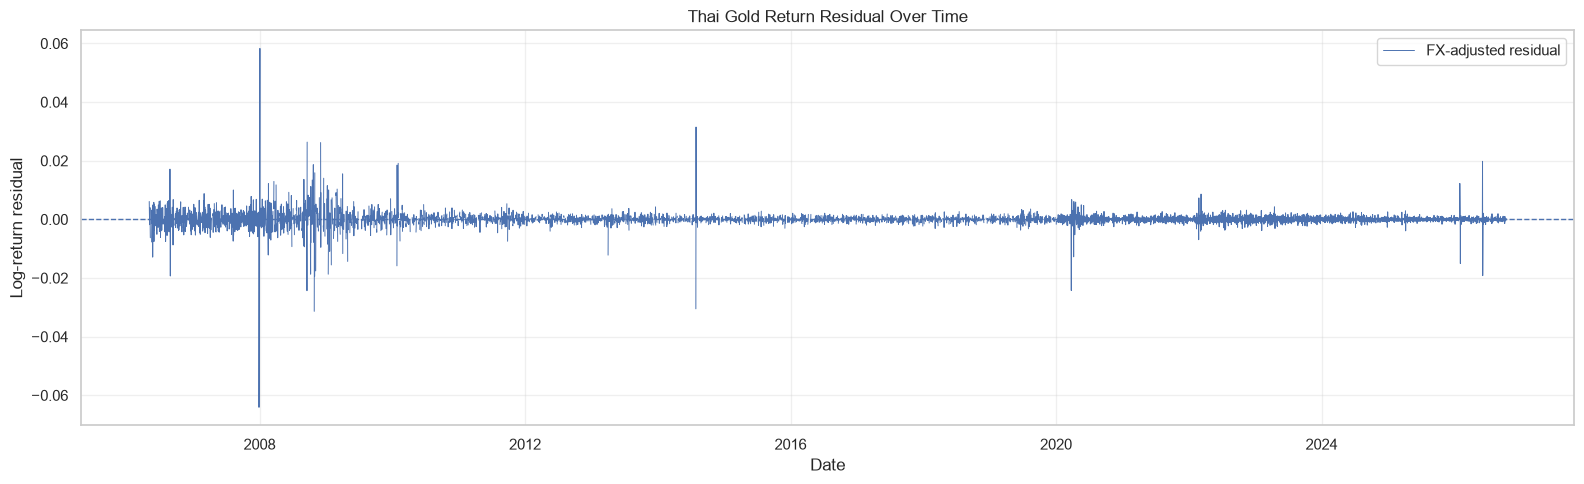

In [131]:

df_plot = df_features.copy()

date_col = (
    "date" if "date" in df_plot.columns
    else "timestamp_parsed"
)

df_plot[date_col] = pd.to_datetime(df_plot[date_col])

df_plot = df_plot.sort_values(date_col)

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    df_plot[date_col],
    df_plot["fx_adjusted_residual"],
    linewidth=0.7,
    label="FX-adjusted residual"
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title("Thai Gold Return Residual Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Log-return residual")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

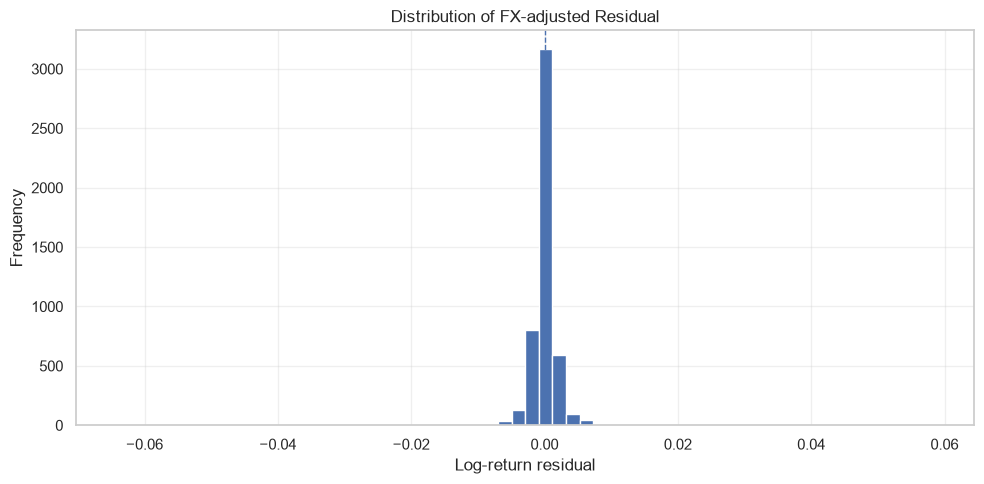

,fx_adjusted_residual
count,4935.000000
mean,0.000018
std,0.002637
min,-0.064106
25%,-0.000680
50%,0.000000
75%,0.000679
max,0.058304


In [132]:
residual = df_plot["fx_adjusted_residual"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(residual, bins=60)

ax.axvline(0, linestyle="--", linewidth=1)

ax.set_title("Distribution of FX-adjusted Residual")
ax.set_xlabel("Log-return residual")
ax.set_ylabel("Frequency")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

display(residual.describe().to_frame("fx_adjusted_residual"))

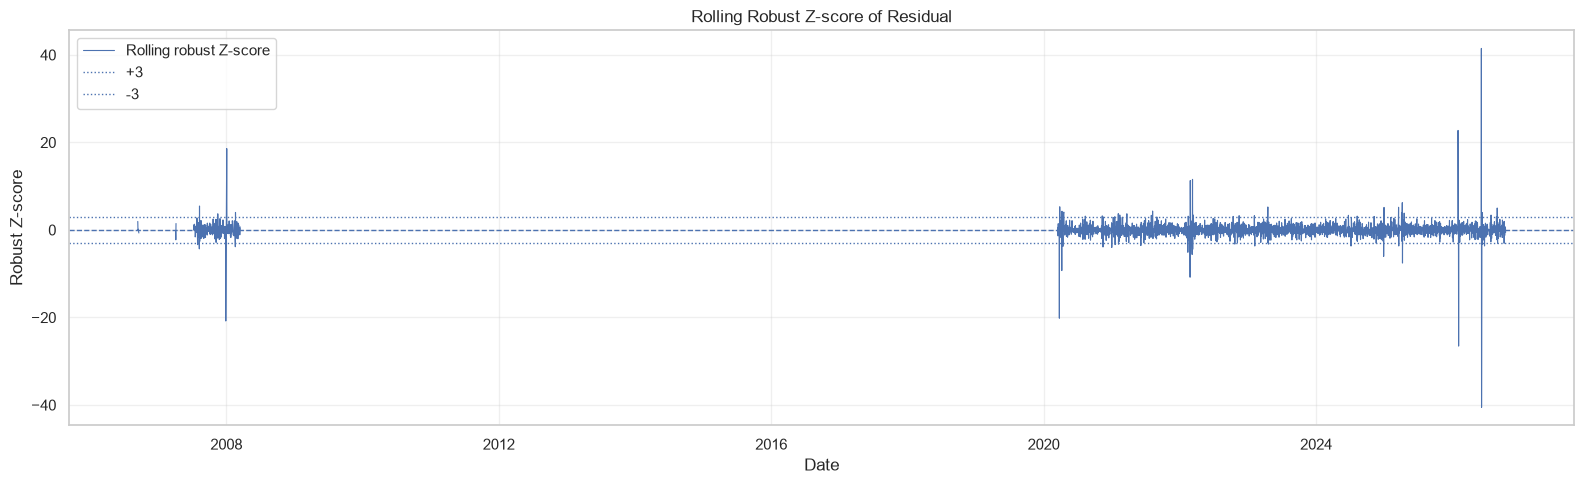

In [133]:
fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    df_plot[date_col],
    df_plot["residual_robust_z_60d"],
    linewidth=0.8,
    label="Rolling robust Z-score"
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.axhline(3, linestyle=":", linewidth=1, label="+3")
ax.axhline(-3, linestyle=":", linewidth=1, label="-3")

ax.set_title("Rolling Robust Z-score of Residual")
ax.set_xlabel("Date")
ax.set_ylabel("Robust Z-score")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()